# Setup

## Imports

In [1]:
from pathlib import Path
import os
import pandas as pd
import sys
from matplotlib import pyplot as plt
import seaborn as sns
from adjustText import adjust_text
from matplotlib.patches import Patch
from matplotlib.ticker import LogLocator, NullFormatter
import numpy as np



import hatfield_funcs as hf

# project root = one level up from notebooks so maybe more here
project_root = Path("../..").resolve()
sys.path.insert(0, str(project_root / "src"))

from biofilm_spectra.processing.spectral_matrix import to_spectral_matrix

from biofilm_spectra.processing.micasense import *
from my_extra_to_hatfield_funcs.io_funcs import *

In [2]:
plt.style.use("default")
%config InlineBackend.figure_format = 'retina'

In [3]:
CONTAINER_NAME = "wesa-fup-restricted-027817p"

if os.getenv("GA_STORAGE_ACCOUNT_NAME") is not None:
    # this is what gets used when using Azure cloud storage (GeoAnalytics)
    hf.config.configure_azure()
    hf.config.configure_data_root_path(CONTAINER_NAME)
else:
    raise Exception(
        "This notebook is configured to run in the cloud. "
        "Please set up your Azure storage account and container name."
    )


## Parameters

In [4]:
SITES = ["brunswick", "westham"]
SITE_COLORS = {
    "brunswick": "#0455FE",
    "westham": "#56E00A",
}
SITE_LABELS = {
    "brunswick": "Impact Area",
    "westham": "Westham Control Area",
}

PIGMENT_LIST = [
    "Peri",
    "Chlc2",
    "Fuco",
    "Ddx",
    "Allo",
    "Myxo",
    "Lut",
    "Zea",
    "Cant",
    "Chlb",
    "Chl_allo1",
    "Chl_allo2",
    "Chla",
    "DVCh-a",
    "Echi",
    "Phtb",
    "Phta",
    "Acar",
    "Beta",
]
FA_LIST = [
    "C6",
    "C8",
    "C10",
    "C11",
    "C12",
    "C13",
    "C14:0",  # Corrected from C14-0 to C14:0
    "C14:1",  # Corrected from C14-1 to C14:1
    "C15",
    "C15:1", # Corrected from C15-1 to C15:1
    "C16",
    "C16:1", # Corrected from C16-1 to C16:1
    "C17:0",
    "C17:1",
    "C18:0",
    "C18:1N9T",
    "C18:1N9C",
    "C18:2N6T",
    "C18:2N6C",
    "C20:0",
    "C18:3N6",
    "C20:1N9",
    "C18:3N3",
    "C21:0",
    "C20:2",
    "C22:0",
    "C20:3N6",
    "C22:1N9",
    "C20:3N3",
    "C23:0",
    "C20:4N6",
    "C22:2",
    "C24:0",
    "C20:5N3",
    "C24:1N9",
    "C22:6N3",
]

NORMALIZING_CHLA_COLUMN = "Chla + allomers"  #'Chla' #"Chla + DVCh-a + allomers" # Defined in the notebook to preprocess lab data

In [5]:
# Input paths

# Lab data
path_to_csv_for_lab_data = Path("data/processed/lab/lab_data_clean_new_units.csv")

In [6]:
# Output path
path_output_dir = Path('./outputs/lab_data')
path_output_dir.mkdir(parents=True, exist_ok=True)

# Read data

In [7]:
# Lab data (read both original unit file and converted file to gather some of them)
df_lab = read_df_from_csv(path_to_csv_for_lab_data, index_col=[0, 1, 2])

# Display first rows
df_lab.head()

Sample Total Dry Mass (g)  \
station_id round sample_type                              
B1         1     R                           124.920787   
           2     R                           102.318373   
B10        1     R                           113.372704   
           2     R                           135.840106   
B11        1     R                            68.488373   

                              Extraction Dry Mass (mg)  Peri (mg/g)  \
station_id round sample_type                                          
B1         1     R                               554.2     0.000130   
           2     R                               512.4     0.000207   
B10        1     R                               460.8     0.000159   
           2     R                               582.7     0.000217   
B11        1     R                               480.4     0.000083   

                              Chlc2 (mg/g)  Fuco (mg/g)  Ddx (mg/g)  \
station_id round sample_type                                          
B1         1     R                0.000126     0.004335    0.003132   
           2     R                0.000324     0.005283    0.004532   
B10        1     R                0.000414     0.005671    0.003579   
           2     R                0.000197     0.004817    0.003055   
B11        1     R                0.000451     0.006007    0.004110   

                              Allo (mg/g)  Myxo (mg/g)  Lut (mg/g)  \
station_id round sample_type                                         
B1         1     R               0.000217     0.000186    0.000786   
           2     R               0.000166     0.000192    0.001309   
B10        1     R               0.000381     0.000401    0.001142   
           2     R               0.000188     0.000174    0.000865   
B11        1     R               0.000346     0.000399    0.001323   

                              Zea (mg/g)  ...  Chla + Phta (mg/m2)  \
station_id round sample_type              ...                        
B1         1     R              0.000417  ...            21.069444   
           2     R              0.000386  ...            29.742209   
B10        1     R              0.000503  ...            24.287064   
           2     R              0.000480  ...            24.723277   
B11        1     R              0.000442  ...            13.390684   

                              Chla + DVCh-a (mg/m2)  Chla + allomers (mg/m2)  \
station_id round sample_type                                                   
B1         1     R                        20.741812                23.610221   
           2     R                        32.747131                32.862033   
B10        1     R                        24.563158                28.366951   
           2     R                        24.615807                31.561095   
B11        1     R                        12.494966                17.099191   

                              Total FA (mg/m2)  Total SFA (mg/m2)  \
station_id round sample_type                                        
B1         1     R                  742.790704         351.340453   
           2     R                  611.590220         292.275597   
B10        1     R                  702.171236         392.603361   
           2     R                  447.855542         253.079909   
B11        1     R                  299.768790         163.267016   

                              Total MUFA (mg/m2)  Total PUFA (mg/m2)  \
station_id round sample_type                                           
B1         1     R                    308.300381           83.149870   
           2     R                    212.089081          107.225541   
B10        1     R                    252.104152           57.463723   
           2     R                    169.437042           25.338591   
B11        1     R                    117.048769           19.453006   

                              Total Omega-3 PUFA (mg/m2)  \
station_id round sample_type

# Analysis (sample_type == R only)


In [8]:
df_lab_r = df_lab.xs("R", level="sample_type")
df_lab_r

Sample Total Dry Mass (g)  Extraction Dry Mass (mg)  \
station_id round                                                        
B1         1                     124.920787                     554.2   
           2                     102.318373                     512.4   
B10        1                     113.372704                     460.8   
           2                     135.840106                     582.7   
B11        1                      68.488373                     480.4   
...                                     ...                       ...   
W7         2                     161.405260                     578.8   
W8         1                     198.150482                     418.1   
           2                     176.165261                     502.5   
W9         1                     216.772129                     450.8   
           2                     129.403085                     419.4   

                  Peri (mg/g)  Chlc2 (mg/g)  Fuco (mg/g)  Ddx (mg/g)  \
station_id round                                                       
B1         1         0.000130      0.000126     0.004335    0.003132   
           2         0.000207      0.000324     0.005283    0.004532   
B10        1         0.000159      0.000414     0.005671    0.003579   
           2         0.000217      0.000197     0.004817    0.003055   
B11        1         0.000083      0.000451     0.006007    0.004110   
...                       ...           ...          ...         ...   
W7         2         0.000021      0.000225     0.002586    0.001472   
W8         1         0.000070      0.000113     0.002703    0.001780   
           2         0.000121      0.000059     0.003292    0.002312   
W9         1         0.000052      0.000092     0.002689    0.001740   
           2         0.000147      0.000115     0.003339    0.002283   

                  Allo (mg/g)  Myxo (mg/g)  Lut (mg/g)  Zea (mg/g)  ...  \
station_id round                                                    ...   
B1         1         0.000217     0.000186    0.000786    0.000417  ...   
           2         0.000166     0.000192    0.001309    0.000386  ...   
B10        1         0.000381     0.000401    0.001142    0.000503  ...   
           2         0.000188     0.000174    0.000865    0.000480  ...   
B11        1         0.000346     0.000399    0.001323    0.000442  ...   
...                       ...          ...         ...         ...  ...   
W7         2         0.000065     0.000076    0.000228    0.000119  ...   
W8         1         0.000078     0.000128    0.000293    0.000125  ...   
           2         0.000128     0.000139    0.000597    0.000175  ...   
W9         1         0.000041     0.000032    0.000444    0.000132  ...   
           2         0.000068     0.000023    0.000619    0.000189  ...   

                  Chla + Phta (mg/m2)  Chla + DVCh-a (mg/m2)  \
station_id round                                               
B1         1                21.069444              20.741812   
           2                29.742209              32.747131   
B10        1                24.287064              24.563158   
           2                24.723277              24.615807   
B11        1                13.390684              12.494966   
...                               ...                    ...   
W7         2                17.133767              16.507460   
W8         1                19.511990              20.404125   
           2                19.549582              19.834378   
W9         1                22.929684              23.449593   
           2                13.436813              13.685765   

                  Chla + allomers (mg/m2)  Total FA (mg/m2)  \
station_id round                                              
B1         1                    23.610221        742.790704   
           2                    32.862033        611.590220   
B10        1                    28.366951        702.171236   
       

## Boxplots

In [9]:
def draw_boxplots(
    df,
    variables,
    round_number,
    title=None,
    figsize=(12, 8),
    sites=SITES,
    site_colors=SITE_COLORS,
    site_labels=SITE_LABELS,
    y_scale="linear",
    show_y_grid=True,
    annotate_outliers=True,
    outlier_fontsize=8,
    variable_labels=None,
    y_label=None,
    share_y=True,
):
    """
    Draw grouped boxplots for one or more survey rounds.

    When multiple rounds are supplied, the plots are stacked vertically.
    They share the x-axis, and x-axis labels are displayed only on the
    bottom panel.

    Parameters
    ----------
    df : pandas.DataFrame
        Input DataFrame. Its index must contain "round" and "station_id".
    variables : list of str
        Variables to plot.
    round_number : int or sequence of int
        One round, such as 1, or multiple rounds, such as [1, 2].
    title : str, optional
        Overall figure title.
    figsize : tuple, default (12, 8)
        Size of the complete figure.
    sites : sequence
        Site identifiers in the desired plotting order.
    site_colors : dict or sequence
        Colors associated with the sites.
    site_labels : dict or sequence, optional
        Display labels associated with the sites.
    y_scale : {"linear", "log", "symlog"}, default "linear"
        Y-axis scale.
    show_y_grid : bool, default True
        Whether to display horizontal grid lines.
    annotate_outliers : bool, default True
        Whether to annotate outliers with station IDs.
    outlier_fontsize : float, default 8
        Font size for outlier annotations.
    variable_labels : list of str, optional
        Labels to display along the x-axis.
    y_label : str, optional
        Common y-axis label.
    share_y : bool, default True
        Whether all round panels use the same y-axis limits.
    """

    # ------------------------------------------------------------------
    # Normalize round_number to a list
    # ------------------------------------------------------------------
    if isinstance(round_number, (list, tuple)):
        round_numbers = list(round_number)
    else:
        round_numbers = [round_number]

    if not round_numbers:
        raise ValueError("At least one round number must be provided.")

    if len(set(round_numbers)) != len(round_numbers):
        raise ValueError("Duplicate round numbers were provided.")

    # ------------------------------------------------------------------
    # Validate inputs
    # ------------------------------------------------------------------
    if not variables:
        raise ValueError("At least one variable must be provided.")

    valid_scales = {
        "linear",
        "log",
        "symlog",
    }

    if y_scale not in valid_scales:
        raise ValueError(
            f"y_scale must be one of {valid_scales}; received {y_scale!r}."
        )

    if variable_labels is not None:
        if len(variable_labels) != len(variables):
            raise ValueError(
                "The length of variable_labels must match the length "
                f"of variables. Received {len(variable_labels)} labels "
                f"for {len(variables)} variables."
            )

    if sites is None:
        if isinstance(site_colors, dict):
            sites = list(site_colors)
        else:
            raise ValueError(
                "Provide 'sites', or provide 'site_colors' as a "
                "dictionary whose keys are the site identifiers."
            )

    sites = list(sites)

    if site_colors is None:
        raise ValueError("'site_colors' must be provided.")

    missing_variables = [
        variable for variable in variables if variable not in df.columns
    ]

    if missing_variables:
        raise KeyError(
            "The following variables were not found in the DataFrame: "
            f"{missing_variables}"
        )

    required_index_levels = {
        "round",
        "station_id",
    }

    available_index_levels = set(df.index.names)

    missing_index_levels = required_index_levels - available_index_levels

    if missing_index_levels:
        raise KeyError(
            "The DataFrame index is missing the following required "
            f"level(s): {sorted(missing_index_levels)}"
        )

    # ------------------------------------------------------------------
    # Create color and label dictionaries
    # ------------------------------------------------------------------
    if isinstance(site_colors, dict):
        color_map = site_colors.copy()
    else:
        color_map = dict(zip(sites, site_colors))

    if site_labels is None:
        label_map = {site: str(site) for site in sites}
    elif isinstance(site_labels, dict):
        label_map = site_labels.copy()
    else:
        label_map = dict(zip(sites, site_labels))

    color_map.setdefault(
        "Unknown",
        "lightgray",
    )

    label_map.setdefault(
        "Unknown",
        "Unknown",
    )

    # ------------------------------------------------------------------
    # Prepare the data for every round
    # ------------------------------------------------------------------
    round_data = []
    all_observed_sites = set()

    for current_round in round_numbers:
        try:
            df_filtered = df.xs(
                current_round,
                level="round",
            )
        except KeyError as error:
            raise KeyError(
                f"Round {current_round!r} was not found in the DataFrame."
            ) from error

        df_plot = df_filtered[variables].copy()

        # Preserve station IDs for annotations
        df_plot["station_id"] = df_plot.index.get_level_values("station_id").astype(str)

        # Assign each station to a site
        df_plot["site"] = df_plot["station_id"].map(
            lambda station_id: next(
                (site for site in sites if station_id.startswith(str(site)[0].upper())),
                "Unknown",
            )
        )

        all_observed_sites.update(df_plot["site"].dropna())

        # Reshape from wide to long
        df_long = df_plot.melt(
            id_vars=[
                "station_id",
                "site",
            ],
            value_vars=variables,
            var_name="variable",
            value_name="value",
        ).dropna(subset=["value"])

        if df_long.empty:
            raise ValueError(
                f"No non-missing observations were found for round {current_round}."
            )

        # Calculate outliers within each variable-site group
        grouped_values = df_long.groupby(
            [
                "variable",
                "site",
            ],
            observed=True,
        )["value"]

        q1 = grouped_values.transform(lambda values: values.quantile(0.25))

        q3 = grouped_values.transform(lambda values: values.quantile(0.75))

        iqr = q3 - q1

        lower_limit = q1 - 1.5 * iqr
        upper_limit = q3 + 1.5 * iqr

        outlier_mask = (df_long["value"] < lower_limit) | (
            df_long["value"] > upper_limit
        )

        df_outliers = df_long.loc[outlier_mask].copy()

        round_data.append(
            {
                "round": current_round,
                "data": df_long,
                "outliers": df_outliers,
            }
        )

    # ------------------------------------------------------------------
    # Determine the common site order
    # ------------------------------------------------------------------
    site_order = [site for site in sites if site in all_observed_sites]

    if "Unknown" in all_observed_sites:
        site_order.append("Unknown")

    if not site_order:
        raise ValueError("No site data were found for the selected rounds.")

    missing_colors = [site for site in site_order if site not in color_map]

    if missing_colors:
        raise KeyError(
            f"No colors were provided for the following sites: {missing_colors}"
        )

    # ------------------------------------------------------------------
    # Validate values for the selected y-axis scale
    # ------------------------------------------------------------------
    zero_count = sum(int((item["data"]["value"] == 0).sum()) for item in round_data)

    negative_count = sum(int((item["data"]["value"] < 0).sum()) for item in round_data)

    if y_scale == "log" and (zero_count or negative_count):
        raise ValueError(
            "A true logarithmic scale cannot display zero or "
            f"negative values. Found {zero_count} zero value(s) and "
            f"{negative_count} negative value(s). Use "
            "y_scale='symlog' to retain zero values."
        )

    if y_scale == "symlog" and negative_count:
        raise ValueError(
            f"Found {negative_count} negative value(s). Although "
            "symlog can display negative values, negative pigment "
            "measurements should be reviewed before plotting."
        )

    # Determine a common symlog threshold when y-axes are shared
    positive_minimum = None

    if y_scale == "symlog":
        positive_minimums = []

        for item in round_data:
            positive_values = item["data"].loc[
                item["data"]["value"] > 0,
                "value",
            ]

            if not positive_values.empty:
                positive_minimums.append(positive_values.min())

        if positive_minimums:
            positive_minimum = min(positive_minimums)

    # ------------------------------------------------------------------
    # Prepare x-axis labels
    # ------------------------------------------------------------------
    if variable_labels is None:
        displayed_variable_labels = [
            (variable.rsplit(" (", 1)[0] if " (" in variable else variable)
            for variable in variables
        ]
    else:
        displayed_variable_labels = list(variable_labels)

    # Determine the y-axis label
    if y_label is not None:
        displayed_y_label = y_label
    else:
        first_variable = variables[0]

        if "(" in first_variable:
            displayed_y_label = first_variable.rsplit("(", 1)[-1].rstrip(")")
        else:
            displayed_y_label = "Value"

    # ------------------------------------------------------------------
    # Create vertically stacked axes
    # ------------------------------------------------------------------
    number_of_rounds = len(round_numbers)

    fig, axes = plt.subplots(
        nrows=number_of_rounds,
        ncols=1,
        figsize=figsize,
        sharex=True,
        sharey=share_y,
        squeeze=False,
    )

    axes = axes[:, 0]

    box_width = 0.8
    minor_subs = (
        2,
        3,
        4,
        5,
        6,
        7,
        8,
        9,
    )

    # Save annotation information for each axis
    annotation_groups = []

    # ------------------------------------------------------------------
    # Draw each round
    # ------------------------------------------------------------------
    for panel_index, (
        ax,
        item,
    ) in enumerate(zip(axes, round_data)):
        current_round = item["round"]
        df_long = item["data"]
        df_outliers = item["outliers"]

        # Draw boxplots without default outlier markers
        sns.boxplot(
            data=df_long,
            x="variable",
            y="value",
            hue="site",
            order=variables,
            hue_order=site_order,
            palette=color_map,
            width=box_width,
            dodge=True,
            showfliers=False,
            legend=False,
            ax=ax,
        )

        # Draw filled, site-colored outlier points
        if not df_outliers.empty:
            sns.stripplot(
                data=df_outliers,
                x="variable",
                y="value",
                hue="site",
                order=variables,
                hue_order=site_order,
                palette=color_map,
                dodge=True,
                jitter=False,
                marker="o",
                size=5.5,
                edgecolor="black",
                linewidth=0.7,
                alpha=0.9,
                legend=False,
                ax=ax,
                zorder=4,
            )

        # --------------------------------------------------------------
        # Configure the y-axis scale
        # --------------------------------------------------------------
        actual_y_scale = y_scale

        if y_scale == "linear":
            ax.set_yscale("linear")

        elif y_scale == "log":
            ax.set_yscale(
                "log",
                base=10,
            )

            ax.yaxis.set_minor_locator(
                LogLocator(
                    base=10,
                    subs=minor_subs,
                    numticks=100,
                )
            )

            ax.yaxis.set_minor_formatter(NullFormatter())

        elif y_scale == "symlog":
            if share_y:
                linthresh = positive_minimum
            else:
                positive_values = df_long.loc[
                    df_long["value"] > 0,
                    "value",
                ]

                if positive_values.empty:
                    linthresh = None
                else:
                    linthresh = positive_values.min()

            if linthresh is None:
                ax.set_yscale("linear")

                actual_y_scale = "linear"

            else:
                ax.set_yscale(
                    "symlog",
                    base=10,
                    linthresh=linthresh,
                    subs=minor_subs,
                )

                ax.yaxis.get_minor_locator().set_params(subs=minor_subs)

                ax.yaxis.set_minor_formatter(NullFormatter())

        # Add vertical room for annotations
        ax.margins(y=0.1)

        # Prevent nonnegative linear/symlog plots extending below zero
        if actual_y_scale != "log" and (df_long["value"] >= 0).all():
            ax.set_ylim(bottom=0)

        # --------------------------------------------------------------
        # Configure grid lines
        # --------------------------------------------------------------
        ax.set_axisbelow(True)

        if show_y_grid:
            ax.grid(
                visible=True,
                axis="y",
                which="major",
                linestyle="--",
                linewidth=0.8,
                color="gray",
                alpha=0.5,
            )

            if actual_y_scale in {
                "log",
                "symlog",
            }:
                ax.grid(
                    visible=True,
                    axis="y",
                    which="minor",
                    linestyle=":",
                    linewidth=0.6,
                    color="gray",
                    alpha=0.4,
                )
        else:
            ax.grid(
                visible=False,
                axis="y",
                which="both",
            )

        # --------------------------------------------------------------
        # Round label
        # --------------------------------------------------------------
        if number_of_rounds > 1:
            ax.set_title(
                f"Round {current_round}",
                loc="left",
                fontsize=10,
                fontweight="bold",
            )
        elif title is None:
            ax.set_title(f"Round {current_round}")

        ax.set_xlabel("")

        # Use one common y-axis label for multiple panels
        if number_of_rounds == 1:
            ax.set_ylabel(displayed_y_label)
        else:
            ax.set_ylabel("")

        # --------------------------------------------------------------
        # Create outlier annotation text
        # --------------------------------------------------------------
        outlier_texts = []
        outlier_x_positions = []
        outlier_y_positions = []

        if annotate_outliers and not df_outliers.empty:
            number_of_sites = len(site_order)

            site_offsets = {
                site: ((site_index + 0.5) * box_width / number_of_sites - box_width / 2)
                for site_index, site in enumerate(site_order)
            }

            variable_positions = {
                variable: index for index, variable in enumerate(variables)
            }

            for _, row in df_outliers.iterrows():
                x_position = (
                    variable_positions[row["variable"]] + site_offsets[row["site"]]
                )

                y_position = row["value"]

                outlier_x_positions.append(x_position)

                outlier_y_positions.append(y_position)

                text = ax.text(
                    x_position,
                    y_position,
                    str(row["station_id"]),
                    ha="center",
                    va="bottom",
                    fontsize=outlier_fontsize,
                    color="black",
                    zorder=5,
                )

                outlier_texts.append(text)

        annotation_groups.append(
            {
                "ax": ax,
                "texts": outlier_texts,
                "x": outlier_x_positions,
                "y": outlier_y_positions,
            }
        )

        # Hide x-axis labels on every panel except the bottom one
        is_bottom_panel = panel_index == number_of_rounds - 1

        ax.tick_params(
            axis="x",
            labelbottom=is_bottom_panel,
        )

    # ------------------------------------------------------------------
    # Configure the shared x-axis on the bottom panel only
    # ------------------------------------------------------------------
    bottom_ax = axes[-1]

    bottom_ax.set_xticks(range(len(variables)))

    bottom_ax.set_xticklabels(displayed_variable_labels)

    if len(variables) > 4:
        plt.setp(
            bottom_ax.get_xticklabels(),
            rotation=45,
            ha="right",
            rotation_mode="anchor",
        )

    # Common y-axis label for multiple panels
    if number_of_rounds > 1:
        fig.supylabel(displayed_y_label)

    # ------------------------------------------------------------------
    # Create the common site legend
    # ------------------------------------------------------------------
    legend_handles = [
        Patch(
            facecolor=color_map[site],
            edgecolor="black",
            label=label_map.get(
                site,
                site,
            ),
        )
        for site in site_order
    ]

    fig.legend(
        handles=legend_handles,
        title="Survey Area",
        loc="lower center",
        bbox_to_anchor=(
            0.5,
            0.01,
        ),
        ncol=max(
            1,
            len(legend_handles),
        ),
        frameon=False,
    )

    # Overall title for multiple rounds
    if title:
        if number_of_rounds > 1:
            fig.suptitle(
                title,
                y=0.98
            )

        else:
            axes[0].set_title(title)

    # Finalize layout before adjusting annotations
    top_position = (
        1
        if title and number_of_rounds > 1
        else 1
    )

    fig.tight_layout(
        rect=(
            0.02,
            0.05,
            1,
            top_position,
        )
    )

    fig.canvas.draw()

    # ------------------------------------------------------------------
    # Automatically adjust annotations independently on each panel
    # ------------------------------------------------------------------
    for annotation_group in annotation_groups:
        texts = annotation_group["texts"]

        if not texts:
            continue

        adjust_text(
            texts,
            x=annotation_group["x"],
            y=annotation_group["y"],
            target_x=annotation_group["x"],
            target_y=annotation_group["y"],
            ax=annotation_group["ax"],
            expand=(1.2, 1.4),
            force_text=(0.2, 0.3),
            force_static=(0.1, 0.2),
            force_pull=(0.01, 0.02),
            force_explode=(0.1, 0.4),
            max_move=(8, 20),
            ensure_inside_axes=True,
            prevent_crossings=True,
            min_arrow_len=4,
            arrowprops={
                "arrowstyle": "-",
                "color": "0.35",
                "linewidth": 0.7,
                "alpha": 0.8,
            },
        )

    plt.show()

    if number_of_rounds == 1:
        return fig, axes[0]

    return fig, axes


In [10]:
def draw_boxplots_2(
    df,
    variables,
    round_number,
    title=None,
    figsize=(12, 8),
    sites=SITES,
    site_colors=SITE_COLORS,
    site_labels=SITE_LABELS,
    y_scale="linear",
    show_y_grid=True,
    annotate_outliers=True,
    outlier_fontsize=8,
    variable_labels=None,
    y_label=None,
    share_y=True,
    round_layout="vertical",
    round_separator=True,
    round_separator_kwargs=None,
    show_x_tick_labels=True,
):
    """
    Draw grouped boxplots for one or more survey rounds.

    Parameters
    ----------
    round_layout : {"vertical", "horizontal"}, default "vertical"
        - "vertical": existing behavior (one row per round).
        - "horizontal": one axis where rounds are separated across x positions.
    round_separator : bool, default True
        Whether to draw vertical separators between rounds in horizontal layout.
    round_separator_kwargs : dict, optional
        Styling kwargs passed to matplotlib Axes.axvline for round separators.
    show_x_tick_labels : bool, default True
        Whether to display x-axis tick labels in horizontal layout.
    """

    # ------------------------------------------------------------------
    # Normalize round_number and validate the layout option
    # ------------------------------------------------------------------
    if isinstance(round_number, (list, tuple)):
        round_numbers = list(round_number)
    else:
        round_numbers = [round_number]

    if not round_numbers:
        raise ValueError("At least one round number must be provided.")

    if len(set(round_numbers)) != len(round_numbers):
        raise ValueError("Duplicate round numbers were provided.")

    valid_layouts = {"vertical", "horizontal"}
    if round_layout not in valid_layouts:
        raise ValueError(
            f"round_layout must be one of {valid_layouts}; received {round_layout!r}."
        )

    # ------------------------------------------------------------------
    # Keep existing behavior for vertical layout (or single round)
    # ------------------------------------------------------------------
    if round_layout == "vertical" or len(round_numbers) == 1:
        return draw_boxplots(
            df=df,
            variables=variables,
            round_number=round_number,
            title=title,
            figsize=figsize,
            sites=sites,
            site_colors=site_colors,
            site_labels=site_labels,
            y_scale=y_scale,
            show_y_grid=show_y_grid,
            annotate_outliers=annotate_outliers,
            outlier_fontsize=outlier_fontsize,
            variable_labels=variable_labels,
            y_label=y_label,
            share_y=share_y
        )

    # ------------------------------------------------------------------
    # Validate inputs for horizontal layout
    # ------------------------------------------------------------------
    if not variables:
        raise ValueError("At least one variable must be provided.")

    valid_scales = {"linear", "log", "symlog"}
    if y_scale not in valid_scales:
        raise ValueError(
            f"y_scale must be one of {valid_scales}; received {y_scale!r}."
        )

    if variable_labels is not None and len(variable_labels) != len(variables):
        raise ValueError(
            "The length of variable_labels must match the length "
            f"of variables. Received {len(variable_labels)} labels "
            f"for {len(variables)} variables."
        )

    if sites is None:
        if isinstance(site_colors, dict):
            sites = list(site_colors)
        else:
            raise ValueError(
                "Provide 'sites', or provide 'site_colors' as a "
                "dictionary whose keys are the site identifiers."
            )

    sites = list(sites)

    if site_colors is None:
        raise ValueError("'site_colors' must be provided.")

    missing_variables = [variable for variable in variables if variable not in df.columns]
    if missing_variables:
        raise KeyError(
            "The following variables were not found in the DataFrame: "
            f"{missing_variables}"
        )

    required_index_levels = {"round", "station_id"}
    available_index_levels = set(df.index.names)
    missing_index_levels = required_index_levels - available_index_levels
    if missing_index_levels:
        raise KeyError(
            "The DataFrame index is missing the following required "
            f"level(s): {sorted(missing_index_levels)}"
        )

    # ------------------------------------------------------------------
    # Create color and label dictionaries
    # ------------------------------------------------------------------
    if isinstance(site_colors, dict):
        color_map = site_colors.copy()
    else:
        color_map = dict(zip(sites, site_colors))

    if site_labels is None:
        label_map = {site: str(site) for site in sites}
    elif isinstance(site_labels, dict):
        label_map = site_labels.copy()
    else:
        label_map = dict(zip(sites, site_labels))

    color_map.setdefault("Unknown", "lightgray")
    label_map.setdefault("Unknown", "Unknown")

    # ------------------------------------------------------------------
    # Prepare x labels
    # ------------------------------------------------------------------
    if variable_labels is None:
        displayed_variable_labels = [
            (variable.rsplit(" (", 1)[0] if " (" in variable else variable)
            for variable in variables
        ]
    else:
        displayed_variable_labels = list(variable_labels)

    if y_label is not None:
        displayed_y_label = y_label
    else:
        first_variable = variables[0]
        if "(" in first_variable:
            displayed_y_label = first_variable.rsplit("(", 1)[-1].rstrip(")")
        else:
            displayed_y_label = "Value"

    # ------------------------------------------------------------------
    # Build per-round long data and outlier tables
    # ------------------------------------------------------------------
    all_observed_sites = set()
    all_round_long = []
    all_round_outliers = []

    for current_round in round_numbers:
        try:
            df_filtered = df.xs(current_round, level="round")
        except KeyError as error:
            raise KeyError(
                f"Round {current_round!r} was not found in the DataFrame."
            ) from error

        df_plot = df_filtered[variables].copy()
        df_plot["station_id"] = df_plot.index.get_level_values("station_id").astype(str)

        df_plot["site"] = df_plot["station_id"].map(
            lambda station_id: next(
                (site for site in sites if station_id.startswith(str(site)[0].upper())),
                "Unknown",
            )
        )

        all_observed_sites.update(df_plot["site"].dropna())

        df_long = df_plot.melt(
            id_vars=["station_id", "site"],
            value_vars=variables,
            var_name="variable",
            value_name="value",
        ).dropna(subset=["value"])

        if df_long.empty:
            raise ValueError(
                f"No non-missing observations were found for round {current_round}."
            )

        df_long["round"] = current_round
        df_long["round_variable"] = df_long["variable"].map(
            lambda variable: f"round_{current_round}__{variable}"
        )

        grouped_values = df_long.groupby(["variable", "site"], observed=True)["value"]
        q1 = grouped_values.transform(lambda values: values.quantile(0.25))
        q3 = grouped_values.transform(lambda values: values.quantile(0.75))
        iqr = q3 - q1

        lower_limit = q1 - 1.5 * iqr
        upper_limit = q3 + 1.5 * iqr
        outlier_mask = (df_long["value"] < lower_limit) | (df_long["value"] > upper_limit)

        df_outliers = df_long.loc[outlier_mask].copy()

        all_round_long.append(df_long)
        all_round_outliers.append(df_outliers)

    site_order = [site for site in sites if site in all_observed_sites]
    if "Unknown" in all_observed_sites:
        site_order.append("Unknown")

    if not site_order:
        raise ValueError("No site data were found for the selected rounds.")

    missing_colors = [site for site in site_order if site not in color_map]
    if missing_colors:
        raise KeyError(
            f"No colors were provided for the following sites: {missing_colors}"
        )

    df_long_all = pd.concat(all_round_long, ignore_index=True)
    df_outliers_all = pd.concat(all_round_outliers, ignore_index=True)

    zero_count = int((df_long_all["value"] == 0).sum())
    negative_count = int((df_long_all["value"] < 0).sum())

    if y_scale == "log" and (zero_count or negative_count):
        raise ValueError(
            "A true logarithmic scale cannot display zero or "
            f"negative values. Found {zero_count} zero value(s) and "
            f"{negative_count} negative value(s). Use "
            "y_scale='symlog' to retain zero values."
        )

    if y_scale == "symlog" and negative_count:
        raise ValueError(
            f"Found {negative_count} negative value(s). Although "
            "symlog can display negative values, negative pigment "
            "measurements should be reviewed before plotting."
        )

    positive_minimum = None
    if y_scale == "symlog":
        positive_values = df_long_all.loc[df_long_all["value"] > 0, "value"]
        if not positive_values.empty:
            positive_minimum = positive_values.min()

    # ------------------------------------------------------------------
    # Build x order as round blocks laid out left-to-right
    # ------------------------------------------------------------------
    x_order = []
    x_ticklabels = []

    for current_round in round_numbers:
        for variable, variable_label in zip(variables, displayed_variable_labels):
            x_order.append(f"round_{current_round}__{variable}")
            x_ticklabels.append(variable_label)

    fig, ax = plt.subplots(figsize=figsize)

    box_width = 0.8
    minor_subs = (2, 3, 4, 5, 6, 7, 8, 9)

    sns.boxplot(
        data=df_long_all,
        x="round_variable",
        y="value",
        hue="site",
        order=x_order,
        hue_order=site_order,
        palette=color_map,
        width=box_width,
        dodge=True,
        showfliers=False,
        legend=False,
        ax=ax,
    )

    if not df_outliers_all.empty:
        sns.stripplot(
            data=df_outliers_all,
            x="round_variable",
            y="value",
            hue="site",
            order=x_order,
            hue_order=site_order,
            palette=color_map,
            dodge=True,
            jitter=False,
            marker="o",
            size=5.5,
            edgecolor="black",
            linewidth=0.7,
            alpha=0.9,
            legend=False,
            ax=ax,
            zorder=4,
        )

    # ------------------------------------------------------------------
    # Configure y scale
    # ------------------------------------------------------------------
    actual_y_scale = y_scale

    if y_scale == "linear":
        ax.set_yscale("linear")

    elif y_scale == "log":
        ax.set_yscale("log", base=10)
        ax.yaxis.set_minor_locator(LogLocator(base=10, subs=minor_subs, numticks=100))
        ax.yaxis.set_minor_formatter(NullFormatter())

    elif y_scale == "symlog":
        if positive_minimum is None:
            ax.set_yscale("linear")
            actual_y_scale = "linear"
        else:
            ax.set_yscale("symlog", base=10, linthresh=positive_minimum, subs=minor_subs)
            ax.yaxis.get_minor_locator().set_params(subs=minor_subs)
            ax.yaxis.set_minor_formatter(NullFormatter())

    ax.margins(y=0.12)
    if actual_y_scale != "log" and (df_long_all["value"] >= 0).all():
        ax.set_ylim(bottom=0)

    # ------------------------------------------------------------------
    # Configure grid lines
    # ------------------------------------------------------------------
    ax.set_axisbelow(True)

    if show_y_grid:
        ax.grid(
            visible=True,
            axis="y",
            which="major",
            linestyle="--",
            linewidth=0.8,
            color="gray",
            alpha=0.5,
        )

        if actual_y_scale in {"log", "symlog"}:
            ax.grid(
                visible=True,
                axis="y",
                which="minor",
                linestyle=":",
                linewidth=0.6,
                color="gray",
                alpha=0.4,
            )
    else:
        ax.grid(visible=False, axis="y", which="both")

    # ------------------------------------------------------------------
    # X-axis labels and round separators / headers
    # ------------------------------------------------------------------
    ax.set_xticks(range(len(x_order)))

    if show_x_tick_labels:
        ax.set_xticklabels(x_ticklabels)

        if len(x_order) > 4:
            plt.setp(
                ax.get_xticklabels(),
                rotation=45,
                ha="right",
                rotation_mode="anchor",
            )
    else:
        ax.set_xticklabels(["" for _ in x_order])
        ax.tick_params(axis="x", length=0)

    # Draw separators between round blocks and place round labels above each block
    number_of_variables = len(variables)

    default_separator_kwargs = {
        "color": "0.35",
        "linestyle": "--",
        "linewidth": 1.0,
        "alpha": 0.9,
    }

    if round_separator_kwargs is not None:
        default_separator_kwargs.update(round_separator_kwargs)

    if round_separator:
        for split_index in range(1, len(round_numbers)):
            boundary_x = split_index * number_of_variables - 0.5
            ax.axvline(boundary_x, **default_separator_kwargs)

    y_round_label = 1.01
    for i, current_round in enumerate(round_numbers):
        start_x = i * number_of_variables
        end_x = (i + 1) * number_of_variables - 1
        center_x = (start_x + end_x) / 2

        ax.text(
            center_x,
            y_round_label,
            f"Round {current_round}",
            transform=ax.get_xaxis_transform(),
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
        )

    ax.set_xlabel("")
    ax.set_ylabel(displayed_y_label)

    # ------------------------------------------------------------------
    # Outlier labels in horizontal round layout
    # ------------------------------------------------------------------
    outlier_texts = []
    outlier_x_positions = []
    outlier_y_positions = []

    if annotate_outliers and not df_outliers_all.empty:
        number_of_sites = len(site_order)

        site_offsets = {
            site: ((site_index + 0.5) * box_width / number_of_sites - box_width / 2)
            for site_index, site in enumerate(site_order)
        }

        round_variable_positions = {
            round_variable: index for index, round_variable in enumerate(x_order)
        }

        for _, row in df_outliers_all.iterrows():
            x_position = round_variable_positions[row["round_variable"]] + site_offsets[row["site"]]
            y_position = row["value"]

            outlier_x_positions.append(x_position)
            outlier_y_positions.append(y_position)

            text = ax.annotate(
                str(row["station_id"]),
                xy=(x_position, y_position),
                xytext=(0, 4),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=outlier_fontsize,
                color="black",
                zorder=6,
                clip_on=False,
            )
            outlier_texts.append(text)

    # ------------------------------------------------------------------
    # Legend and title
    # ------------------------------------------------------------------
    legend_handles = [
        Patch(
            facecolor=color_map[site],
            edgecolor="black",
            label=label_map.get(site, site),
        )
        for site in site_order
    ]

    fig.legend(
        handles=legend_handles,
        title="Survey Area",
        loc="lower center",
        bbox_to_anchor=(0.5, 0.01),
        ncol=max(1, len(legend_handles)),
        frameon=False,
    )

    if title:
        ax.set_title(title, pad=24)

    fig.tight_layout(rect=(0.02, 0.05, 1, 1))
    fig.canvas.draw()


    return fig, ax


### Pigments

In [11]:
CORE_PIGMENTS = [
    "Chla + allomers",
    "Chla",
    "Chlb",
    "Fuco",
    "Ddx",
    "DVCh-a",
    "Zea",
]
CORE_PIGMENT_COMMUNITIES = {  # See TT2025 "A suite of 17 marker pigments..."
    "Chla + allomers": "Biofilm biomass",
    "Chla": "Biofilm biomass",
    "Chlb": "Green Algae",
    "Fuco": "Diatoms",
    "Ddx": "Diatoms",
    "DVCh-a": "Cyanobacteria",
    "Zea": "Cyanobacteria",
}
CORE_PIGMENT_FULL_NAMES = {
    "Chla + allomers": "Chlorophyll a (+ allomers)",
    "Chla": "Chlorophyll a",
    "Chlb": "Chlorophyll b",
    "Fuco": "Fucoxanthin",
    "Ddx": "Diadinoxanthin",
    "DVCh-a": "Divinyl Chlorophyll a",
    "Zea": "Zeaxanthin",
}

CORE_PIGMENT_FULL_LABELS = {}
for pigment, community in CORE_PIGMENT_COMMUNITIES.items():
    CORE_PIGMENT_FULL_LABELS[pigment] = f"{CORE_PIGMENT_FULL_NAMES[pigment]}\n({community})"


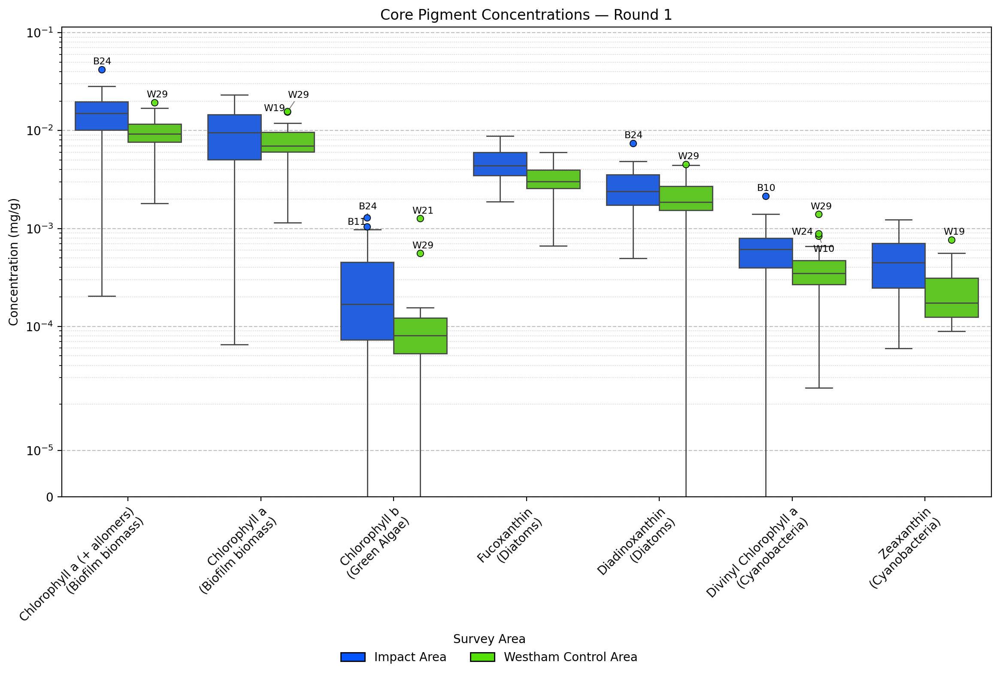

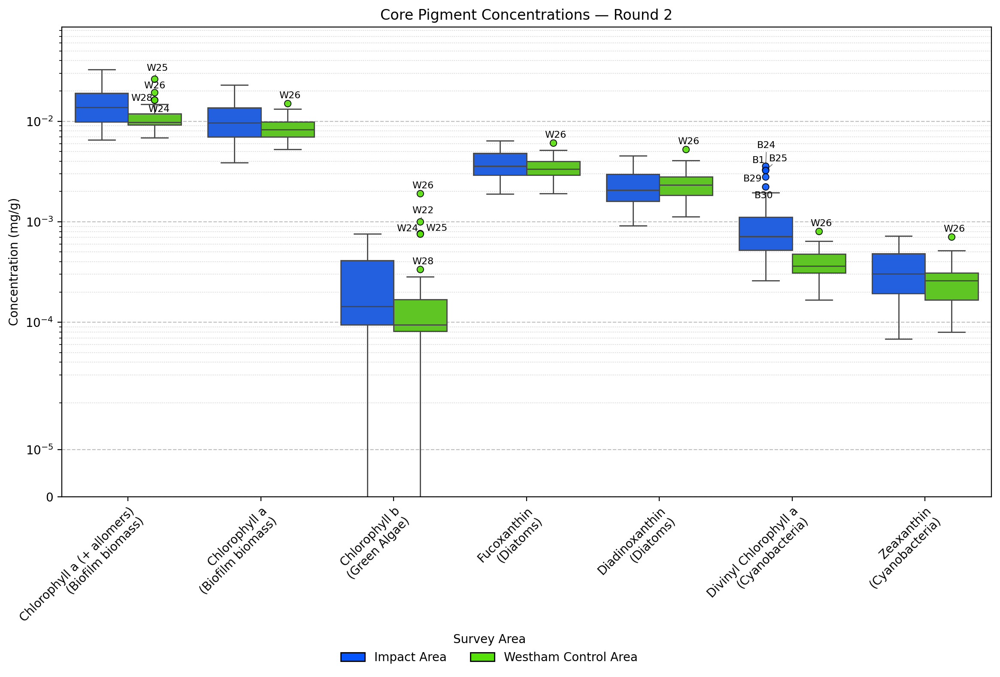

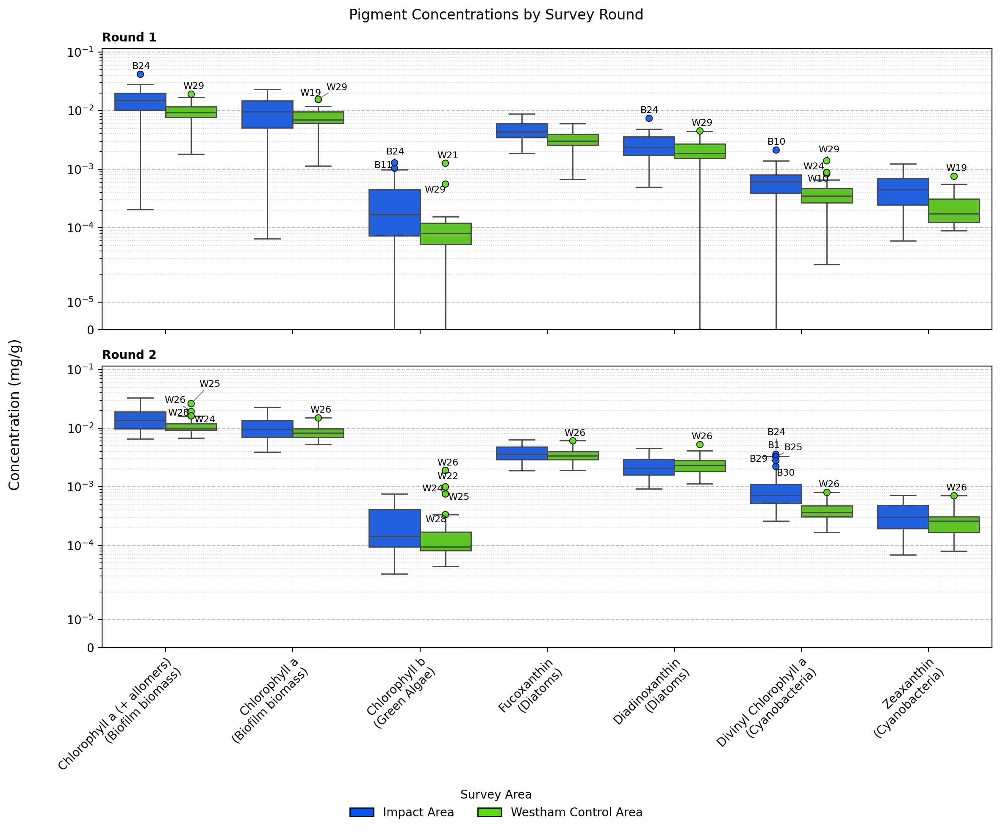

In [12]:
pigment_unit = 'mg/g' # or 'mg/m2'
core_pigment_columns = [
    pigment + f" ({pigment_unit})" for pigment in CORE_PIGMENT_COMMUNITIES.keys()
]

for round_number in [1, 2]:
    fig, ax = draw_boxplots(
        df_lab_r,
        core_pigment_columns,
        round_number=round_number,
        title=f"Core Pigment Concentrations \u2014 Round {round_number}",
        y_scale="symlog",
        annotate_outliers=True,
        variable_labels=CORE_PIGMENT_FULL_LABELS.values(),
        y_label=f"Concentration ({pigment_unit})"
    )
    path = path_output_dir / f"boxplots_core_pigments_round_{round_number}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")

fig, ax = draw_boxplots(
    df_lab_r,
    core_pigment_columns,
    round_number=[1, 2],
    title="Pigment Concentrations by Survey Round",
    figsize=(12, 10),
    y_scale="symlog",
    y_label=f"Concentration ({pigment_unit})",
    variable_labels=CORE_PIGMENT_FULL_LABELS.values(),
    show_y_grid=True,
    annotate_outliers=True,
)
path = path_output_dir / "boxplots_core_pigments_rounds_1_and_2.png"
fig.savefig(path, dpi=300, bbox_inches="tight")

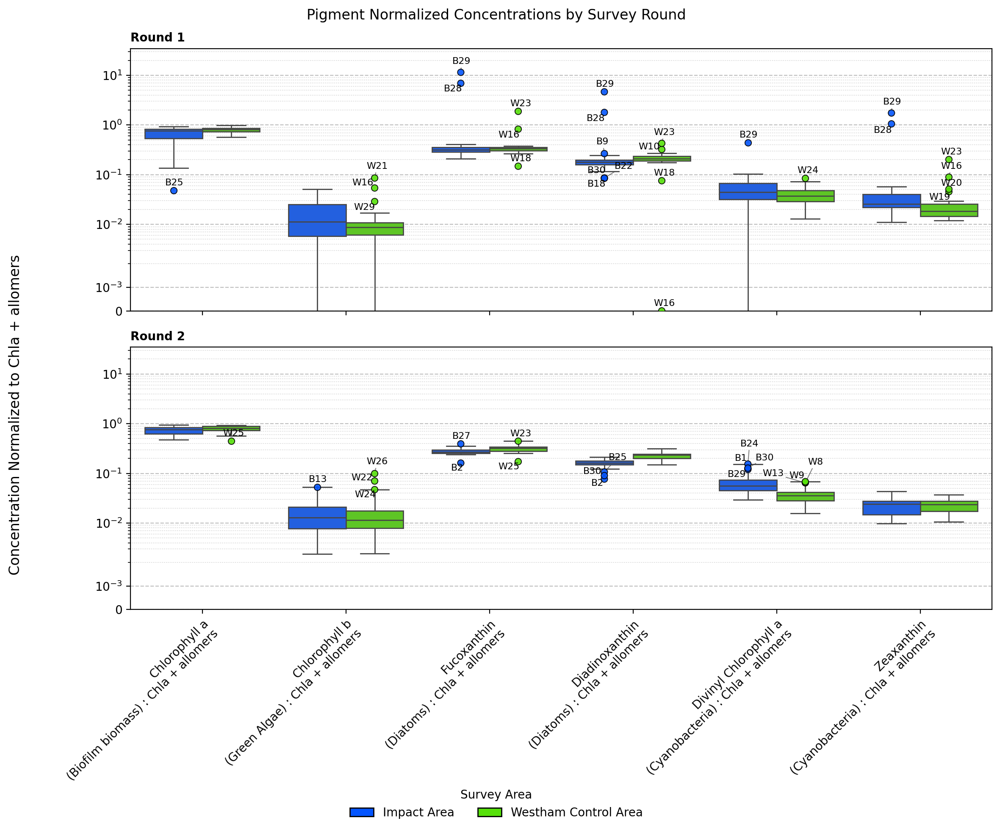

In [13]:
core_pigment_columns_norm = [
    f"{pigment} : {NORMALIZING_CHLA_COLUMN}" for pigment in CORE_PIGMENTS if pigment != NORMALIZING_CHLA_COLUMN
]
core_pigment_labels_norm = [
    f"{label} : {NORMALIZING_CHLA_COLUMN}"
    for label in CORE_PIGMENT_FULL_LABELS.values()
    if label != CORE_PIGMENT_FULL_LABELS.get(NORMALIZING_CHLA_COLUMN, '')
]

fig, ax = draw_boxplots(
    df_lab_r,
    core_pigment_columns_norm,
    round_number=[1, 2],
    title="Pigment Normalized Concentrations by Survey Round",
    figsize=(12, 10),
    y_scale="symlog",
    y_label=f"Concentration Normalized to {NORMALIZING_CHLA_COLUMN}",
    variable_labels=core_pigment_labels_norm,
    show_y_grid=True,
    annotate_outliers=True,
)
path = path_output_dir / "boxplots_core_pigments_normalized_rounds_1_and_2.png"
fig.savefig(path, dpi=300, bbox_inches="tight")


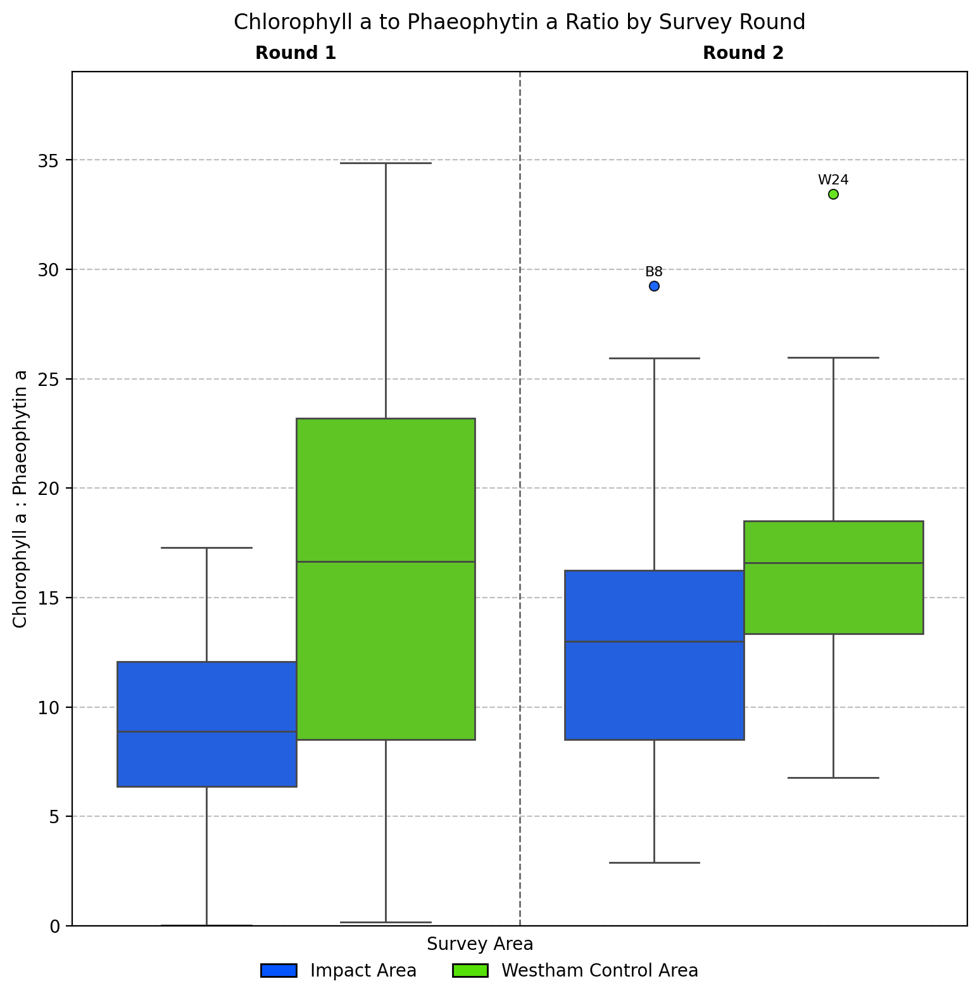

In [14]:
# Chla:Phta ratio

fig, ax = draw_boxplots_2(
    df_lab_r,
    ["Chla:Phta"],
    round_number=[1, 2],
    round_layout="horizontal",
    round_separator=True,
    title="Chlorophyll a to Phaeophytin a Ratio by Survey Round",
    y_scale="linear",
    y_label="Chlorophyll a : Phaeophytin a",
    show_y_grid=True,
    annotate_outliers=True,
    show_x_tick_labels=False,
    figsize=(8, 8)
)


### Fatty acids

In [15]:
fa_unit = 'mg/g' # or 'mg/m2'

CORE_FA = [
    'Total FA',
    'Total SFA',
    'Total MUFA',
    'Total PUFA',
    'Total Omega-3 PUFA',
    'Total Omega-6 PUFA',
    'Total LC-PUFA',
    'C20:5N3', # EPA
    'C22:6N3', # DHA
    'C20:4N6', # ARA
]

CORE_FA_LABELS = [
    'Total FA',
    'Total SFA',
    'Total MUFA',
    'Total PUFA',
    'Total Omega-3 PUFA',
    'Total Omega-6 PUFA',
    'Total LC-PUFA',
    'EPA',
    'DHA',
    'ARA',
]

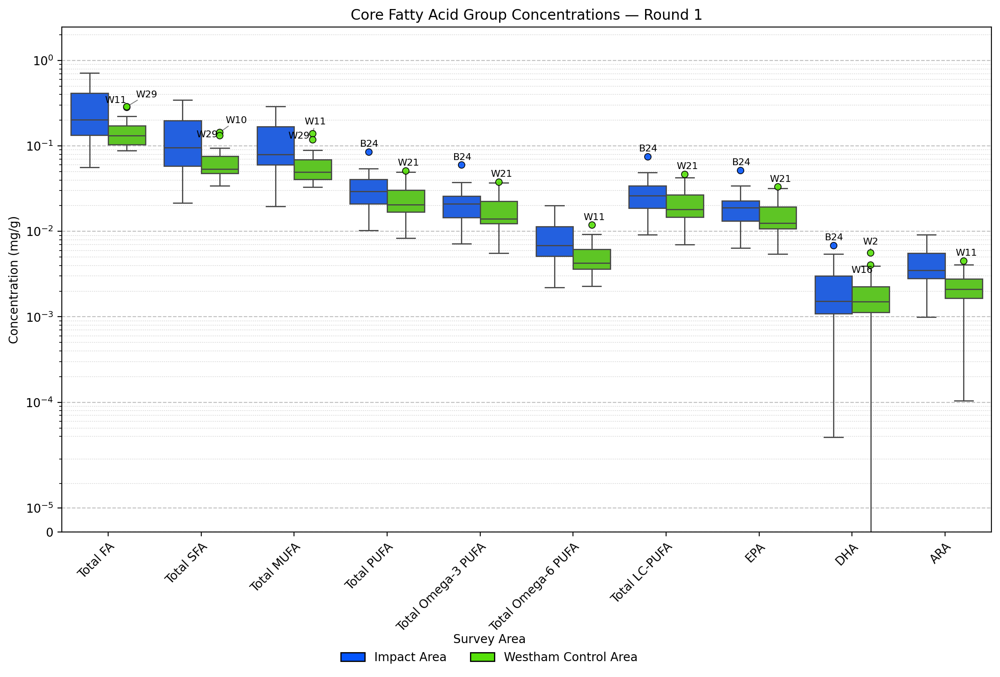

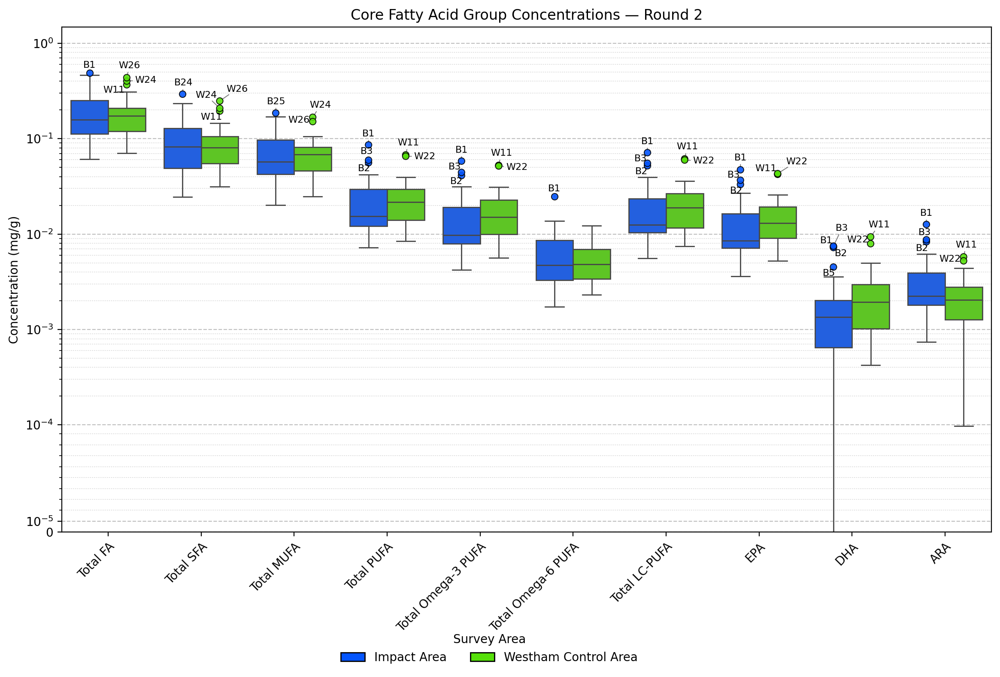

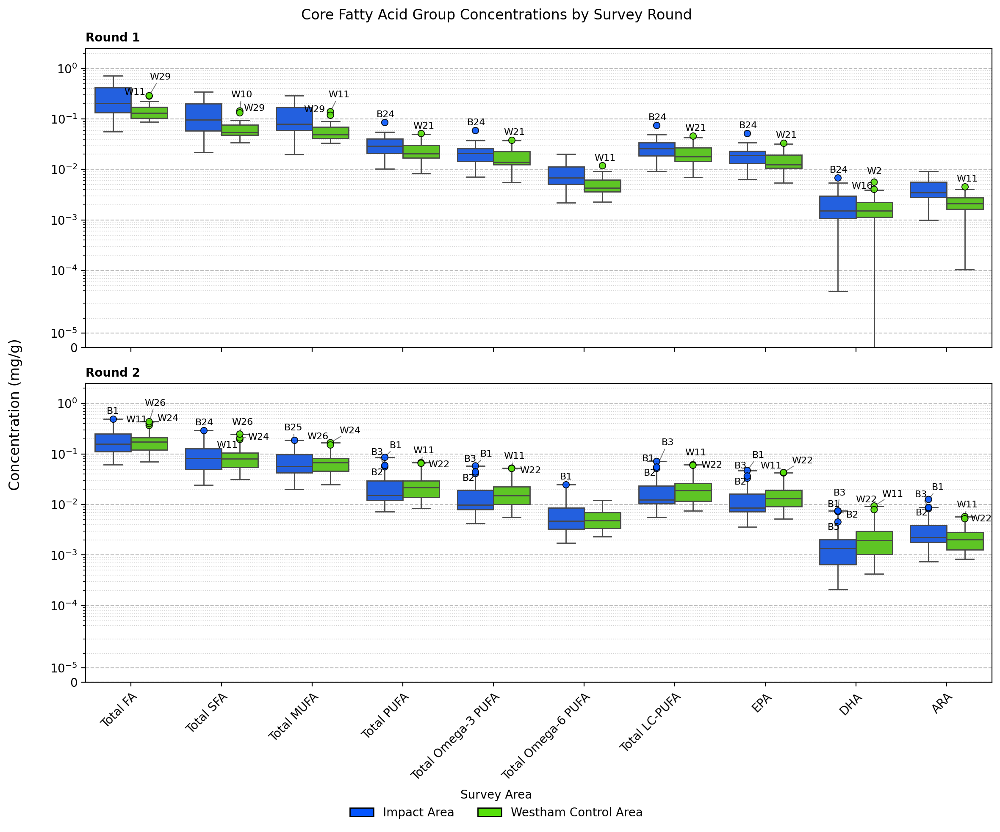

In [16]:
fa_columns = [f"{fa} ({fa_unit})" for fa in CORE_FA]

for round_number in [1, 2]:
    fig, ax = draw_boxplots(
        df_lab_r,
        fa_columns,
        round_number=round_number,
        title=f"Core Fatty Acid Group Concentrations \u2014 Round {round_number}",
        y_scale="symlog",
        annotate_outliers=True,
        variable_labels=CORE_FA_LABELS,
        y_label=f"Concentration ({fa_unit})",
    )
    path = path_output_dir / f"boxplots_core_fatty_acids_round_{round_number}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")

fig, ax = draw_boxplots(
    df_lab_r,
    fa_columns,
    round_number=[1, 2],
    title="Core Fatty Acid Group Concentrations by Survey Round",
    figsize=(12, 10),
    y_scale="symlog",
    y_label=f"Concentration ({fa_unit})",
    variable_labels=CORE_FA_LABELS,
    show_y_grid=True,
    annotate_outliers=True,
)
path = path_output_dir / "boxplots_core_fatty_acids_rounds_1_and_2.png"
fig.savefig(path, dpi=300, bbox_inches="tight")

In [17]:
core_fa_ratio_columns = [f"Total {x} : Total FA (%)" for x in ['SFA', 'MUFA', 'PUFA']]

for round_number in [1, 2]:
    for site in SITES:
        # Print mean ratios
        df_core_fa_ratios_sub = df_lab_r.loc[df_lab_r.index.get_level_values('station_id').str.startswith(site[0].upper()) &
        df_lab_r.index.get_level_values('round') == round_number][core_fa_ratio_columns].replace(0, np.nan)
        print(site, round_number)
        print(df_core_fa_ratios_sub.mean(axis=0))


brunswick 1
Total SFA : Total FA (%)     46.038103
Total MUFA : Total FA (%)    40.360410
Total PUFA : Total FA (%)    13.601487
dtype: float64
westham 1
Total SFA : Total FA (%)     43.577343
Total MUFA : Total FA (%)    39.550724
Total PUFA : Total FA (%)    16.871933
dtype: float64
brunswick 2
Total SFA : Total FA (%)    NaN
Total MUFA : Total FA (%)   NaN
Total PUFA : Total FA (%)   NaN
dtype: float64
westham 2
Total SFA : Total FA (%)    NaN
Total MUFA : Total FA (%)   NaN
Total PUFA : Total FA (%)   NaN
dtype: float64


In [18]:
# Sort and print mean concentrations for all FA
all_fa_columns = [f"{fa} ({fa_unit})" for fa in sorted(FA_LIST)]
df_all_fa = df_lab_r[all_fa_columns].replace(0, np.nan)

for round_number in [1, 2]:
    for site in SITES:
        df_all_fa_sub = df_all_fa.loc[df_all_fa.index.get_level_values('station_id').str.startswith(site[0].upper()) &
        df_all_fa.index.get_level_values('round') == round_number].copy()
        print(site, round_number, len(df_all_fa_sub))
        df_all_fa_sub_sorted = df_all_fa_sub.mean(axis=0).sort_values(ascending=False)
        df_all_fa_sub_sorted_norm = df_all_fa_sub_sorted/df_all_fa_sub_sorted.sum()
        print(df_all_fa_sub_sorted_norm.head(6))

brunswick 1 30
C16:1 (mg/g)      0.347818
C16 (mg/g)        0.295386
C20:5N3 (mg/g)    0.071312
C15 (mg/g)        0.069907
C14:0 (mg/g)      0.041601
C18:0 (mg/g)      0.023235
dtype: float64
westham 1 30
C16:1 (mg/g)       0.341378
C16 (mg/g)         0.272156
C20:5N3 (mg/g)     0.104325
C18:1N9C (mg/g)    0.034085
C14:0 (mg/g)       0.032486
C15 (mg/g)         0.031492
dtype: float64
brunswick 2 0
C10 (mg/g)     NaN
C11 (mg/g)     NaN
C12 (mg/g)     NaN
C13 (mg/g)     NaN
C14:0 (mg/g)   NaN
C14:1 (mg/g)   NaN
dtype: float64
westham 2 0
C10 (mg/g)     NaN
C11 (mg/g)     NaN
C12 (mg/g)     NaN
C13 (mg/g)     NaN
C14:0 (mg/g)   NaN
C14:1 (mg/g)   NaN
dtype: float64


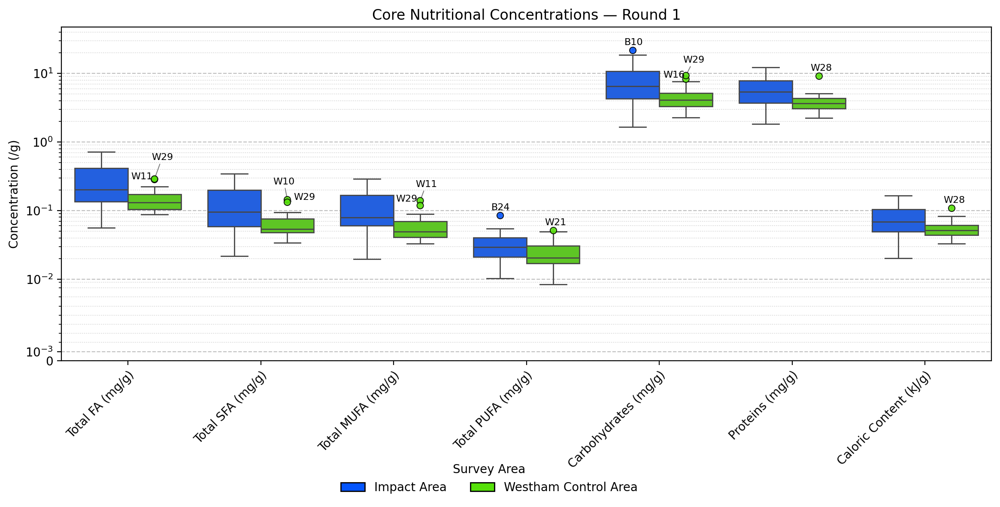

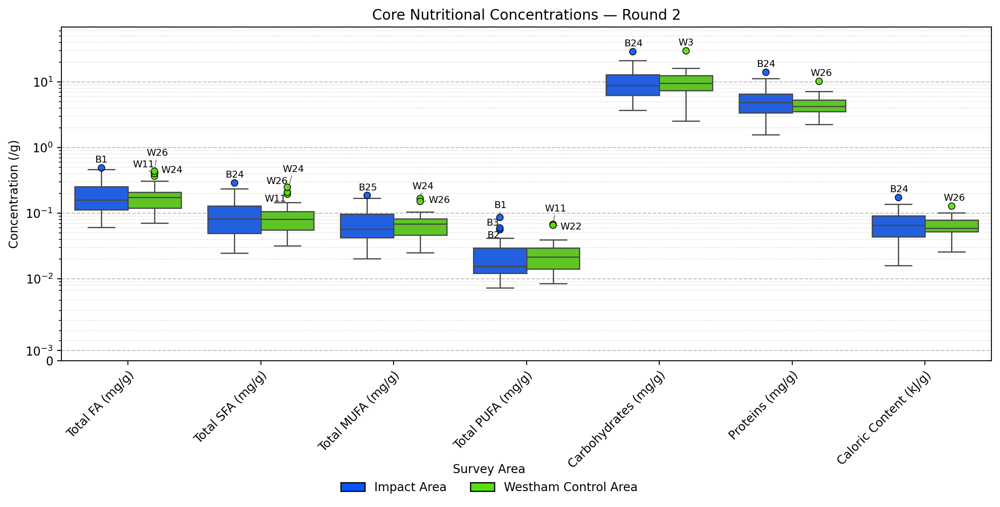

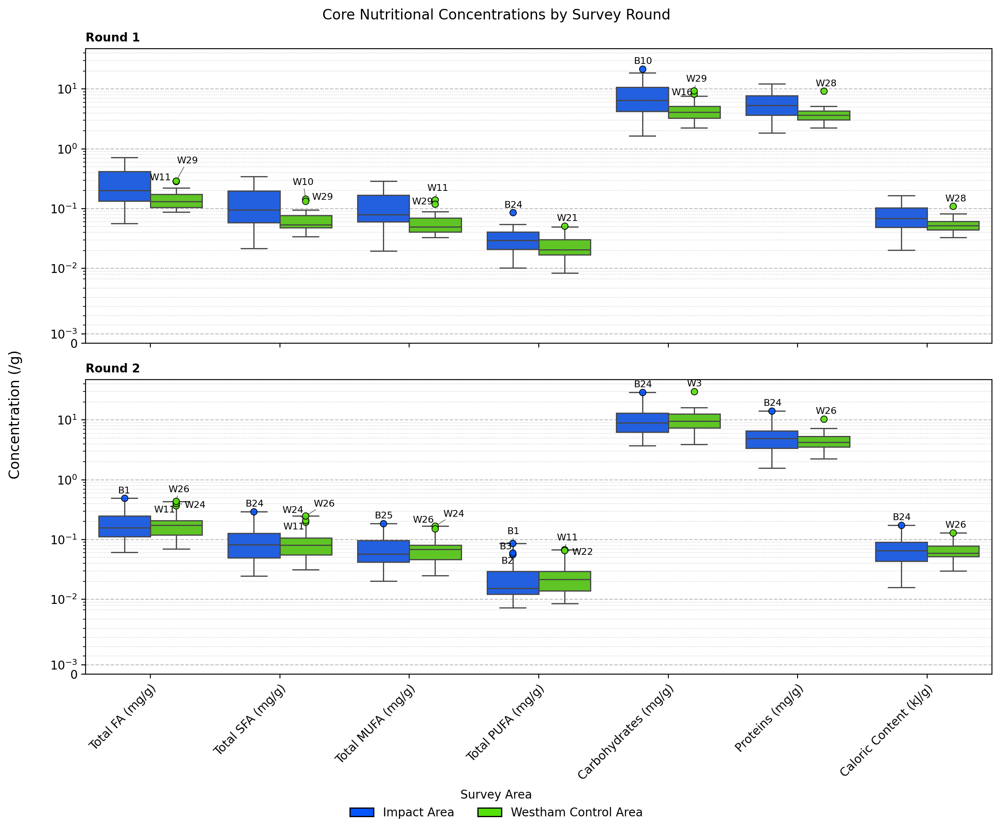

In [19]:
core_fa_columns = [
    'Total FA (mg/g)',
    'Total SFA (mg/g)',
    'Total MUFA (mg/g)',
    'Total PUFA (mg/g)',
]
core_nutritional_columns = core_fa_columns + [
    f"Total Carbs (mg/g)",
    f"Proteins (mg/g)",
    f"Caloric (kJ/g)",
]
core_nutritional_labels = [
    "Total FA (mg/g)",
    "Total SFA (mg/g)",
    "Total MUFA (mg/g)",
    "Total PUFA (mg/g)",
] + [
    "Carbohydrates (mg/g)",
    "Proteins (mg/g)",
    "Caloric Content (kJ/g)",
]

for round_number in [1, 2]:
    fig, ax = draw_boxplots(
        df_lab_r,
        core_nutritional_columns,
        round_number=round_number,
        title=f"Core Nutritional Concentrations \u2014 Round {round_number}",
        y_scale="symlog",
        annotate_outliers=True,
        variable_labels=core_nutritional_labels,
        y_label=f"Concentration (/g)",
        figsize=(12,6),
    )
    path = path_output_dir / f"boxplots_core_nutritional_round_{round_number}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")

fig, ax = draw_boxplots(
    df_lab_r,
    core_nutritional_columns,
    round_number=[1, 2],
    title="Core Nutritional Concentrations by Survey Round",
    figsize=(12, 10),
    y_scale="symlog",
    y_label=f"Concentration (/g)",
    variable_labels=core_nutritional_labels,
    show_y_grid=True,
    annotate_outliers=True,
)
path = path_output_dir / "boxplots_core_nutritional_rounds_1_and_2.png"
fig.savefig(path, dpi=300, bbox_inches="tight")


### Sediment physical parameters

In [20]:
SEDIMENT_UNIT = '%'
SEDIMENT_PARAMETERS_WITH_UNITS = [
    'Moisture (%)',
    'Percent Sand (%)',
    'Percent Silt (%)',
    'Percent Clay (%)'
]
SEDIMENT_PARAMETER_LABELS = [
    'Moisture',
    'Sand',
    'Silt',
    'Clay'
]

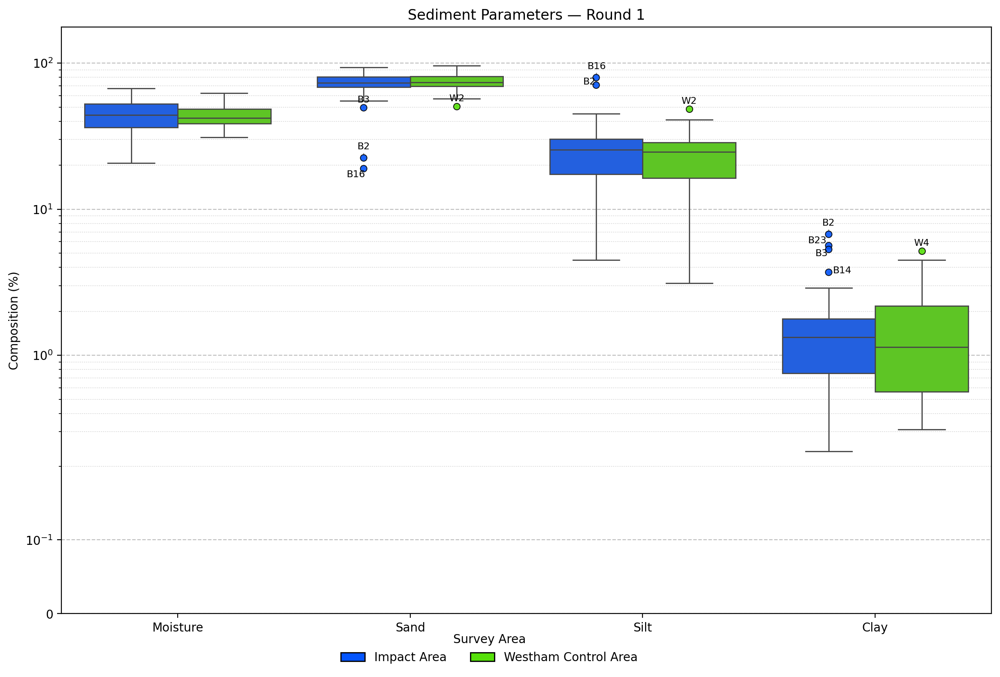

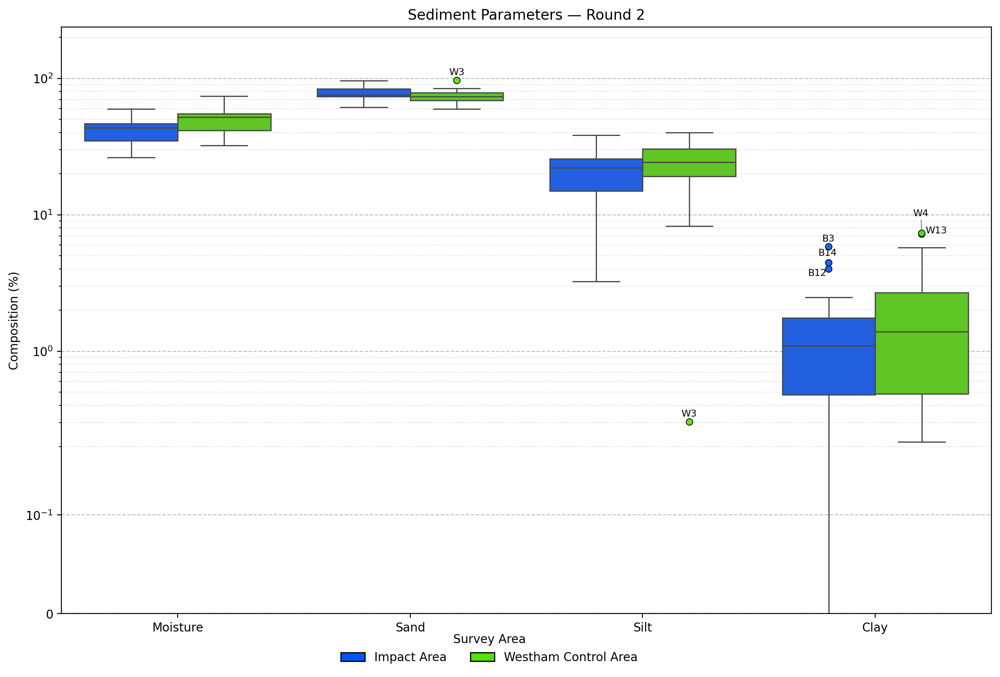

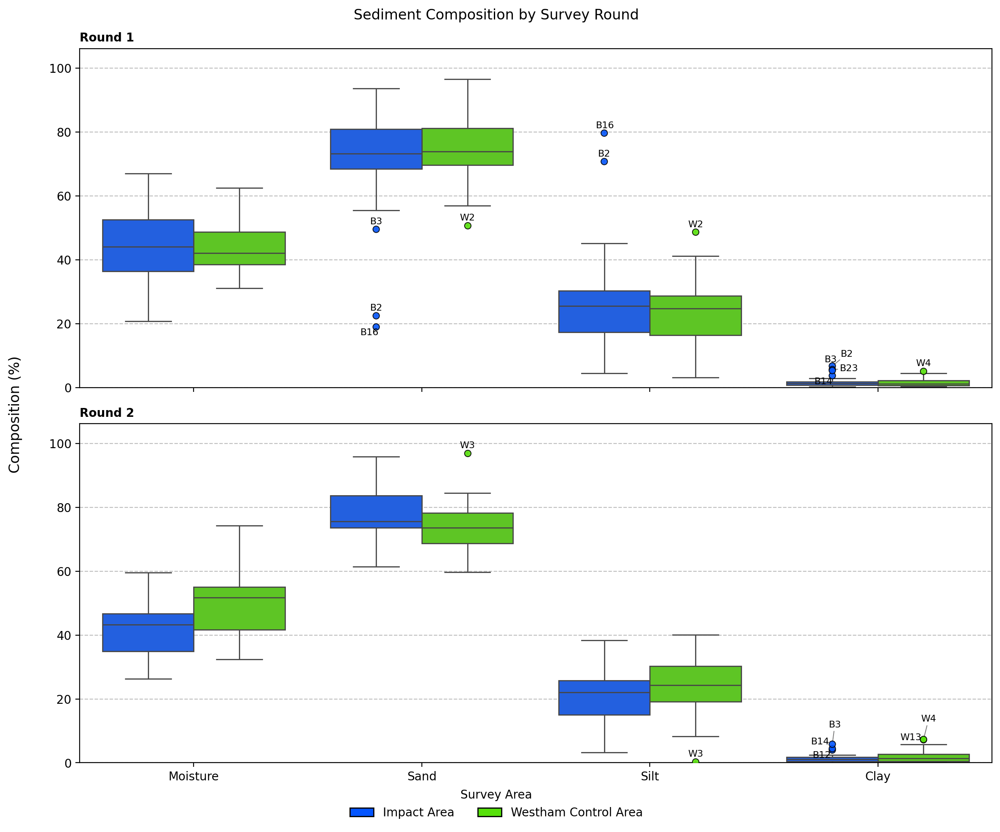

In [21]:
for round_number in [1, 2]:
    fig, ax = draw_boxplots(
        df_lab_r,
        SEDIMENT_PARAMETERS_WITH_UNITS,
        round_number=round_number,
        title=f"Sediment Parameters \u2014 Round {round_number}",
        y_scale="symlog",
        annotate_outliers=True,
        variable_labels=SEDIMENT_PARAMETER_LABELS,
        y_label=f"Composition ({SEDIMENT_UNIT})",
    )
    path = path_output_dir / f"boxplots_sediment_parameters_round_{round_number}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")

fig, ax = draw_boxplots(
    df_lab_r,
    SEDIMENT_PARAMETERS_WITH_UNITS,
    round_number=[1, 2],
    title="Sediment Composition by Survey Round",
    figsize=(12, 10),
    y_scale="linear",
    y_label=f"Composition ({SEDIMENT_UNIT})",
    variable_labels=SEDIMENT_PARAMETER_LABELS,
    show_y_grid=True,
    annotate_outliers=True,
)
path = path_output_dir / "boxplots_sediment_parameters_rounds_1_and_2.png"
fig.savefig(path, dpi=300, bbox_inches="tight")


## Summary statistics

In [22]:
import pandas as pd


def extract_site_round_summary(
    df,
    variables,
    round_number,
    stats=("min", "mean", "median", "std", "max"),
    sites=SITES,
    site_labels=SITE_LABELS,
    round_level="round",
    station_level="station_id",
    include_unknown=False,
    flatten_columns=False,
    variable_labels=None,
    value_format=None,
    variable_formats=None,
    return_styler=False,
    output="summary",
    mean_std_format="{mean:.3g} ± {std:.3g}",
    mean_std_formats=None,
    mean_std_label="Mean ± SD",
    missing_std="—",
):
    """
    Build a per-site summary table for one or multiple survey rounds.

    Parameters
    ----------
    df : pandas.DataFrame
        Input DataFrame with a MultiIndex containing round and station levels.
    variables : sequence of str
        Variable columns to summarize.
    round_number : int or sequence of int
        One round, such as 1, or multiple rounds, such as [1, 2].
    stats : sequence
        Aggregation statistics used when output="summary".
    sites : sequence
        Site names or identifiers used to infer site membership.
    site_labels : dict or sequence
        Display labels for sites.
    round_level : str, default "round"
        Name of the round index level.
    station_level : str, default "station_id"
        Name of the station index level.
    include_unknown : bool, default False
        Whether to retain stations that do not match a known site.
    flatten_columns : bool, default False
        Whether to flatten MultiIndex output columns.
    variable_labels : dict or sequence, optional
        Custom display names for variables.
    value_format : str or callable, optional
        Global numeric format used for a Styler when output="summary".
    variable_formats : dict, optional
        Per-variable numeric formats used when output="summary".
    return_styler : bool, default False
        Whether to return a pandas Styler.
    output : {"summary", "mean_std"}, default "summary"
        Output format:

        - "summary": return the requested numeric statistics.
        - "mean_std": return one formatted mean ± SD column per variable.

    mean_std_format : str or callable
        Format used for mean ± SD values. A string must contain the named
        fields ``mean`` and ``std``.

        Example: ``"{mean:.2f} ± {std:.2f}"``.

        A callable must accept two arguments: mean and standard deviation.
    mean_std_formats : dict, optional
        Per-variable mean ± SD formats. Keys can be original variable names
        or their display labels.
    mean_std_label : str, default "Mean ± SD"
        Label used for the combined statistic.
    missing_std : str, default "—"
        Text displayed when SD is unavailable, such as for a group with only
        one observation.

    Returns
    -------
    pandas.DataFrame or pandas.io.formats.style.Styler
        Index levels are Round and Survey Area.
    """

    # Normalize round_number
    if isinstance(round_number, (list, tuple, set)):
        round_numbers = list(round_number)
    else:
        round_numbers = [round_number]

    if not round_numbers:
        raise ValueError("At least one round number must be provided.")

    if not variables:
        raise ValueError("At least one variable must be provided.")

    valid_outputs = {
        "summary",
        "mean_std",
    }

    if output not in valid_outputs:
        raise ValueError(f"output must be one of {valid_outputs}; received {output!r}.")

    if output == "summary" and not stats:
        raise ValueError("At least one aggregation statistic must be provided.")

    # Create variable display-name mapping
    if variable_labels is None:
        variable_label_map = {variable: variable for variable in variables}

    elif isinstance(variable_labels, dict):
        variable_label_map = {
            variable: variable_labels.get(
                variable,
                variable,
            )
            for variable in variables
        }

    else:
        if len(variable_labels) != len(variables):
            raise ValueError(
                "The length of variable_labels must match the length "
                f"of variables. Received {len(variable_labels)} labels "
                f"for {len(variables)} variables."
            )

        variable_label_map = dict(zip(variables, variable_labels))

    # Create site display-name mapping
    if site_labels is None:
        site_label_map = {site: str(site) for site in sites}

    elif isinstance(site_labels, dict):
        site_label_map = {
            site: site_labels.get(
                site,
                str(site),
            )
            for site in sites
        }

    else:
        if len(site_labels) != len(sites):
            raise ValueError(
                "The length of site_labels must match the length "
                f"of sites. Received {len(site_labels)} labels "
                f"for {len(sites)} sites."
            )

        site_label_map = dict(zip(sites, site_labels))

    # Validate index levels
    required_levels = {
        round_level,
        station_level,
    }

    missing_levels = required_levels - set(df.index.names)

    if missing_levels:
        raise KeyError(
            "The DataFrame index is missing required level(s): "
            f"{sorted(missing_levels)}"
        )

    # Validate variables
    missing_variables = [
        variable for variable in variables if variable not in df.columns
    ]

    if missing_variables:
        raise KeyError(
            "The following variables were not found in the DataFrame: "
            f"{missing_variables}"
        )

    # Filter rounds
    round_mask = df.index.get_level_values(round_level).isin(round_numbers)

    df_filtered = df.loc[
        round_mask,
        list(variables),
    ].copy()

    if df_filtered.empty:
        raise ValueError(f"No rows were found for round(s): {round_numbers}")

    df_filtered = df_filtered.reset_index()

    # Assign survey area from station ID
    def infer_site(station_id):
        station_id = str(station_id)

        matched_site = next(
            (site for site in sites if station_id.startswith(str(site)[0].upper())),
            None,
        )

        if matched_site is None:
            return "Unknown"

        return site_label_map.get(
            matched_site,
            str(matched_site),
        )

    df_filtered["Survey Area"] = df_filtered[station_level].map(infer_site)

    # Standardize the round column name
    df_filtered = df_filtered.rename(
        columns={
            round_level: "Round",
        }
    )

    if not include_unknown:
        df_filtered = df_filtered.loc[df_filtered["Survey Area"] != "Unknown"]

    if df_filtered.empty:
        raise ValueError("No rows remained after site filtering.")

    grouped = df_filtered.groupby(
        [
            "Round",
            "Survey Area",
        ],
        observed=True,
    )[list(variables)]

    # ==================================================================
    # Standard numeric summary
    # ==================================================================
    if output == "summary":
        summary = grouped.agg(list(stats)).sort_index()

        summary = summary.rename(
            columns=variable_label_map,
            level=0,
        )

        summary.columns.names = [
            "Variable",
            "Stat",
        ]

        if flatten_columns:
            flattened_columns = []

            for variable, stat in summary.columns:
                if isinstance(stat, str):
                    stat_name = stat
                else:
                    stat_name = getattr(
                        stat,
                        "__name__",
                        str(stat),
                    )

                flattened_columns.append(f"{variable}__{stat_name}")

            summary.columns = flattened_columns

        if not return_styler:
            return summary

        styled = summary.style

        if value_format is not None:
            styled = styled.format(value_format)

        if variable_formats:
            if flatten_columns:
                for variable, fmt in variable_formats.items():
                    display_variable = variable_label_map.get(
                        variable,
                        variable,
                    )

                    matching_columns = [
                        column
                        for column in summary.columns
                        if (
                            isinstance(column, str)
                            and column.startswith(f"{display_variable}__")
                        )
                    ]

                    if matching_columns:
                        styled = styled.format(
                            fmt,
                            subset=pd.IndexSlice[
                                :,
                                matching_columns,
                            ],
                        )

            else:
                for variable, fmt in variable_formats.items():
                    display_variable = variable_label_map.get(
                        variable,
                        variable,
                    )

                    matching_columns = [
                        column
                        for column in summary.columns
                        if column[0] == display_variable
                    ]

                    if matching_columns:
                        styled = styled.format(
                            fmt,
                            subset=pd.IndexSlice[
                                :,
                                matching_columns,
                            ],
                        )

        return styled

    # ==================================================================
    # Combined mean ± SD output
    # ==================================================================
    numeric_mean_std = grouped.agg(["mean", "std"]).sort_index()

    mean_std_formats = {} if mean_std_formats is None else mean_std_formats

    combined_columns = {}

    for variable in variables:
        display_variable = variable_label_map[variable]

        means = numeric_mean_std[
            (
                variable,
                "mean",
            )
        ]

        standard_deviations = numeric_mean_std[
            (
                variable,
                "std",
            )
        ]

        variable_format = mean_std_formats.get(
            variable,
            mean_std_formats.get(
                display_variable,
                mean_std_format,
            ),
        )

        formatted_values = []

        for mean, std in zip(
            means,
            standard_deviations,
        ):
            if pd.isna(mean):
                formatted_value = "—"

            elif pd.isna(std):
                formatted_value = f"{mean:.3g} ± {missing_std}"

            elif callable(variable_format):
                formatted_value = variable_format(
                    mean,
                    std,
                )

            else:
                formatted_value = variable_format.format(
                    mean=mean,
                    std=std,
                )

            formatted_values.append(formatted_value)

        combined_columns[
            (
                display_variable,
                mean_std_label,
            )
        ] = formatted_values

    summary = pd.DataFrame(
        combined_columns,
        index=numeric_mean_std.index,
    )

    summary.columns = pd.MultiIndex.from_tuples(
        summary.columns,
        names=[
            "Variable",
            "Stat",
        ],
    )

    if flatten_columns:
        summary.columns = [f"{variable}__{stat}" for variable, stat in summary.columns]

    if return_styler:
        return summary.style

    return summary


In [23]:
summary_custom = extract_site_round_summary(
    df_lab_r,
    variables=core_pigment_columns,
    round_number=[1, 2],
    stats=("mean", "std"),
    flatten_columns=False,
    return_styler=True,
    # variable_formats={"Chla:Phta": "{:.2f}"},
    variable_labels=CORE_PIGMENT_FULL_LABELS.values(),
    value_format="{:.1e}",
)

display(summary_custom)

core_pigment_columns_norm = [
    f"{pigment} : {NORMALIZING_CHLA_COLUMN}"
    for pigment in CORE_PIGMENTS
    if pigment != NORMALIZING_CHLA_COLUMN
]
core_pigment_labels_norm = [
    f"{label} : {NORMALIZING_CHLA_COLUMN}"
    for label in CORE_PIGMENT_FULL_LABELS.values()
    if label != CORE_PIGMENT_FULL_LABELS.get(NORMALIZING_CHLA_COLUMN, '')
]
summary_custom = extract_site_round_summary(
    df_lab_r,
    variables=[f"{NORMALIZING_CHLA_COLUMN} ({pigment_unit})"]
    + core_pigment_columns_norm,
    round_number=[1, 2],
    stats=("mean", "median", "std"),
    flatten_columns=False,
    return_styler=True,
    # variable_formats={"Chla:Phta": "{:.2f}"},
    variable_labels=[NORMALIZING_CHLA_COLUMN] + core_pigment_labels_norm,
    value_format="{:.3f}",
    variable_formats={f"{NORMALIZING_CHLA_COLUMN} ({pigment_unit})": "{:.1e}"},
)

display(summary_custom)

mean_std = extract_site_round_summary(
    df=df_lab_r,
    variables=[f"{NORMALIZING_CHLA_COLUMN} ({pigment_unit})"] + core_pigment_columns_norm,
    round_number=[1, 2],
    # variable_labels=[CORE_PIGMENT_FULL_LABELS["Chla"]] + core_pigment_labels_norm,
    output="mean_std",
    mean_std_format="{mean:.4f} ± {std:.4f}",
    mean_std_formats={
        f"{NORMALIZING_CHLA_COLUMN} ({pigment_unit})": "{mean:.3f} ± {std:.3f}",
        # core_pigment_columns_norm[0]: "{mean:.2e} ± {std:.2e}",
    },
)

display(mean_std)

Variable                   Chla + allomers (mg/g) Chla : Chla + allomers  \
Stat                                    Mean ± SD              Mean ± SD   
Round Survey Area                                                          
1     Impact Area                   0.015 ± 0.008        0.6526 ± 0.2671   
      Westham Control Area          0.010 ± 0.004        0.7956 ± 0.1039   
2     Impact Area                   0.015 ± 0.007        0.7233 ± 0.1701   
      Westham Control Area          0.011 ± 0.004        0.7931 ± 0.1179   

Variable                   Chlb : Chla + allomers Fuco : Chla + allomers  \
Stat                                    Mean ± SD              Mean ± SD   
Round Survey Area                                                          
1     Impact Area                 0.0164 ± 0.0143        0.9076 ± 2.3366   
      Westham Control Area        0.0124 ± 0.0171        0.3904 ± 0.3001   
2     Impact Area                 0.0160 ± 0.0119        0.2766 ± 0.0483   
      Westham Control Area        0.0180 ± 0.0206        0.3181 ± 0.0495   

Variable                   Ddx : Chla + allomers DVCh-a : Chla + allomers  \
Stat                                   Mean ± SD                Mean ± SD   
Round Survey Area                                                           
1     Impact Area                0.3782 ± 0.8627          0.0601 ± 0.0772   
      Westham Control Area       0.2135 ± 0.0697          0.0404 ± 0.0170   
2     Impact Area                0.1600 ± 0.0326          0.0656 ± 0.0317   
      Westham Control Area       0.2217 ± 0.0422          0.0368 ± 0.0141   

Variable                   Zea : Chla + allomers  
Stat                                   Mean ± SD  
Round Survey Area                                 
1     Impact Area                0.1203 ± 0.3597  
      Westham Control Area       0.0291 ± 0.0361  
2     Impact Area                0.0230 ± 0.0097  
      Westham Control Area       0.0228 ± 0.0070

In [24]:
core_fa_columns_norm = [f"{fa} : {NORMALIZING_CHLA_COLUMN}" for fa in CORE_FA]
core_fa_labels_norm = [f"{label} : {NORMALIZING_CHLA_COLUMN}" for label in CORE_FA_LABELS]

summary_custom = extract_site_round_summary(
    df_lab_r,
    variables=core_fa_columns_norm,
    round_number=[1, 2],
    stats=("mean", "std"),
    flatten_columns=False,
    return_styler=True,
    # variable_formats={"Chla:Phta": "{:.2f}"},
    variable_labels=core_fa_labels_norm,
    value_format="{:.2f}",
)

display(summary_custom)

mean_std = extract_site_round_summary(
    df_lab_r,
    variables=[f"{NORMALIZING_CHLA_COLUMN} ({pigment_unit})"] + core_fa_columns_norm,
    round_number=[1, 2],
    output="mean_std",
    mean_std_format="{mean:.2f} ± {std:.2f}",
    mean_std_formats={
        f"{NORMALIZING_CHLA_COLUMN} ({pigment_unit})": "{mean:.4f} ± {std:.4f}",
    },
    variable_labels=[NORMALIZING_CHLA_COLUMN + f" ({pigment_unit})"] + core_fa_labels_norm
)
display(mean_std)

# Save to CSV
path = path_output_dir / "summary_fa_concentration_normalized.csv"
mean_std.to_csv(path, index=False)



Variable                   Chla + allomers (mg/g) Total FA : Chla + allomers  \
Stat                                    Mean ± SD                  Mean ± SD   
Round Survey Area                                                              
1     Impact Area                 0.0152 ± 0.0084             45.07 ± 125.11   
      Westham Control Area        0.0098 ± 0.0038               17.10 ± 9.97   
2     Impact Area                 0.0150 ± 0.0065               13.40 ± 6.68   
      Westham Control Area        0.0113 ± 0.0040               16.51 ± 6.62   

Variable                   Total SFA : Chla + allomers  \
Stat                                         Mean ± SD   
Round Survey Area                                        
1     Impact Area                        20.10 ± 53.05   
      Westham Control Area                 7.37 ± 3.94   
2     Impact Area                          6.78 ± 3.91   
      Westham Control Area                 7.97 ± 3.57   

Variable                   Total MUFA : Chla + allomers  \
Stat                                          Mean ± SD   
Round Survey Area                                         
1     Impact Area                         16.22 ± 41.47   
      Westham Control Area                  6.78 ± 4.02   
2     Impact Area                           4.94 ± 2.38   
      Westham Control Area                  6.20 ± 2.11   

Variable                   Total PUFA : Chla + allomers  \
Stat                                          Mean ± SD   
Round Survey Area                                         
1     Impact Area                          8.75 ± 30.77   
      Westham Control Area                  2.95 ± 2.37   
2     Impact Area                           1.68 ± 1.05   
      Westham Control Area                  2.33 ± 1.36   

Variable                   Total Omega-3 PUFA : Chla + allomers  \
Stat                                                  Mean ± SD   
Round Survey Area                                                 
1     Impact Area                                  6.44 ± 23.30   
      Westham Control Area                          2.15 ± 1.73   
2     Impact Area                                   1.14 ± 0.77   
      Westham Control Area                          1.72 ± 1.08   

Variable                   Total Omega-6 PUFA : Chla + allomers  \
Stat                                                  Mean ± SD   
Round Survey Area                                                 
1     Impact Area                                   1.88 ± 6.08   
      Westham Control Area                          0.62 ± 0.49   
2     Impact Area                                   0.46 ± 0.28   
      Westham Control Area                          0.50 ± 0.26   

Variable                   Total LC-PUFA : Chla + allomers  \
Stat                                             Mean ± SD   
Round Survey Area                                            
1     Impact Area                             7.90 ± 28.19   
      Westham Control Area                     2.62 ± 2.16   
2     Impact Area                              1.46 ± 0.96   
      Westham Control Area                     2.05 ± 1.26   

Variable                   EPA : Chla + allomers DHA : Chla + allomers  \
Stat                                   Mean ± SD             Mean ± SD   
Round Survey Area                                                        
1     Impact Area                   5.58 ± 20.04           0.80 ± 3.14   
      Westham Control Area           1.89 ± 1.52           0.22 ± 0.24   
2     Impact Area                    0.98 ± 0.64           0.14 ± 0.13   
      Westham Control Area           1.46 ± 0.87           0.23 ± 0.20   

Variable                   ARA : Chla + allomers  
Stat                                   Mean ± SD  
Round Survey Area                                 
1     Impact Area                    0.97 ± 3.23  
      Westham Control Area           0.30 ± 0.27  
2     Impact Area                    0.24 ± 0.16  
    

In [25]:
summary_custom = extract_site_round_summary(
    df=(df_lab_r.copy()
    .assign(**{"Chla:Phta": df_lab_r["Chla:Phta"].replace([np.inf, -np.inf], np.nan)})
    .dropna(subset=["Chla:Phta"])
    ),
    variables=["Chla:Phta"],
    round_number=[1, 2],
    stats=("mean", "median", "std"),
    flatten_columns=False,
    return_styler=True,
    variable_formats={"Chla:Phta": "{:.2f}"},
)

display(summary_custom)


## Distribution difference?

In [26]:
from analysis.distribution_analysis import (
    extract_station_round,
    analyze_two_group_two_round,
    analysis_tables,
    markdown_report,
)

VARIABLE = "Chla:Phta"

GROUP_B_PREFIX = "B"
GROUP_B_LABEL = "Impact Area (B)"

GROUP_W_PREFIX = "W"
GROUP_W_LABEL = "Westham Control Area (W)"

b_round_1 = extract_station_round(
    df_lab_r,
    VARIABLE,
    group_prefix=GROUP_B_PREFIX,
    round_value=1,
)

b_round_2 = extract_station_round(
    df_lab_r,
    VARIABLE,
    group_prefix=GROUP_B_PREFIX,
    round_value=2,
)

w_round_1 = extract_station_round(
    df_lab_r,
    VARIABLE,
    group_prefix=GROUP_W_PREFIX,
    round_value=1,
)

w_round_2 = extract_station_round(
    df_lab_r,
    VARIABLE,
    group_prefix=GROUP_W_PREFIX,
    round_value=2,
)

results = analyze_two_group_two_round(
    b_round_1,
    b_round_2,
    w_round_1,
    w_round_2,
    group_a=GROUP_B_LABEL,
    group_b=GROUP_W_LABEL,
    round_1_label="Round 1",
    round_2_label="Round 2",
    variable=VARIABLE,
    alpha=0.05,
    n_permutations=9999,
    seed=123,
    run_energy_tests=True,
)

tables = analysis_tables(results)

display(tables["descriptive"])
display(tables["mean_tests"])
display(tables["distribution_tests"])

report = markdown_report(results)
print(report)


,variable,round,group,n,mean,sd,median,q1,q3,min,max
0,Chla:Phta,Round 1,Impact Area (B),26,9.132332,4.376869,8.892695,6.374464,12.068502,0.022516,17.301153
1,Chla:Phta,Round 1,Westham Control Area (W),25,16.220543,8.813110,16.662905,8.498018,23.189881,0.176847,34.868910
2,Chla:Phta,Round 2,Impact Area (B),30,13.599733,6.548593,12.995726,8.518823,16.254642,2.895136,29.240295
3,Chla:Phta,Round 2,Westham Control Area (W),30,17.249670,5.380531,16.583310,13.355423,18.498324,6.779137,33.459298


,analysis,contrast,estimate,ci_lower,ci_upper,t,df,p,p_holm,effect_size,effect_size_name
0,Between groups,Impact Area (B) - Westham Control Area (W) at ...,-7.088211,-11.068887,-3.107536,-3.615473,34.851600,0.000938,0.001876,-1.009282,Hedges g
1,Between groups,Impact Area (B) - Westham Control Area (W) at ...,-3.649937,-6.749894,-0.549979,-2.358741,55.896833,0.021858,0.021858,-0.601115,Hedges g
2,Within-group change,Impact Area (B): Round 2 - Round 1,4.464648,1.371058,7.558239,2.972312,25.000000,0.006453,0.012906,0.582918,Cohen dz
3,Within-group change,Westham Control Area (W): Round 2 - Round 1,1.423215,-3.147059,5.993489,0.642712,24.000000,0.526504,0.526504,0.128542,Cohen dz
4,Difference-in-differences,Change in Impact Area (B) - change in Westham ...,3.041433,-2.356524,8.439390,1.136656,42.524320,0.262047,NaN,0.315711,Hedges g of changes


,round,contrast,energy_distance,energy_statistic,energy_p,energy_p_holm,ks_distance,n_permutations
0,Round 1,Impact Area (B) vs Westham Control Area (W),2.166358,59.814090,0.0004,0.0008,0.524615,9999
1,Round 2,Impact Area (B) vs Westham Control Area (W),1.311554,25.802622,0.0125,0.0125,0.400000,9999


# Statistical summary: Chla:Phta

## Between-group comparisons
- **Round 1:** Impact Area (B) mean = 9.132 (SD 4.377, n=26); Westham Control Area (W) mean = 16.221 (SD 8.813, n=25).
  Mean difference (Impact Area (B) - Westham Control Area (W)) = -7.088, 95% CI [-11.069, -3.108], t(34.85) = -3.615, p = < 0.001, Holm-adjusted p = 0.002, Hedges g = -1.009.
  Energy permutation test: p = < 0.001; KS distance = 0.525.
- **Round 2:** Impact Area (B) mean = 13.600 (SD 6.549, n=30); Westham Control Area (W) mean = 17.250 (SD 5.381, n=30).
  Mean difference (Impact Area (B) - Westham Control Area (W)) = -3.650, 95% CI [-6.750, -0.550], t(55.90) = -2.359, p = 0.022, Holm-adjusted p = 0.022, Hedges g = -0.601.
  Energy permutation test: p = 0.013; KS distance = 0.400.

## Within-group changes
- **Impact Area (B):** mean change (Round 2 - Round 1) = 4.465, 95% CI [1.371, 7.558], t(25) = 2.972, p = 0.006, Holm-adjusted p = 0.013, Cohen dz = 0.583, n = 26.
- **Westham Control Area (W):** mean chang

In [27]:
for variable in [
    "Total SFA (mg/g)",
    "Total MUFA (mg/g)",
    "Total PUFA (mg/g)",
    "Total FA (mg/g)",
]:

    b_round_1 = extract_station_round(
        df_lab_r,
        variable,
        group_prefix=GROUP_B_PREFIX,
        round_value=1,
    )

    b_round_2 = extract_station_round(
        df_lab_r,
        variable,
        group_prefix=GROUP_B_PREFIX,
        round_value=2,
    )

    w_round_1 = extract_station_round(
        df_lab_r,
        variable,
        group_prefix=GROUP_W_PREFIX,
        round_value=1,
    )

    w_round_2 = extract_station_round(
        df_lab_r,
        variable,
        group_prefix=GROUP_W_PREFIX,
        round_value=2,
    )

    results = analyze_two_group_two_round(
        b_round_1,
        b_round_2,
        w_round_1,
        w_round_2,
        group_a=GROUP_B_LABEL,
        group_b=GROUP_W_LABEL,
        round_1_label="Round 1",
        round_2_label="Round 2",
        variable=variable,
        alpha=0.05,
        n_permutations=9999,
        seed=123,
        run_energy_tests=True,
    )

    # tables = analysis_tables(results)
    report = markdown_report(results)
    print(report, '\n\n\n\n')

# Statistical summary: Total SFA (mg/g)

## Between-group comparisons
- **Round 1:** Impact Area (B) mean = 0.127 (SD 0.086, n=30); Westham Control Area (W) mean = 0.064 (SD 0.026, n=30).
  Mean difference (Impact Area (B) - Westham Control Area (W)) = 0.063, 95% CI [0.029, 0.096], t(34.24) = 3.814, p = < 0.001, Holm-adjusted p = 0.001, Hedges g = 0.972.
  Energy permutation test: p = < 0.001; KS distance = 0.467.
- **Round 2:** Impact Area (B) mean = 0.100 (SD 0.065, n=30); Westham Control Area (W) mean = 0.090 (SD 0.052, n=30).
  Mean difference (Impact Area (B) - Westham Control Area (W)) = 0.010, 95% CI [-0.021, 0.040], t(54.98) = 0.638, p = 0.526, Holm-adjusted p = 0.526, Hedges g = 0.163.
  Energy permutation test: p = 0.677; KS distance = 0.167.

## Within-group changes
- **Impact Area (B):** mean change (Round 2 - Round 1) = -0.027, 95% CI [-0.043, -0.010], t(29) = -3.337, p = 0.002, Holm-adjusted p = 0.005, Cohen dz = -0.609, n = 30.
- **Westham Control Area (W):** mean change

## Correlation heatmap

In [28]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, spearmanr, kendalltau


def draw_correlation_heatmap(
    df,
    variables,
    round_number=None,
    survey_area=None,
    sites=None,
    site_labels=None,
    calculation="independent",
    independent_annotation="range",
    variable_labels=None,
    method="pearson",
    min_periods=3,
    calculate_significance=True,
    p_adjust="fdr_bh",
    significance_levels=(0.05, 0.01, 0.001),
    require_same_direction=True,
    hide_counts_when_single_subgroup=True,
    pooled_pvalue_method="none",
    title=None,
    figsize=None,
    cmap="RdBu_r",
    annot=True,
    fmt=".2f",
    std_fmt=None,
    range_fmt=None,
    mask_upper=True,
    show_diagonal=True,
    show_diagonal_values=False,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_label=None,
    round_level="round",
    station_level="station_id",
    include_unknown=False,
    x_rotation=45,
    bold_significant=True,
    show_significance_legend=True,
    show=True,
):
    """
    Draw a correlation heatmap using pooled observations or stratified
    round-survey-area subgroup results.

    Independent calculation
    -----------------------
    A separate correlation matrix is calculated for each selected
    round-survey-area subgroup. Heatmap colors represent the arithmetic mean
    correlation. Cell annotations can show the subgroup SD, range, or mean
    only.

    Significance is summarized using mutually exclusive adjusted-p categories.
    For example::

        *** [2,1,1]

    means:

    - 2 eligible subgroups have adjusted p < 0.001;
    - 1 has 0.001 <= adjusted p < 0.01;
    - 1 has 0.01 <= adjusted p < 0.05.

    Counts are displayed from the strongest category represented down to the
    weakest category. By default, only subgroup correlations with the same
    direction as the displayed mean are counted.

    Pooled calculation
    ------------------
    All selected rows are correlated together. If
    ``pooled_pvalue_method="analytic"``, one adjusted p-value is calculated
    for each variable pair and displayed using ordinary stars. Because rows
    from repeated stations are not independent, pooled analytic p-values
    should be interpreted cautiously; the default is ``"none"``.

    Parameters
    ----------
    calculation : {"independent", "pooled"}
        Independent summarizes round-survey-area correlation matrices.
        Pooled calculates one correlation matrix from all selected rows.
    independent_annotation : {"std", "range", "none"}
        Additional independent-mode annotation below the mean.
    p_adjust : {"fdr_bh", "holm", "bonferroni", "none"}
        Multiple-testing adjustment across unique variable pairs.
    significance_levels : tuple
        Weak-to-strong thresholds, normally (0.05, 0.01, 0.001).
    hide_counts_when_single_subgroup : bool
        If True, show stars without category counts when only one valid
        subgroup contributes to a variable pair.
    pooled_pvalue_method : {"none", "analytic"}
        Enable or disable conventional pooled p-values.
    """

    # ------------------------------------------------------------------
    # Helpers
    # ------------------------------------------------------------------
    # superscript_translation = str.maketrans(
    #     "0123456789-",
    #     "⁰¹²³⁴⁵⁶⁷⁸⁹⁻",
    # )

    # def superscript_number(value):
    #     return str(int(value)).translate(superscript_translation)

    def pairwise_statistics(data):
        """Return symmetric coefficient, raw-p, and paired-n matrices."""
        count = len(variables)
        coefficients = np.full((count, count), np.nan, dtype=float)
        pvalues = np.full((count, count), np.nan, dtype=float)
        sample_sizes = np.zeros((count, count), dtype=int)

        for i, variable_x in enumerate(variables):
            diagonal_n = int(data[variable_x].notna().sum())
            sample_sizes[i, i] = diagonal_n

            if diagonal_n >= min_periods:
                coefficients[i, i] = 1.0

            for j in range(i):
                variable_y = variables[j]
                pair = data[[variable_x, variable_y]].dropna()
                n = len(pair)

                sample_sizes[i, j] = n
                sample_sizes[j, i] = n

                if n < min_periods:
                    continue

                x = pair[variable_x].to_numpy(dtype=float)
                y = pair[variable_y].to_numpy(dtype=float)

                if np.all(x == x[0]) or np.all(y == y[0]):
                    continue

                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")

                    if method == "pearson":
                        result = pearsonr(x, y)
                    elif method == "spearman":
                        result = spearmanr(x, y)
                    else:
                        result = kendalltau(x, y)

                coefficient = float(result.statistic)
                pvalue = float(result.pvalue)

                coefficients[i, j] = coefficient
                coefficients[j, i] = coefficient
                pvalues[i, j] = pvalue
                pvalues[j, i] = pvalue

        index = columns = variables

        return (
            pd.DataFrame(coefficients, index=index, columns=columns),
            pd.DataFrame(pvalues, index=index, columns=columns),
            pd.DataFrame(sample_sizes, index=index, columns=columns),
        )

    def adjust_pvalue_matrix(raw_matrix):
        """Adjust finite p-values from the unique lower triangle."""
        adjusted = pd.DataFrame(
            np.nan,
            index=raw_matrix.index,
            columns=raw_matrix.columns,
            dtype=float,
        )

        lower_rows, lower_columns = np.tril_indices(
            len(raw_matrix),
            k=-1,
        )

        locations = []
        raw_values = []

        for i, j in zip(lower_rows, lower_columns):
            value = raw_matrix.iat[i, j]

            if pd.notna(value):
                locations.append((i, j))
                raw_values.append(float(value))

        if not raw_values:
            return adjusted

        raw_values = np.asarray(raw_values)
        number_of_tests = len(raw_values)

        if p_adjust == "none":
            adjusted_values = raw_values.copy()

        elif p_adjust == "bonferroni":
            adjusted_values = np.minimum(
                raw_values * number_of_tests,
                1.0,
            )

        else:
            order = np.argsort(raw_values)
            ordered = raw_values[order]

            if p_adjust == "fdr_bh":
                ranks = np.arange(1, number_of_tests + 1)
                ordered_adjusted = ordered * number_of_tests / ranks
                ordered_adjusted = np.minimum.accumulate(ordered_adjusted[::-1])[::-1]

            else:  # Holm
                multipliers = number_of_tests - np.arange(number_of_tests)
                ordered_adjusted = ordered * multipliers
                ordered_adjusted = np.maximum.accumulate(ordered_adjusted)

            ordered_adjusted = np.minimum(ordered_adjusted, 1.0)
            adjusted_values = np.empty_like(ordered_adjusted)
            adjusted_values[order] = ordered_adjusted

        for (i, j), value in zip(locations, adjusted_values):
            adjusted.iat[i, j] = value
            adjusted.iat[j, i] = value

        return adjusted

    def apply_labels(matrix):
        if matrix is None:
            return None

        return matrix.rename(
            index=variable_label_map,
            columns=variable_label_map,
        )

    def strongest_star(adjusted_p):
        if pd.isna(adjusted_p):
            return ""

        for level_index in reversed(range(len(significance_levels))):
            if adjusted_p < significance_levels[level_index]:
                return "*" * (level_index + 1)

        return ""

    # ------------------------------------------------------------------
    # Validation
    # ------------------------------------------------------------------
    if not variables:
        raise ValueError("At least one variable must be provided.")

    variables = list(variables)

    if len(variables) < 2:
        raise ValueError(
            "At least two variables are required for a correlation matrix."
        )

    missing_variables = [
        variable for variable in variables if variable not in df.columns
    ]
    if missing_variables:
        raise KeyError(f"Variables not found in the DataFrame: {missing_variables}")

    method = method.lower()
    if method not in {"pearson", "spearman", "kendall"}:
        raise ValueError("method must be 'pearson', 'spearman', or 'kendall'.")

    calculation = calculation.lower()
    if calculation not in {"independent", "pooled"}:
        raise ValueError("calculation must be 'independent' or 'pooled'.")

    independent_annotation = independent_annotation.lower()
    if independent_annotation not in {"std", "range", "none"}:
        raise ValueError("independent_annotation must be 'std', 'range', or 'none'.")

    p_adjust = p_adjust.lower()
    if p_adjust not in {"fdr_bh", "holm", "bonferroni", "none"}:
        raise ValueError("p_adjust must be 'fdr_bh', 'holm', 'bonferroni', or 'none'.")

    pooled_pvalue_method = pooled_pvalue_method.lower()
    if pooled_pvalue_method not in {"none", "analytic"}:
        raise ValueError("pooled_pvalue_method must be 'none' or 'analytic'.")

    significance_levels = tuple(float(level) for level in significance_levels)

    if (
        not significance_levels
        or any(level <= 0 or level >= 1 for level in significance_levels)
        or any(
            significance_levels[index] <= significance_levels[index + 1]
            for index in range(len(significance_levels) - 1)
        )
    ):
        raise ValueError(
            "significance_levels must be weak-to-strong, for example "
            "(0.05, 0.01, 0.001)."
        )

    if min_periods < 2:
        raise ValueError("min_periods must be at least 2.")

    required_levels = {round_level, station_level}
    missing_levels = required_levels - set(df.index.names)

    if missing_levels:
        raise KeyError(
            "The DataFrame index is missing required level(s): "
            f"{sorted(missing_levels)}"
        )

    if sites is None:
        raise ValueError("'sites' must be provided.")

    sites = list(sites)

    # ------------------------------------------------------------------
    # Labels
    # ------------------------------------------------------------------
    if variable_labels is None:
        variable_label_map = {variable: variable for variable in variables}
    elif isinstance(variable_labels, dict):
        variable_label_map = {
            variable: variable_labels.get(variable, variable) for variable in variables
        }
    else:
        if len(variable_labels) != len(variables):
            raise ValueError("variable_labels must have the same length as variables.")

        variable_label_map = dict(zip(variables, variable_labels))

    if len(set(variable_label_map.values())) != len(variables):
        raise ValueError("Variable display labels must be unique.")

    if site_labels is None:
        survey_area_label_map = {area: str(area) for area in sites}
    elif isinstance(site_labels, dict):
        survey_area_label_map = {
            area: site_labels.get(area, str(area)) for area in sites
        }
    else:
        if len(site_labels) != len(sites):
            raise ValueError("site_labels must have the same length as sites.")

        survey_area_label_map = dict(zip(sites, site_labels))

    survey_area_label_map["Unknown"] = "Unknown"

    # ------------------------------------------------------------------
    # Select rounds
    # ------------------------------------------------------------------
    available_rounds = list(pd.unique(df.index.get_level_values(round_level)))

    if round_number is None:
        selected_rounds = available_rounds
    elif isinstance(round_number, (list, tuple, set)):
        selected_rounds = list(round_number)
    else:
        selected_rounds = [round_number]

    missing_rounds = [
        value for value in selected_rounds if value not in set(available_rounds)
    ]

    if missing_rounds:
        raise KeyError(f"Round(s) not found in the DataFrame: {missing_rounds}")

    # ------------------------------------------------------------------
    # Select survey areas
    # ------------------------------------------------------------------
    label_to_area = {label: area for area, label in survey_area_label_map.items()}

    if survey_area is None:
        selected_area_ids = list(sites)

        if include_unknown:
            selected_area_ids.append("Unknown")
    else:
        requested_areas = (
            list(survey_area)
            if isinstance(survey_area, (list, tuple, set))
            else [survey_area]
        )

        selected_area_ids = []

        for requested in requested_areas:
            if requested in sites or requested == "Unknown":
                selected_area_ids.append(requested)
            elif requested in label_to_area:
                selected_area_ids.append(label_to_area[requested])
            else:
                raise KeyError(f"Unknown survey area: {requested!r}")

    selected_area_ids = list(dict.fromkeys(selected_area_ids))

    if "Unknown" in selected_area_ids and not include_unknown:
        raise ValueError("Set include_unknown=True to include Unknown.")

    # ------------------------------------------------------------------
    # Filter and identify survey areas
    # ------------------------------------------------------------------
    round_mask = df.index.get_level_values(round_level).isin(selected_rounds)

    data = df.loc[round_mask, variables].copy().reset_index()

    if data.empty:
        raise ValueError("No rows remained after round filtering.")

    def infer_survey_area(station_id):
        station_id = str(station_id)

        return next(
            (area for area in sites if station_id.startswith(str(area)[0].upper())),
            "Unknown",
        )

    data["_survey_area_id"] = data[station_level].map(infer_survey_area)

    data = data.loc[data["_survey_area_id"].isin(selected_area_ids)].copy()

    if data.empty:
        raise ValueError("No rows remained after survey-area filtering.")

    nonnumeric = [
        variable
        for variable in variables
        if not pd.api.types.is_numeric_dtype(data[variable])
    ]

    if nonnumeric:
        raise TypeError(f"Correlation variables must be numeric: {nonnumeric}")

    # ------------------------------------------------------------------
    # Calculate pooled or subgroup matrices
    # ------------------------------------------------------------------
    group_correlations = {}
    group_p_values_raw = {}
    group_p_values_adjusted = {}
    group_sample_sizes = {}

    pooled_p_values_raw = None
    pooled_p_values_adjusted = None

    if calculation == "pooled":
        (
            mean_correlation,
            calculated_p_values,
            pooled_sample_sizes,
        ) = pairwise_statistics(data)

        std_correlation = None
        min_correlation = None
        max_correlation = None
        valid_group_counts = mean_correlation.notna().astype(int)

        group_correlations["pooled"] = mean_correlation.copy()
        group_sample_sizes["pooled"] = pooled_sample_sizes

        if calculate_significance and pooled_pvalue_method == "analytic":
            warnings.warn(
                "Pooled analytic p-values treat rows as independent. "
                "Repeated stations across rounds can violate that "
                "assumption; interpret these stars cautiously.",
                UserWarning,
                stacklevel=2,
            )

            pooled_p_values_raw = calculated_p_values
            pooled_p_values_adjusted = adjust_pvalue_matrix(pooled_p_values_raw)
            group_p_values_raw["pooled"] = pooled_p_values_raw.copy()
            group_p_values_adjusted["pooled"] = pooled_p_values_adjusted.copy()

    else:
        for (
            current_round,
            area_id,
        ), subgroup in data.groupby(
            [round_level, "_survey_area_id"],
            observed=True,
            sort=False,
        ):
            (
                correlation_matrix,
                raw_p_matrix,
                sample_size_matrix,
            ) = pairwise_statistics(subgroup)

            group_key = (
                current_round,
                survey_area_label_map.get(
                    area_id,
                    str(area_id),
                ),
            )

            group_correlations[group_key] = correlation_matrix
            group_sample_sizes[group_key] = sample_size_matrix

            if calculate_significance:
                group_p_values_raw[group_key] = raw_p_matrix
                group_p_values_adjusted[group_key] = adjust_pvalue_matrix(raw_p_matrix)

        if not group_correlations:
            raise ValueError("No round-survey-area subgroups were available.")

        coefficient_stack = np.stack(
            [matrix.to_numpy(dtype=float) for matrix in group_correlations.values()],
            axis=0,
        )

        valid = np.isfinite(coefficient_stack)
        valid_counts_array = valid.sum(axis=0)

        coefficient_sum = np.where(
            valid,
            coefficient_stack,
            0.0,
        ).sum(axis=0)

        mean_array = np.divide(
            coefficient_sum,
            valid_counts_array,
            out=np.full_like(
                coefficient_sum,
                np.nan,
                dtype=float,
            ),
            where=valid_counts_array > 0,
        )

        squared_deviations = np.where(
            valid,
            (coefficient_stack - mean_array) ** 2,
            0.0,
        ).sum(axis=0)

        std_array = np.sqrt(
            np.divide(
                squared_deviations,
                valid_counts_array - 1,
                out=np.full_like(
                    squared_deviations,
                    np.nan,
                ),
                where=valid_counts_array > 1,
            )
        )

        min_array = np.where(
            valid,
            coefficient_stack,
            np.inf,
        ).min(axis=0)

        min_array = np.where(
            valid_counts_array > 0,
            min_array,
            np.nan,
        )

        max_array = np.where(
            valid,
            coefficient_stack,
            -np.inf,
        ).max(axis=0)

        max_array = np.where(
            valid_counts_array > 0,
            max_array,
            np.nan,
        )

        mean_correlation = pd.DataFrame(
            mean_array,
            index=variables,
            columns=variables,
        )
        std_correlation = pd.DataFrame(
            std_array,
            index=variables,
            columns=variables,
        )
        min_correlation = pd.DataFrame(
            min_array,
            index=variables,
            columns=variables,
        )
        max_correlation = pd.DataFrame(
            max_array,
            index=variables,
            columns=variables,
        )
        valid_group_counts = pd.DataFrame(
            valid_counts_array,
            index=variables,
            columns=variables,
        )

    # ------------------------------------------------------------------
    # Create significance labels
    # ------------------------------------------------------------------
    significance_labels = pd.DataFrame(
        "",
        index=variables,
        columns=variables,
        dtype=object,
    )

    significance_symbols = pd.DataFrame(
        "",
        index=variables,
        columns=variables,
        dtype=object,
    )

    exclusive_category_count_matrices = {
        "*" * (index + 1): pd.DataFrame(
            0,
            index=variables,
            columns=variables,
            dtype=int,
        )
        for index in range(len(significance_levels))
    }

    nonsignificant_counts = pd.DataFrame(
        0,
        index=variables,
        columns=variables,
        dtype=int,
    )

    opposite_direction_significant_counts = pd.DataFrame(
        0,
        index=variables,
        columns=variables,
        dtype=int,
    )

    valid_subgroup_test_counts = pd.DataFrame(
        0,
        index=variables,
        columns=variables,
        dtype=int,
    )

    if calculate_significance:
        if calculation == "independent":
            group_keys = list(group_correlations)

            for i in range(len(variables)):
                for j in range(i):
                    mean_value = mean_correlation.iat[i, j]
                    category_counts = [0 for _ in significance_levels]
                    nonsignificant_count = 0
                    opposite_count = 0
                    valid_subgroup_count = 0

                    for group_key in group_keys:
                        subgroup_r = group_correlations[group_key].iat[i, j]

                        adjusted_p = group_p_values_adjusted[group_key].iat[i, j]

                        if pd.isna(subgroup_r) or pd.isna(adjusted_p):
                            continue

                        valid_subgroup_count += 1

                        same_direction = not require_same_direction or (
                            pd.notna(mean_value)
                            and mean_value != 0
                            and np.sign(subgroup_r) == np.sign(mean_value)
                        )

                        category_index = None

                        for index in reversed(range(len(significance_levels))):
                            if adjusted_p < significance_levels[index]:
                                category_index = index
                                break

                        if not same_direction:
                            if category_index is not None:
                                opposite_count += 1
                            continue

                        if category_index is None:
                            nonsignificant_count += 1
                        else:
                            category_counts[category_index] += 1

                    valid_subgroup_test_counts.iat[i, j] = valid_subgroup_count
                    valid_subgroup_test_counts.iat[j, i] = valid_subgroup_count

                    for index, count in enumerate(category_counts):
                        symbol = "*" * (index + 1)

                        exclusive_category_count_matrices[symbol].iat[i, j] = count
                        exclusive_category_count_matrices[symbol].iat[j, i] = count

                    nonsignificant_counts.iat[i, j] = nonsignificant_count
                    nonsignificant_counts.iat[j, i] = nonsignificant_count

                    opposite_direction_significant_counts.iat[i, j] = opposite_count
                    opposite_direction_significant_counts.iat[j, i] = opposite_count

                    strongest_index = None

                    for index in reversed(range(len(significance_levels))):
                        if category_counts[index] > 0:
                            strongest_index = index
                            break

                    if strongest_index is not None:
                        symbol = "*" * (strongest_index + 1)
                        displayed_counts = [
                            category_counts[index]
                            for index in range(
                                strongest_index,
                                -1,
                                -1,
                            )
                        ]

                        if (
                            hide_counts_when_single_subgroup
                            and valid_subgroup_count == 1
                        ):
                            label = symbol
                        else:
                            counts_text = ",".join(
                                str(value)
                                for value in displayed_counts
                            )

                            label = rf"{symbol}$^{{{counts_text}}}$"


                        significance_symbols.iat[i, j] = symbol
                        significance_symbols.iat[j, i] = symbol
                        significance_labels.iat[i, j] = label
                        significance_labels.iat[j, i] = label

        elif pooled_p_values_adjusted is not None:
            for i in range(len(variables)):
                for j in range(i):
                    symbol = strongest_star(pooled_p_values_adjusted.iat[i, j])

                    significance_symbols.iat[i, j] = symbol
                    significance_symbols.iat[j, i] = symbol
                    significance_labels.iat[i, j] = symbol
                    significance_labels.iat[j, i] = symbol

    # ------------------------------------------------------------------
    # Apply variable labels
    # ------------------------------------------------------------------
    mean_correlation = apply_labels(mean_correlation)
    std_correlation = apply_labels(std_correlation)
    min_correlation = apply_labels(min_correlation)
    max_correlation = apply_labels(max_correlation)
    valid_group_counts = apply_labels(valid_group_counts)
    significance_labels = apply_labels(significance_labels)
    significance_symbols = apply_labels(significance_symbols)
    nonsignificant_counts = apply_labels(nonsignificant_counts)
    opposite_direction_significant_counts = apply_labels(
        opposite_direction_significant_counts
    )
    valid_subgroup_test_counts = apply_labels(valid_subgroup_test_counts)

    exclusive_category_count_matrices = {
        symbol: apply_labels(matrix)
        for symbol, matrix in (exclusive_category_count_matrices.items())
    }

    labelled_group_correlations = {
        key: apply_labels(matrix) for key, matrix in group_correlations.items()
    }
    labelled_group_p_values_raw = {
        key: apply_labels(matrix) for key, matrix in group_p_values_raw.items()
    }
    labelled_group_p_values_adjusted = {
        key: apply_labels(matrix) for key, matrix in group_p_values_adjusted.items()
    }
    labelled_group_sample_sizes = {
        key: apply_labels(matrix) for key, matrix in group_sample_sizes.items()
    }

    pooled_p_values_raw = apply_labels(pooled_p_values_raw)
    pooled_p_values_adjusted = apply_labels(pooled_p_values_adjusted)

    # ------------------------------------------------------------------
    # Prepare plotted matrices
    # ------------------------------------------------------------------
    plot_mean = mean_correlation.copy()
    plot_std = None if std_correlation is None else std_correlation.copy()
    plot_min = None if min_correlation is None else min_correlation.copy()
    plot_max = None if max_correlation is None else max_correlation.copy()
    plot_significance_labels = significance_labels.copy()
    plot_significance_symbols = significance_symbols.copy()

    heatmap_mask = None
    cropped_diagonal = False

    if mask_upper and not show_diagonal:
        plot_mean = mean_correlation.iloc[1:, :-1]

        if plot_std is not None:
            plot_std = std_correlation.iloc[1:, :-1]
        if plot_min is not None:
            plot_min = min_correlation.iloc[1:, :-1]
        if plot_max is not None:
            plot_max = max_correlation.iloc[1:, :-1]

        plot_significance_labels = significance_labels.iloc[1:, :-1]
        plot_significance_symbols = significance_symbols.iloc[1:, :-1]

        heatmap_mask = np.triu(
            np.ones_like(plot_mean, dtype=bool),
            k=1,
        )
        cropped_diagonal = True

    elif mask_upper:
        heatmap_mask = np.triu(
            np.ones_like(plot_mean, dtype=bool),
            k=1,
        )

    elif not show_diagonal:
        heatmap_mask = np.zeros_like(
            plot_mean,
            dtype=bool,
        )
        np.fill_diagonal(heatmap_mask, True)

    # ------------------------------------------------------------------
    # Build annotations
    # ------------------------------------------------------------------
    if std_fmt is None:
        std_fmt = fmt

    if range_fmt is None:
        range_fmt = fmt

    heatmap_annotations = False

    if annot:
        heatmap_annotations = np.empty(
            plot_mean.shape,
            dtype=object,
        )

        for i in range(plot_mean.shape[0]):
            for j in range(plot_mean.shape[1]):
                mean_value = plot_mean.iat[i, j]

                if pd.isna(mean_value):
                    label = ""
                else:
                    lines = [format(mean_value, fmt)]

                    if calculation == "independent":
                        if independent_annotation == "std":
                            spread = plot_std.iat[i, j]

                            if pd.notna(spread):
                                lines.append(f"({format(spread, std_fmt)})")

                        elif independent_annotation == "range":
                            minimum = plot_min.iat[i, j]
                            maximum = plot_max.iat[i, j]

                            if pd.notna(minimum) and pd.notna(maximum):
                                lines.append(
                                    f"({format(minimum, range_fmt)}"
                                    f",{format(maximum, range_fmt)})"
                                )

                        significance_label = plot_significance_labels.iat[i, j]

                        if significance_label:
                            lines.append(significance_label)

                    else:
                        symbol = plot_significance_symbols.iat[i, j]

                        if symbol:
                            lines[0] = lines[0] + symbol

                    label = "\n".join(lines)

                heatmap_annotations[i, j] = label

        if show_diagonal and not show_diagonal_values and not cropped_diagonal:
            np.fill_diagonal(heatmap_annotations, "")

    # ------------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------------
    if figsize is None:
        extra_height = (
            0.2 if calculation == "independent" and calculate_significance else 0
        )

        figsize = (
            max(6, plot_mean.shape[1] * 1.0),
            max(5, plot_mean.shape[0] * (0.8 + extra_height)),
        )

    fig, ax = plt.subplots(figsize=figsize)

    if cbar_label is None:
        cbar_label = (
            "Mean correlation coefficient"
            if calculation == "independent"
            else "Correlation coefficient"
        )

    sns.heatmap(
        plot_mean,
        mask=heatmap_mask,
        annot=heatmap_annotations,
        fmt="",
        cmap=cmap,
        vmin=-1,
        vmax=1,
        center=0,
        square=square,
        linewidths=linewidths,
        linecolor=linecolor,
        cbar_kws={
            "label": cbar_label,
            "shrink": 0.85,
        },
        ax=ax,
    )

    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="both", length=0)

    plt.setp(
        ax.get_xticklabels(),
        rotation=x_rotation,
        ha="right" if x_rotation else "center",
        rotation_mode="anchor",
    )
    plt.setp(ax.get_yticklabels(), rotation=0)

    if bold_significant and annot:
        for text in ax.texts:
            x_position, y_position = text.get_position()
            j = int(round(x_position - 0.5))
            i = int(round(y_position - 0.5))

            if (
                0 <= i < plot_significance_symbols.shape[0]
                and 0 <= j < plot_significance_symbols.shape[1]
                and plot_significance_symbols.iat[i, j]
            ):
                text.set_fontweight("bold")

    # ------------------------------------------------------------------
    # Title
    # ------------------------------------------------------------------
    selected_area_labels = [
        survey_area_label_map.get(area, str(area)) for area in selected_area_ids
    ]
    selected_area_labels = list(dict.fromkeys(selected_area_labels))

    if title is None:
        method_label = method.capitalize()
        round_heading = "Round" if len(selected_rounds) == 1 else "Rounds"
        area_heading = (
            "Survey area" if len(selected_area_labels) == 1 else "Survey areas"
        )

        selection_text = (
            f"{round_heading}: "
            + ", ".join(str(value) for value in selected_rounds)
            + " — "
            + f"{area_heading}: "
            + ", ".join(selected_area_labels)
        )

        if calculation == "pooled":
            title = (
                f"{method_label} Correlations\n{selection_text}\nPooled observations"
            )
        else:
            title = f"{method_label} Correlations\n{selection_text}"

    ax.set_title(title, pad=12)

    # ------------------------------------------------------------------
    # Significance legend
    # ------------------------------------------------------------------
    significance_note = None

    if calculate_significance and show_significance_legend:
        threshold_text = "; ".join(
            f"{'*' * (index + 1)} adjusted p < {level:g}"
            for index, level in enumerate(significance_levels)
        )

        if calculation == "independent":
            significance_note = (
                threshold_text
                + ". Superscript counts are mutually exclusive categories "
                "from the strongest displayed category down to *. "
                "Counts are omitted when only one valid subgroup contributes. "
                "Only correlations matching the mean direction are counted."
            )

        elif pooled_p_values_adjusted is not None:
            significance_note = threshold_text

    if significance_note:
        fig.text(
            0.5,
            0.01,
            significance_note,
            ha="center",
            va="bottom",
            fontsize=8,
            wrap=True,
        )
        fig.tight_layout(rect=(0, 0.065, 1, 1))
    else:
        fig.tight_layout()

    if show:
        plt.show()

    # ------------------------------------------------------------------
    # Return
    # ------------------------------------------------------------------
    results = {
        "calculation": calculation,
        "independent_annotation": independent_annotation,
        "correlation": mean_correlation,
        "std_correlation": std_correlation,
        "min_correlation": min_correlation,
        "max_correlation": max_correlation,
        "group_correlations": labelled_group_correlations,
        "group_p_values_raw": labelled_group_p_values_raw,
        "group_p_values_adjusted": (labelled_group_p_values_adjusted),
        "group_sample_sizes": labelled_group_sample_sizes,
        "pooled_p_values_raw": pooled_p_values_raw,
        "pooled_p_values_adjusted": pooled_p_values_adjusted,
        "valid_group_counts": valid_group_counts,
        "significance_labels": significance_labels,
        "significance_symbols": significance_symbols,
        "exclusive_category_count_matrices": (exclusive_category_count_matrices),
        "nonsignificant_counts": nonsignificant_counts,
        "opposite_direction_significant_counts": (
            opposite_direction_significant_counts
        ),
        "valid_subgroup_test_counts": valid_subgroup_test_counts,
        "p_adjust": p_adjust,
        "significance_levels": significance_levels,
        "selected_rounds": selected_rounds,
        "selected_survey_areas": selected_area_labels,
        "number_of_groups": (
            len(group_correlations) if calculation == "independent" else 1
        ),
    }

    return results, fig, ax


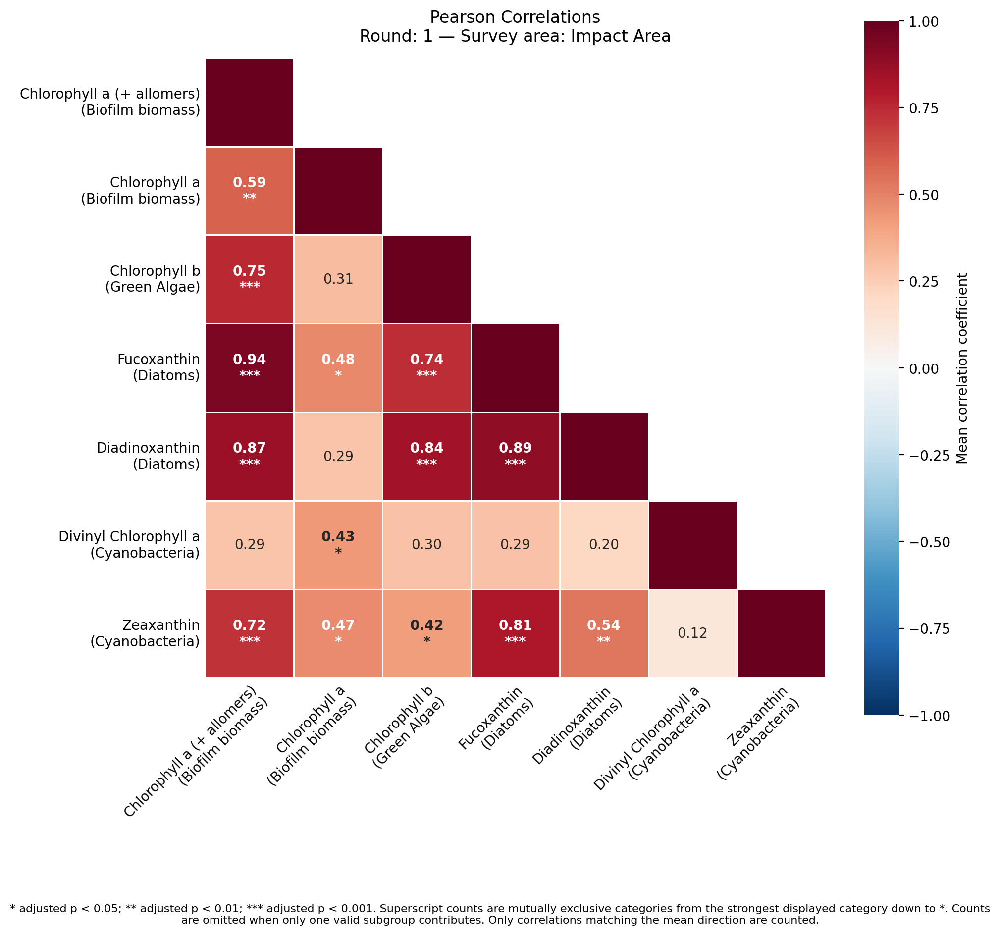

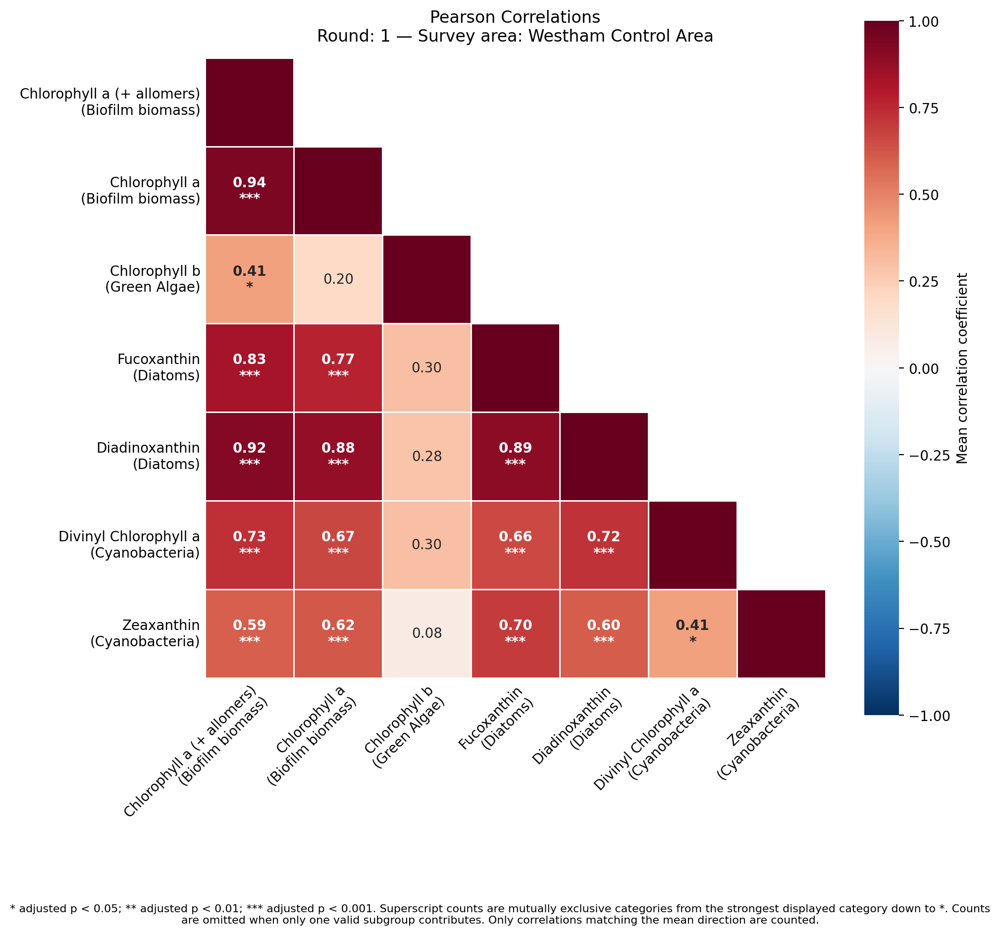

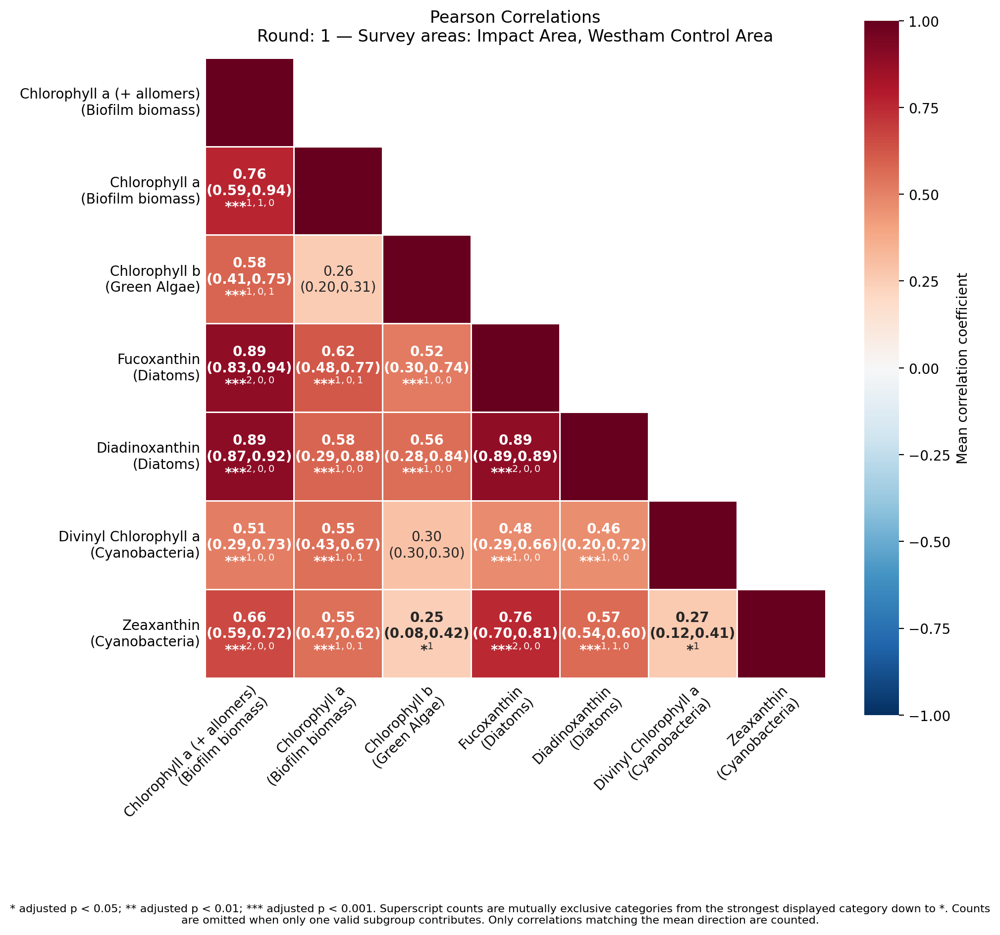

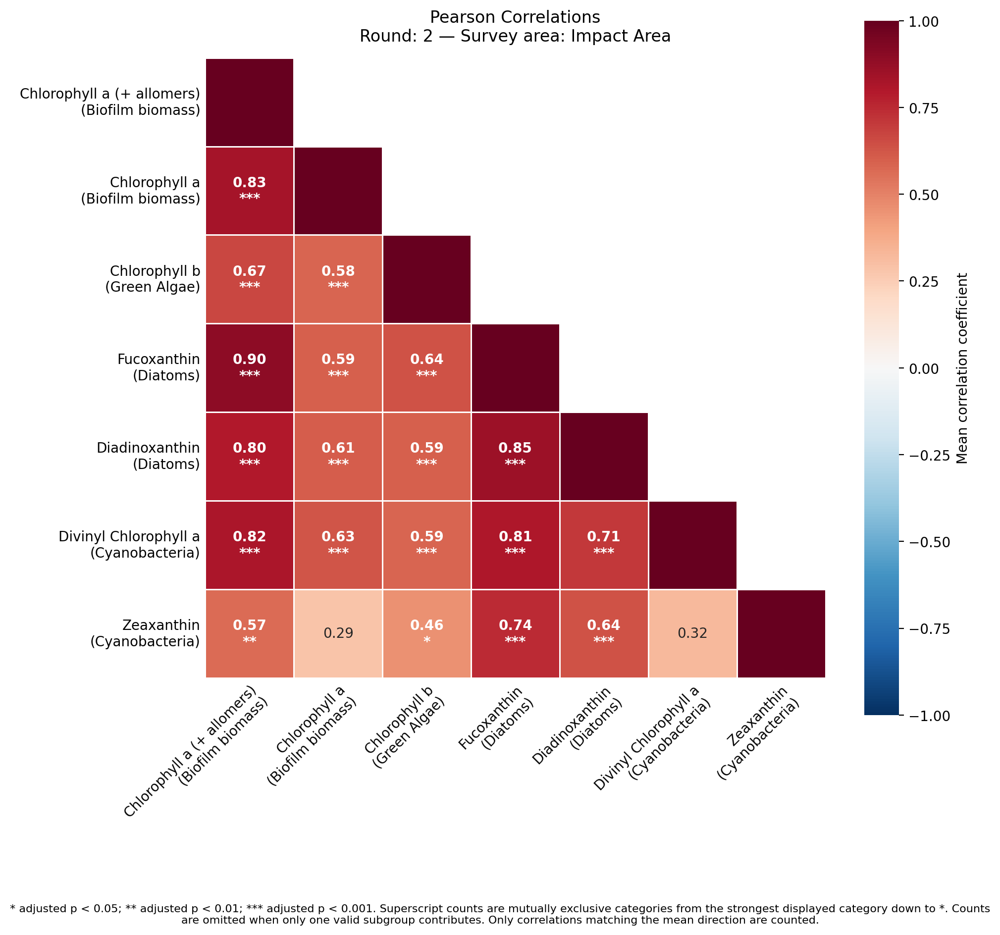

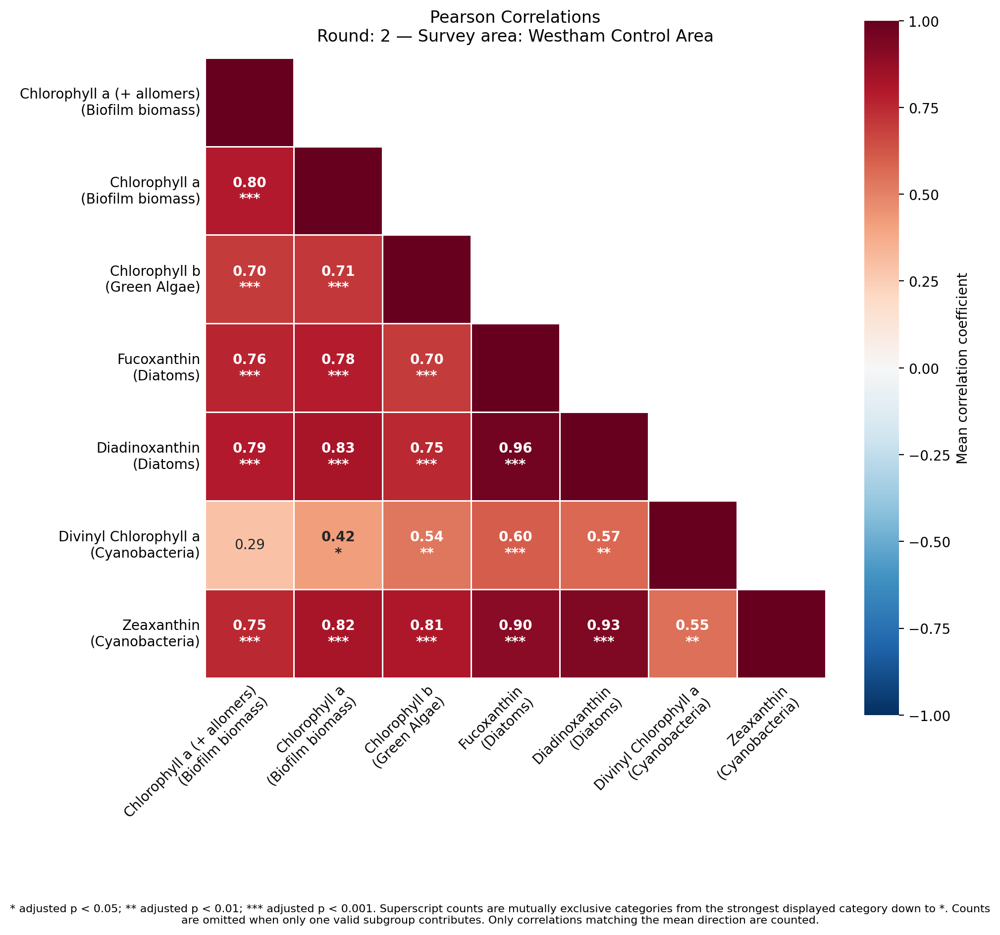

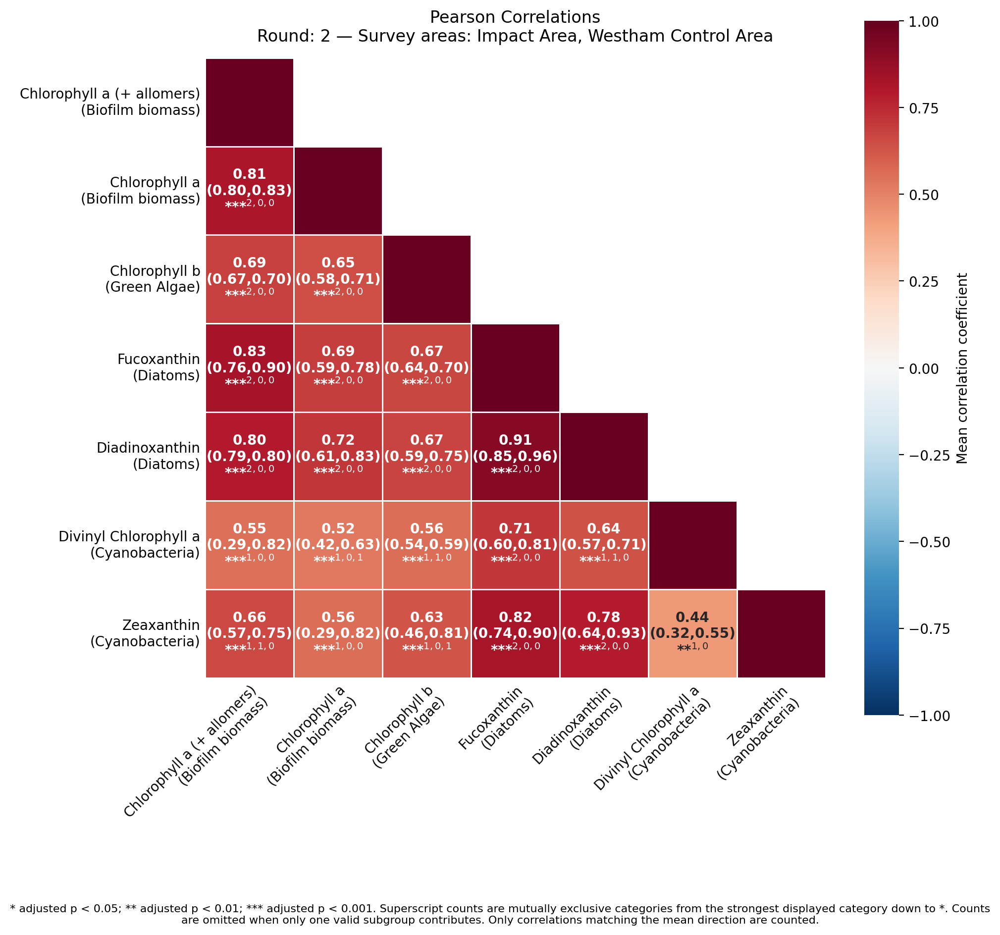

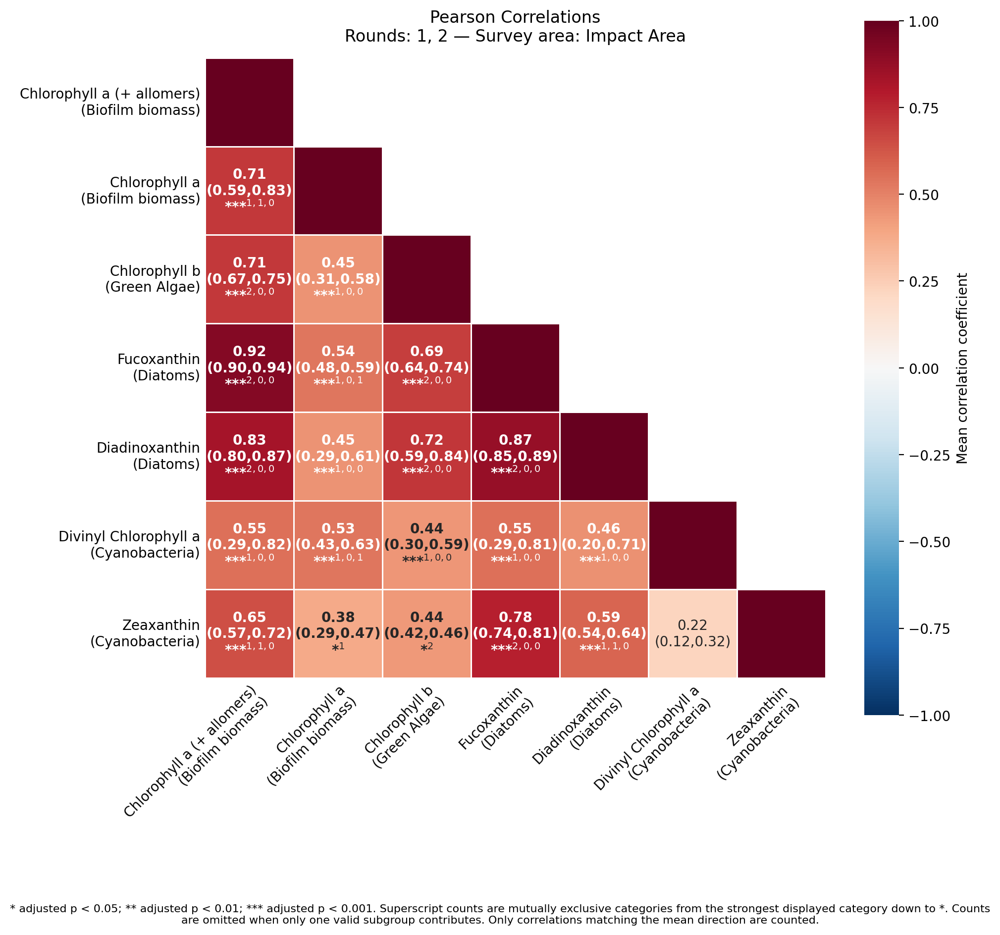

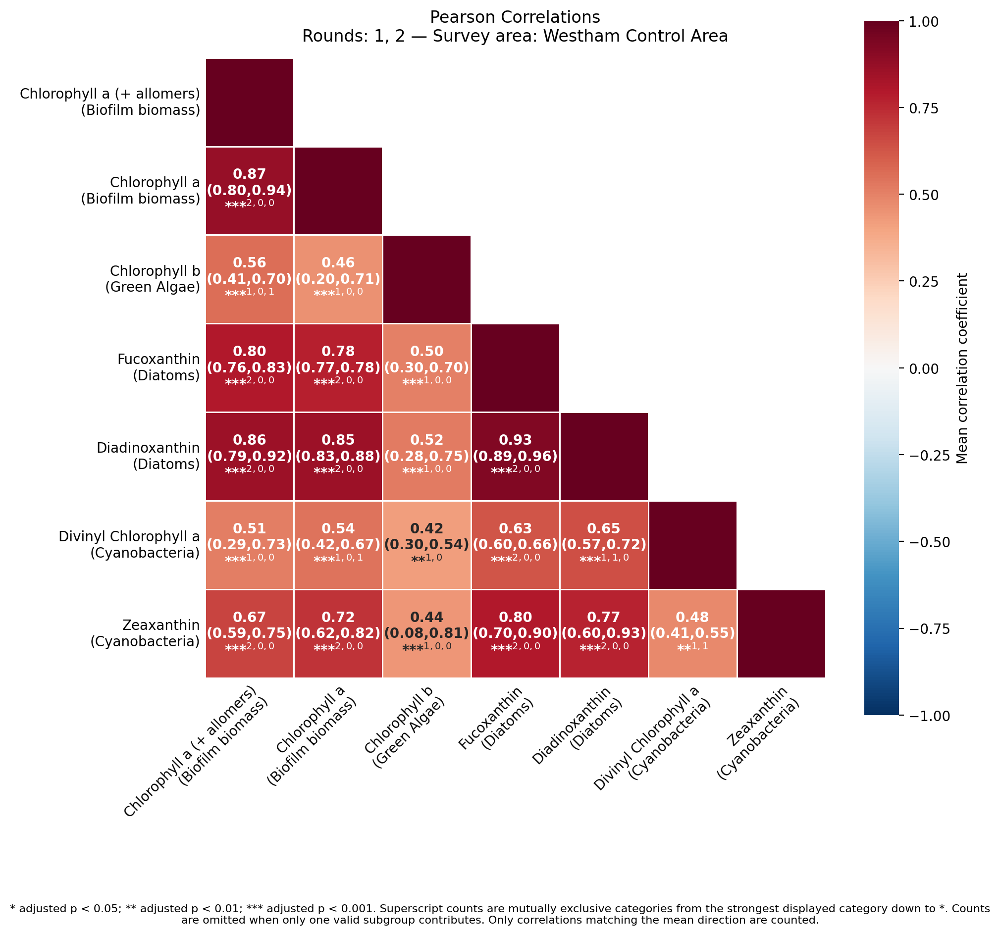

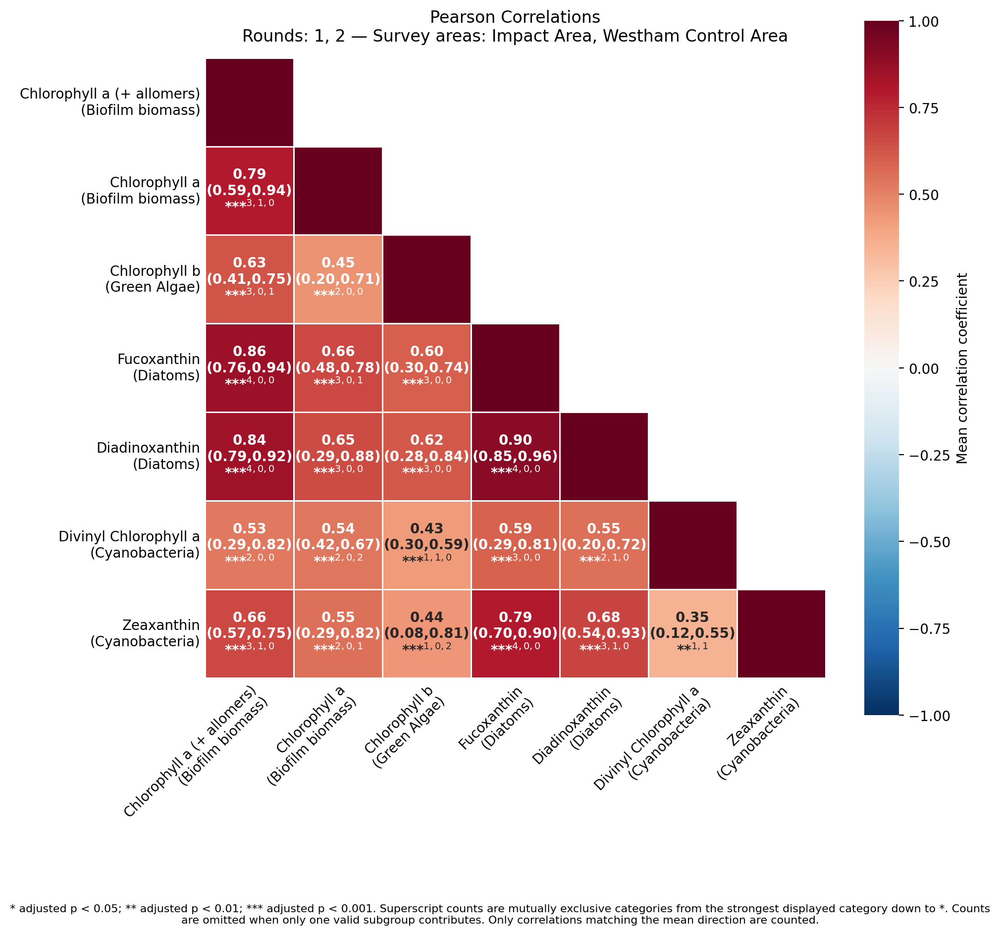

/tmp/ipykernel_31906/829524734.py:41: UserWarning: Pooled analytic p-values treat rows as independent. Repeated stations across rounds can violate that assumption; interpret these stars cautiously.
  results, fig, ax = draw_correlation_heatmap(


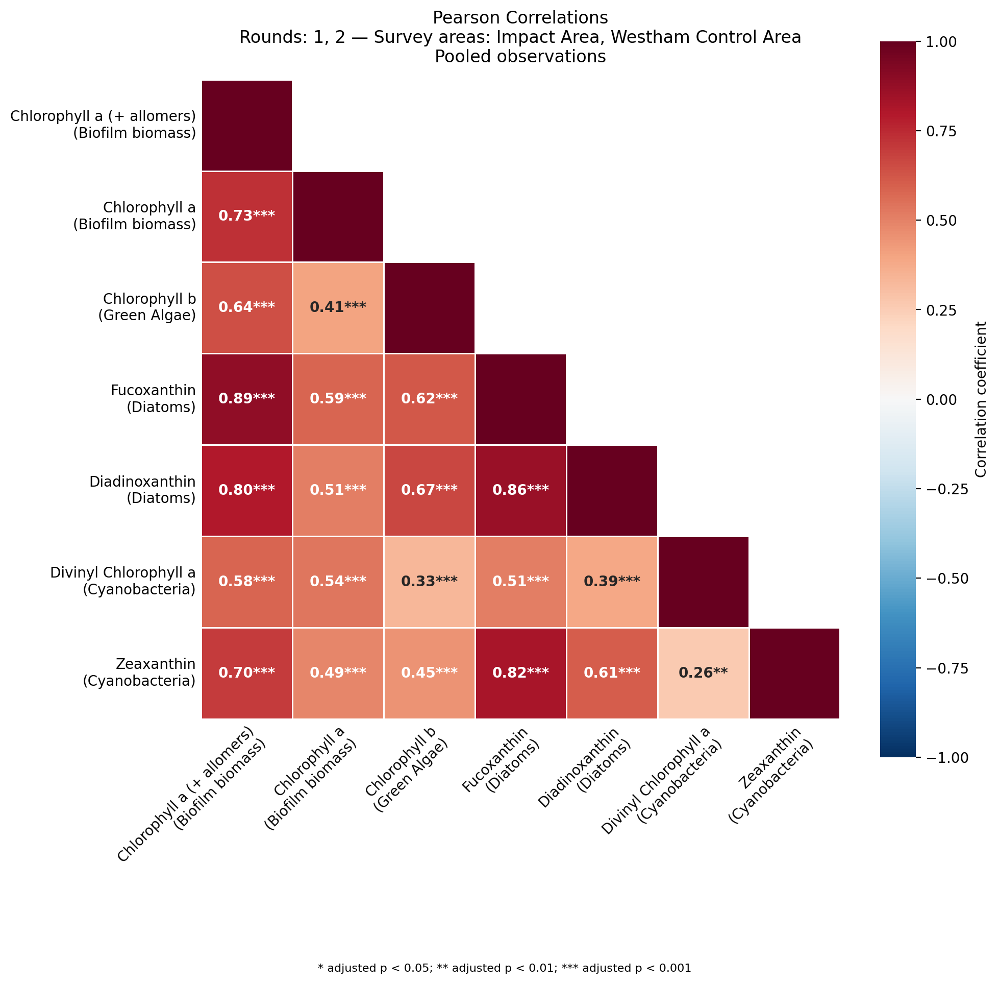

In [29]:
def _list_to_str(lst, current_str=''):
    if not isinstance(lst, (list, tuple)):
        return '_' + str(lst)
    for item in lst:
        if isinstance(item, (list, tuple)):
            current_str += '_' + _list_to_str(item)
        else:
            current_str += '_' + str(item)
    return current_str

for round_number in [1, 2, [1, 2]]:
    for site in ["brunswick", "westham", ["brunswick", "westham"]]:
        results, fig, ax = draw_correlation_heatmap(
            df=df_lab_r,
            variables=core_pigment_columns,
            round_number=round_number,
            survey_area=site,
            sites=SITES,
            site_labels=SITE_LABELS,
            variable_labels=CORE_PIGMENT_FULL_LABELS.values(),
            calculation="independent",
            independent_annotation="range"
            if isinstance(site, list) or isinstance(round_number, list)
            else "none",
            method="pearson",
            calculate_significance=True,
            p_adjust="fdr_bh",
            significance_levels=(0.05, 0.01, 0.001),
            require_same_direction=True,
            bold_significant=True,
            mask_upper=True,
            show_diagonal=True,
            show_diagonal_values=False,
            figsize=(10, 10),
        )
        path = path_output_dir / f"correlation_heatmap_core_pigments_independent_round{_list_to_str(round_number)}_site{_list_to_str(site)}.png"
        fig.savefig(path, dpi=300, bbox_inches="tight")

round_number=[1, 2]
site = ["brunswick", "westham"]
results, fig, ax = draw_correlation_heatmap(
    df=df_lab_r,
    variables=core_pigment_columns,
    round_number=round_number,
    survey_area=site,
    sites=SITES,
    site_labels=SITE_LABELS,
    variable_labels=CORE_PIGMENT_FULL_LABELS.values(),
    calculation="pooled",
    method="pearson",
    calculate_significance=True,
    p_adjust="fdr_bh",
    pooled_pvalue_method="analytic",
    significance_levels=(0.05, 0.01, 0.001),
    bold_significant=True,
    mask_upper=True,
    show_diagonal=True,
    show_diagonal_values=False,
    figsize=(10,10),
)
path = path_output_dir / f"correlation_heatmap_core_pigments_pooled_round{_list_to_str(round_number)}_site{_list_to_str(site)}.png"
fig.savefig(path, dpi=300, bbox_inches="tight")

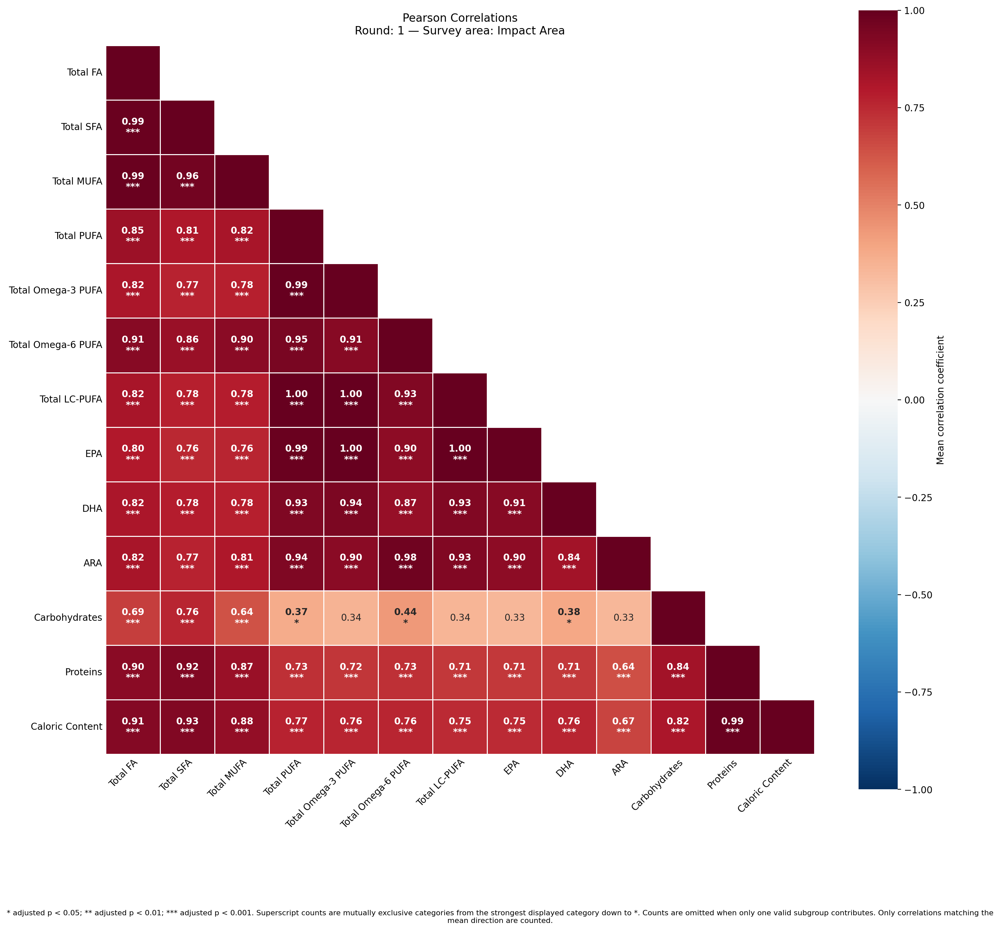

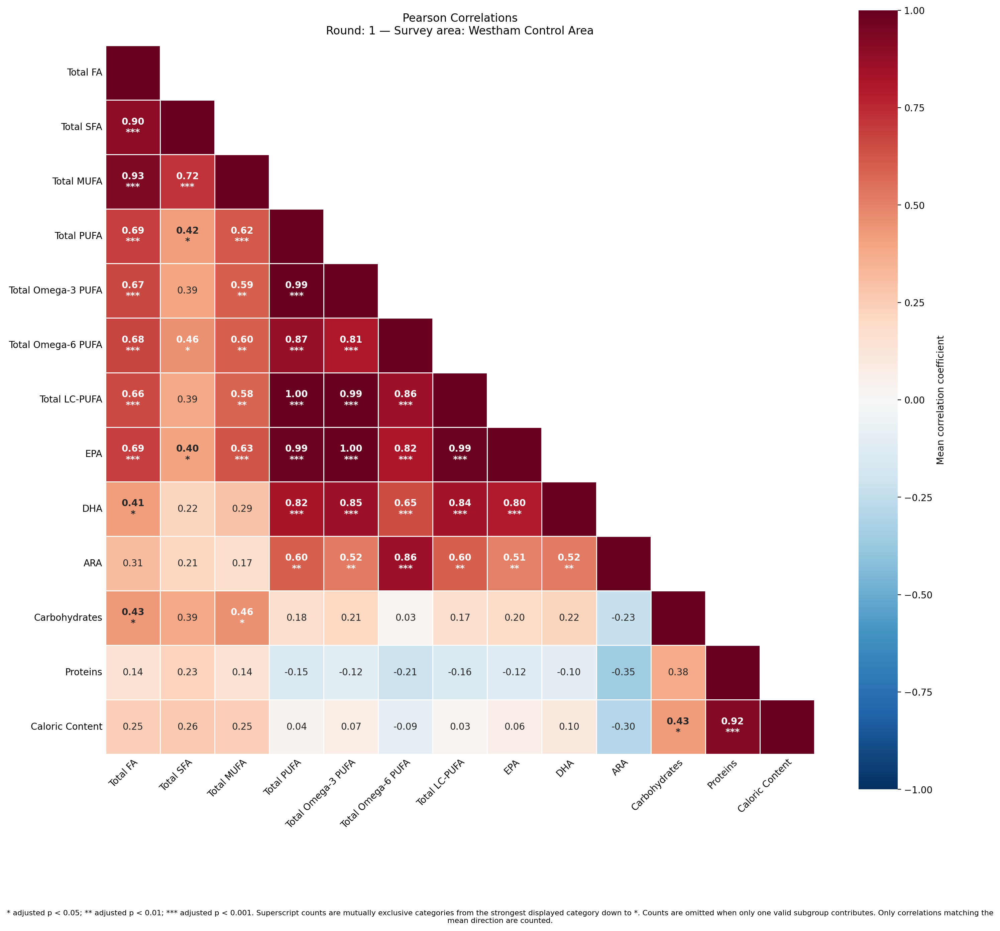

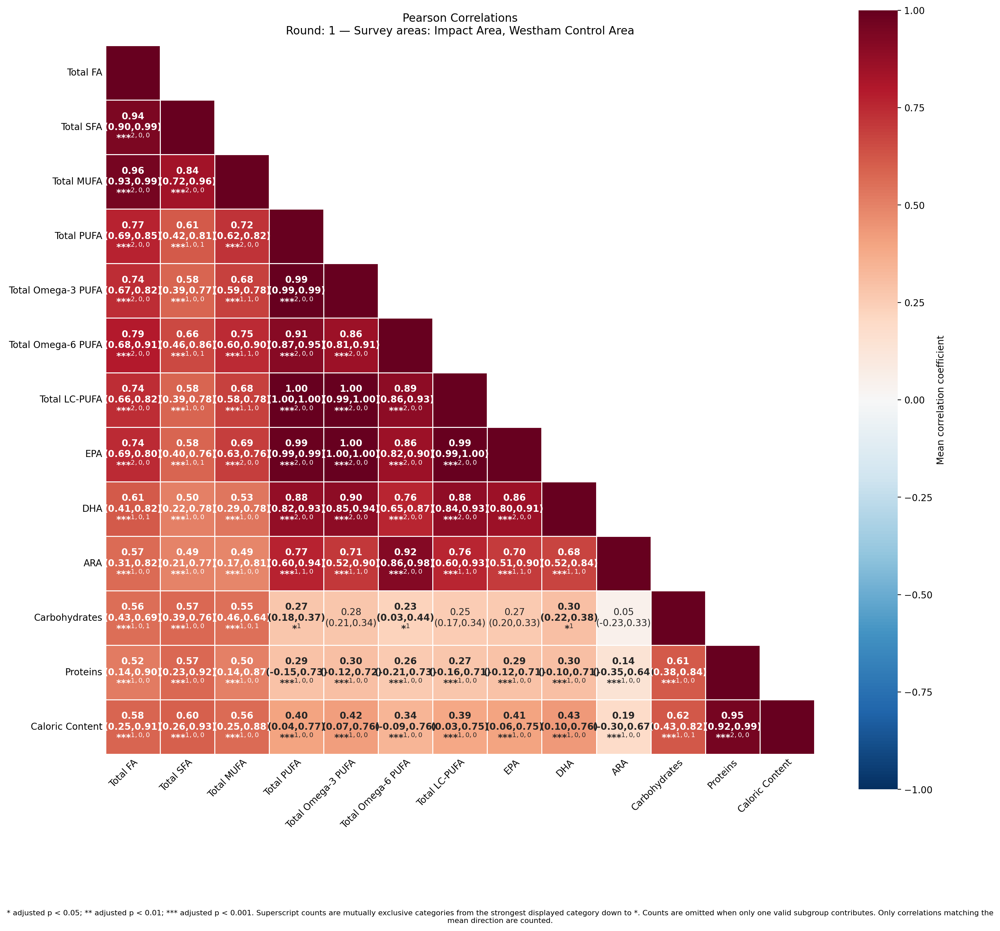

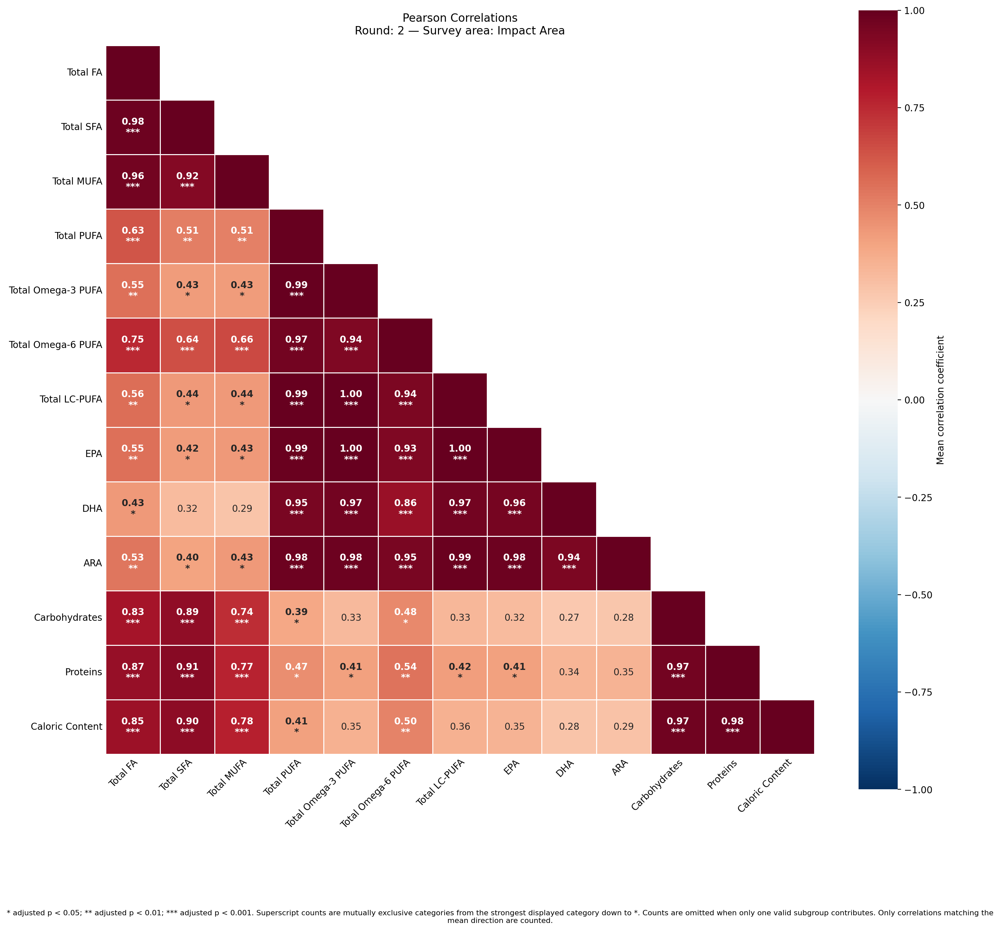

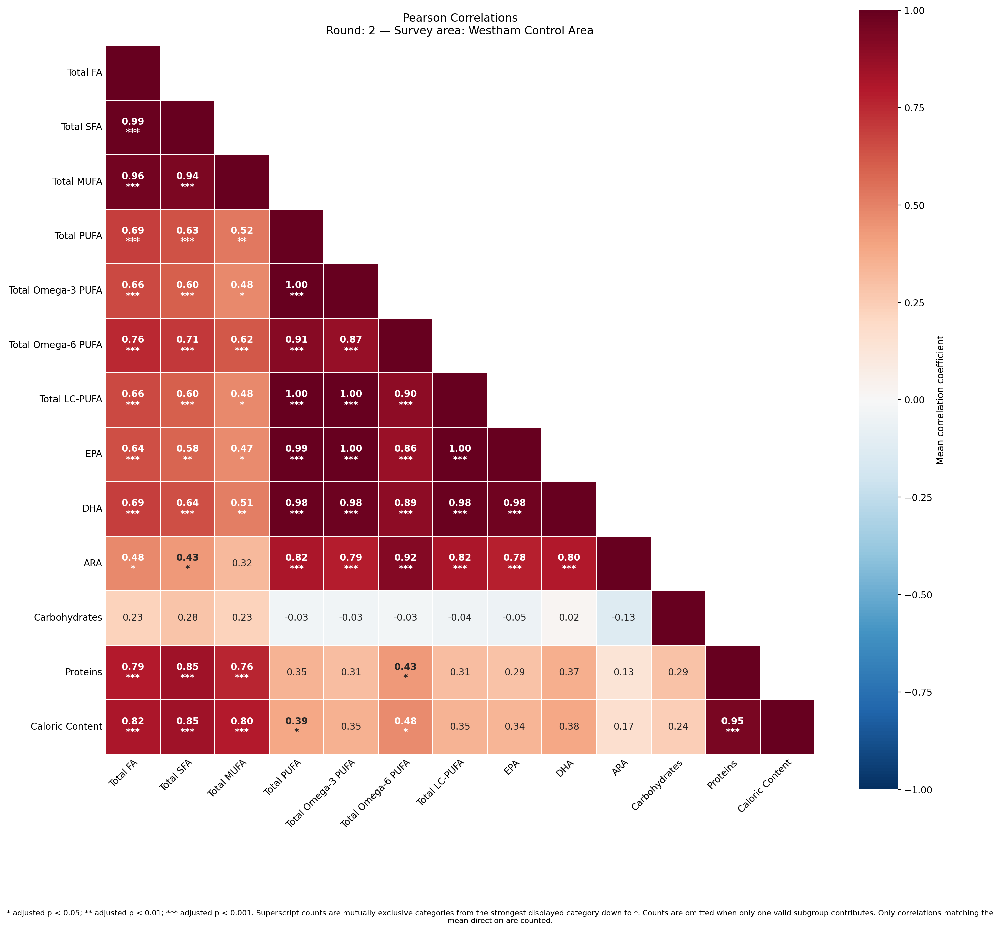

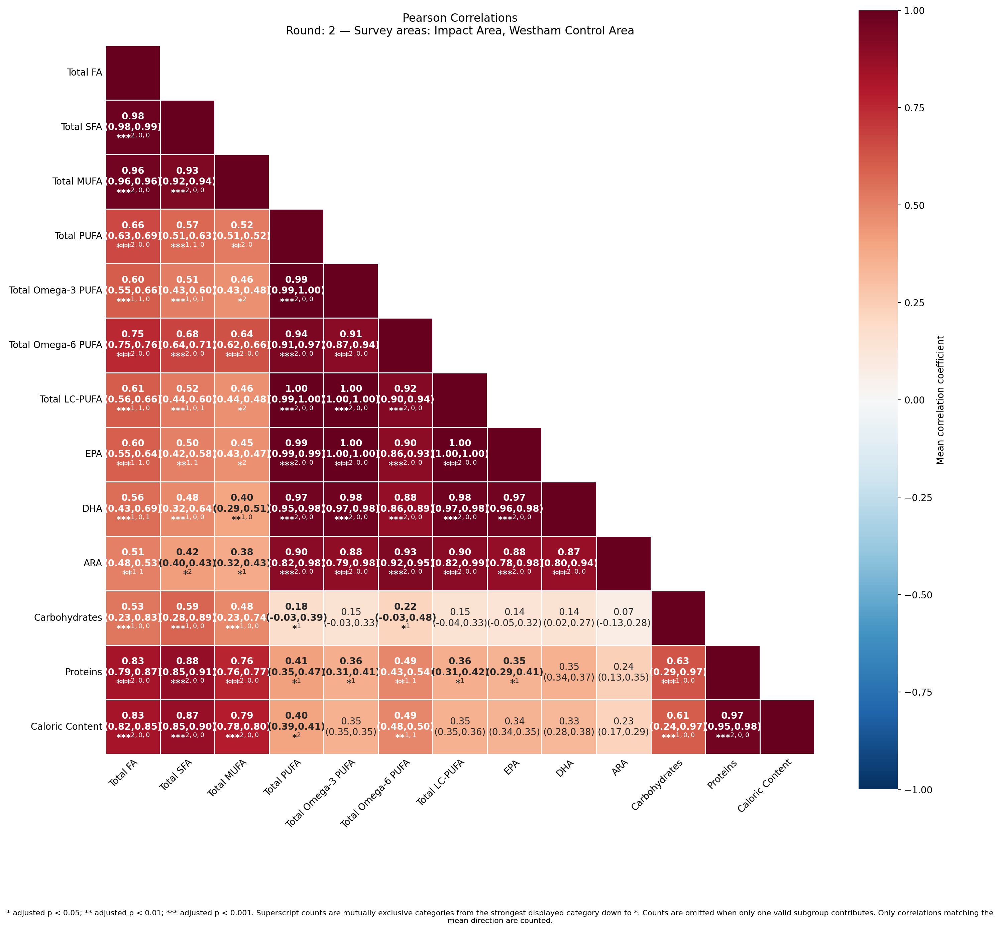

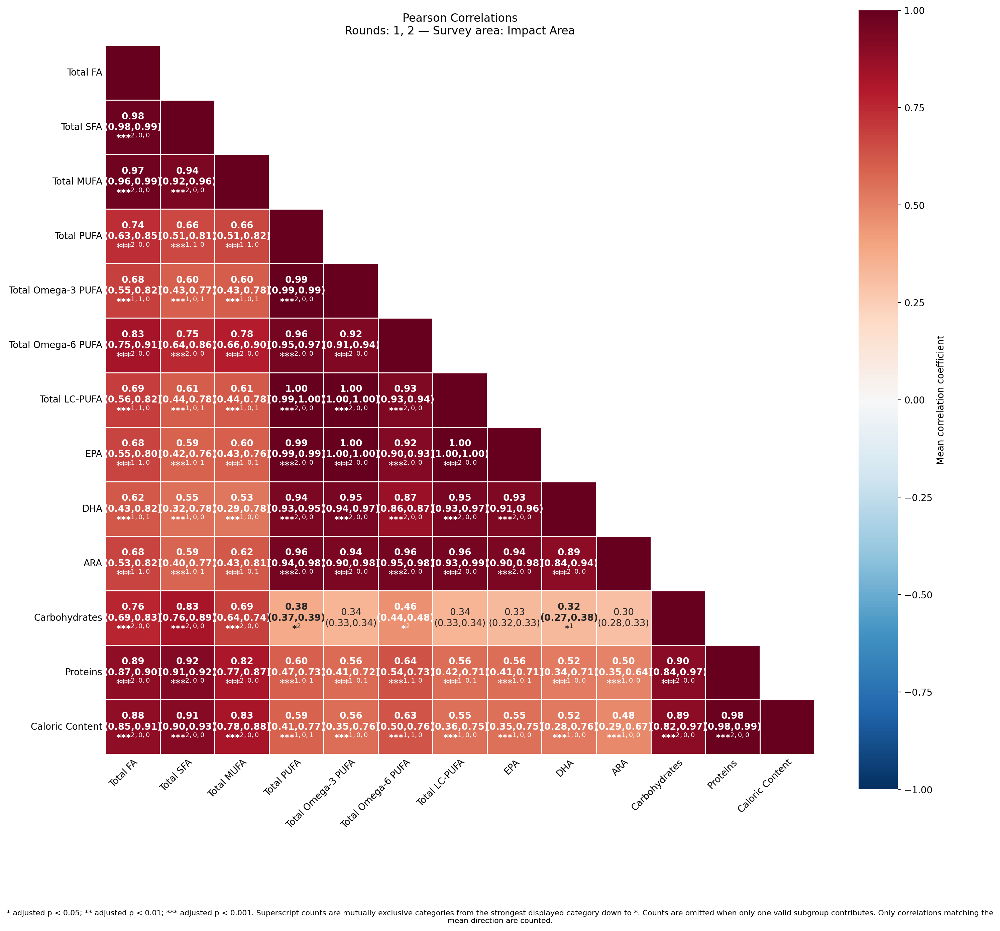

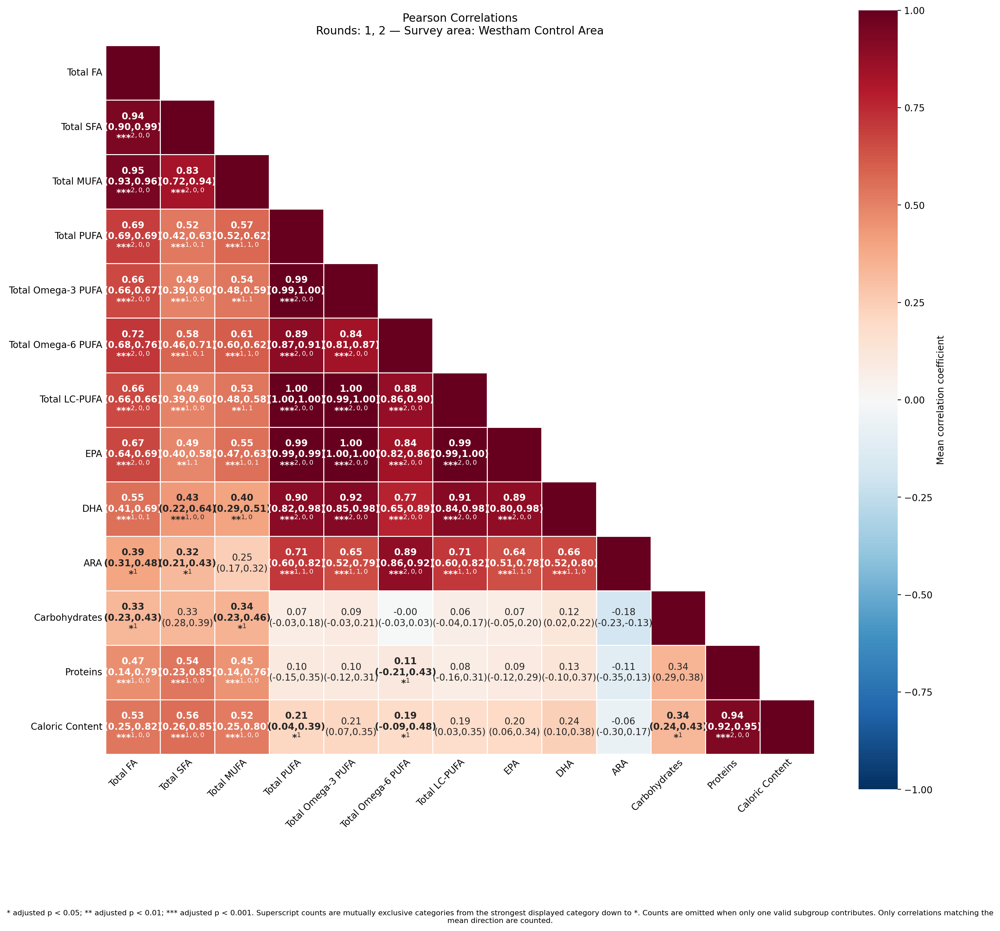

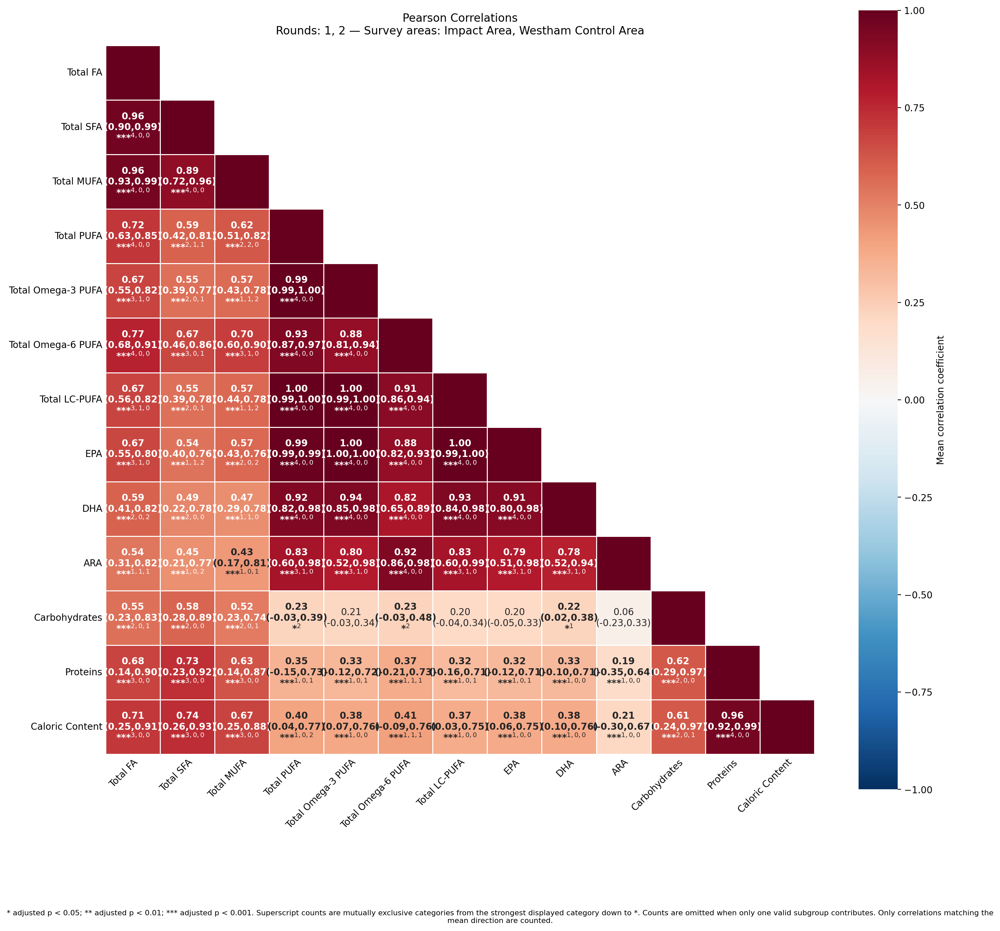

/tmp/ipykernel_31906/1629964377.py:45: UserWarning: Pooled analytic p-values treat rows as independent. Repeated stations across rounds can violate that assumption; interpret these stars cautiously.
  results, fig, ax = draw_correlation_heatmap(


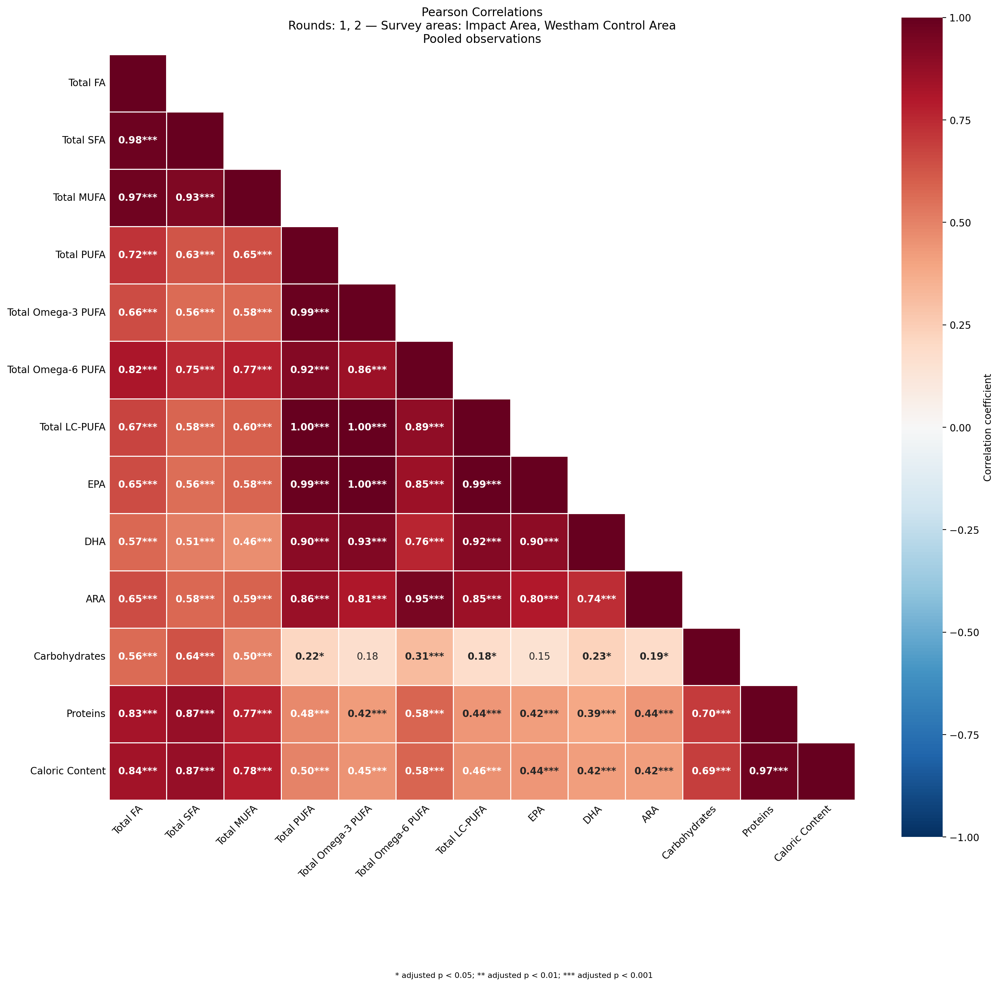

In [30]:
# Same for fatty acids and nutritional parameters

core_fa_columns = [f"{fa} ({fa_unit})" for fa in CORE_FA]
core_nutritional_columns = core_fa_columns + [
    f"Total Carbs ({fa_unit})",
    f"Proteins ({fa_unit})",
    f"Caloric (kJ/g)",
]
core_nutritional_labels = CORE_FA_LABELS + [
    "Carbohydrates",
    "Proteins",
    "Caloric Content",
]

for round_number in [1, 2, [1, 2]]:
    for site in ["brunswick", "westham", ["brunswick", "westham"]]:
        results, fig, ax = draw_correlation_heatmap(
            df=df_lab_r,
            variables=core_nutritional_columns,
            round_number=round_number,
            survey_area=site,
            sites=SITES,
            site_labels=SITE_LABELS,
            variable_labels=core_nutritional_labels,
            calculation="independent",
            independent_annotation="range"
            if isinstance(site, list) or isinstance(round_number, list)
            else "none",
            method="pearson",
            calculate_significance=True,
            p_adjust="fdr_bh",
            significance_levels=(0.05, 0.01, 0.001),
            require_same_direction=True,
            bold_significant=True,
            mask_upper=True,
            show_diagonal=True,
            show_diagonal_values=False,
            figsize=(15, 15),
        )
        path = path_output_dir / f"correlation_heatmap_core_nutritional_independent_round{_list_to_str(round_number)}_site{_list_to_str(site)}.png"
        fig.savefig(path, dpi=300, bbox_inches="tight")

round_number=[1, 2]
site = ["brunswick", "westham"]
results, fig, ax = draw_correlation_heatmap(
    df=df_lab_r,
    variables=core_nutritional_columns,
    round_number=round_number,
    survey_area=site,
    sites=SITES,
    site_labels=SITE_LABELS,
    variable_labels=core_nutritional_labels,
    calculation="pooled",
    method="pearson",
    calculate_significance=True,
    p_adjust="fdr_bh",
    pooled_pvalue_method="analytic",
    significance_levels=(0.05, 0.01, 0.001),
    bold_significant=True,
    mask_upper=True,
    show_diagonal=True,
    show_diagonal_values=False,
    figsize=(15, 15),
)
path = path_output_dir / f"correlation_heatmap_core_nutritional_pooled_round{_list_to_str(round_number)}_site{_list_to_str(site)}.png"
fig.savefig(path, dpi=300, bbox_inches="tight")


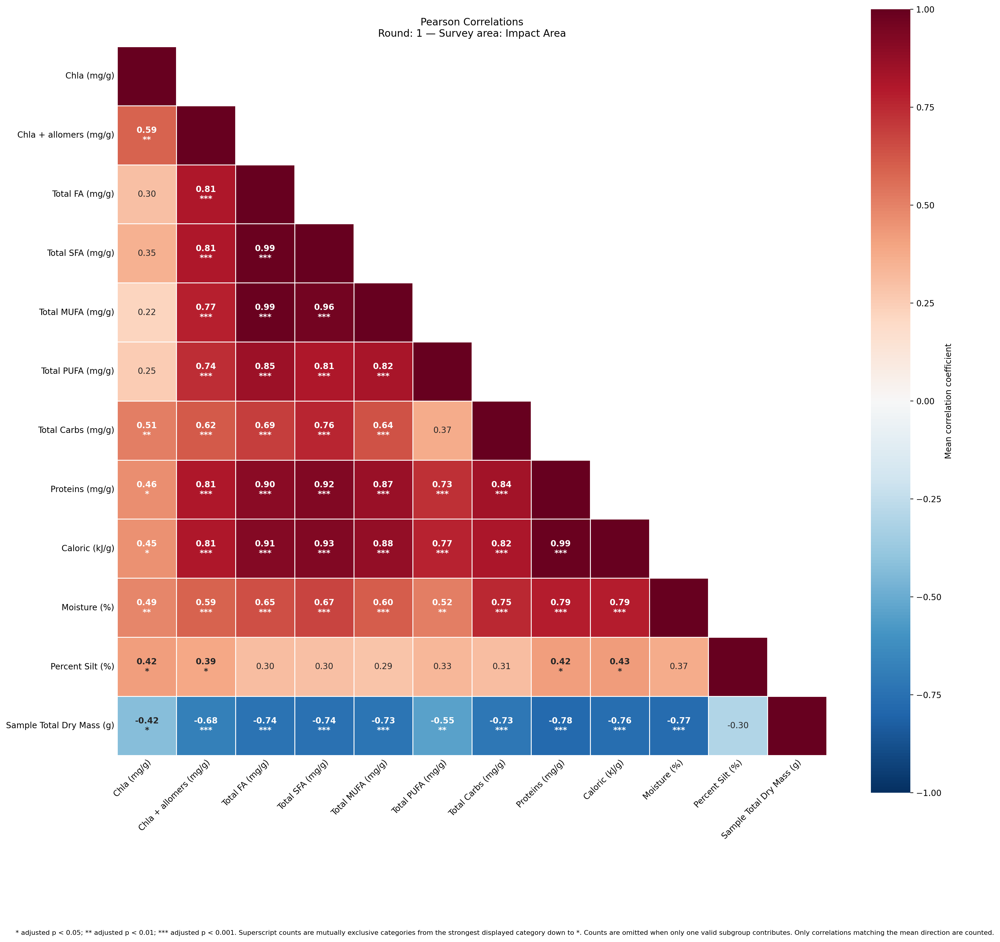

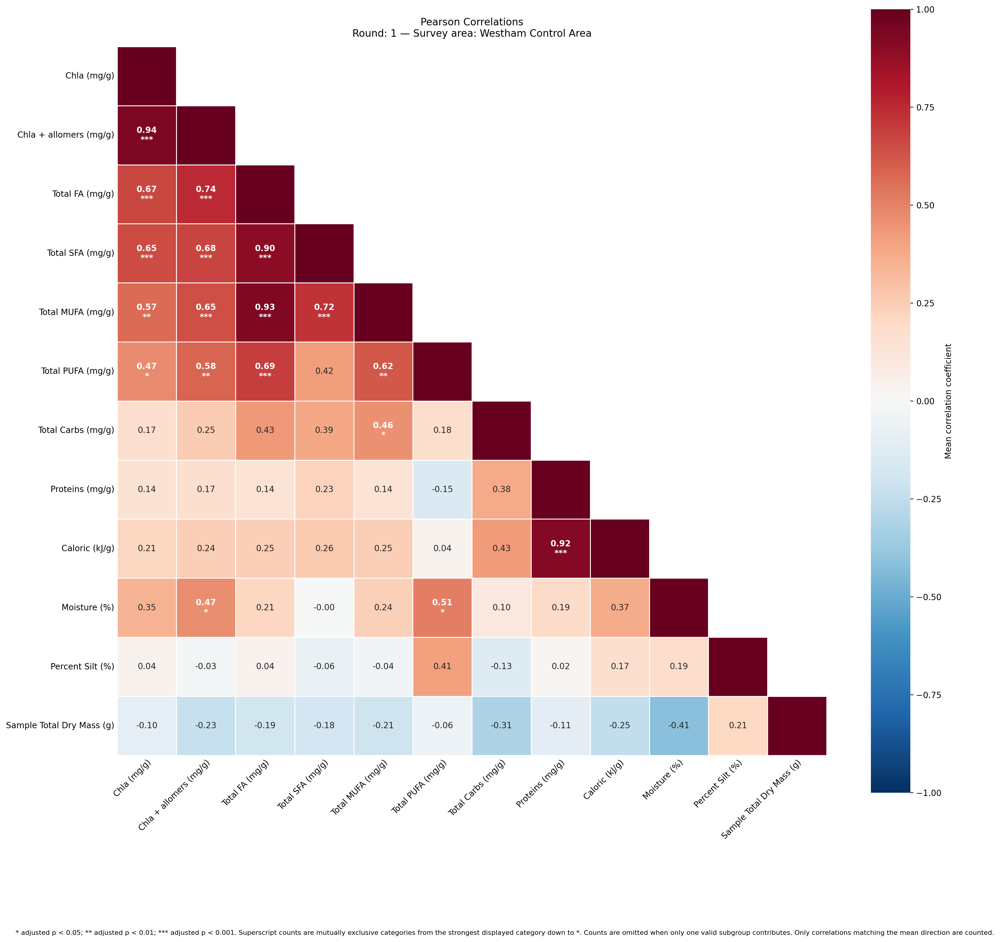

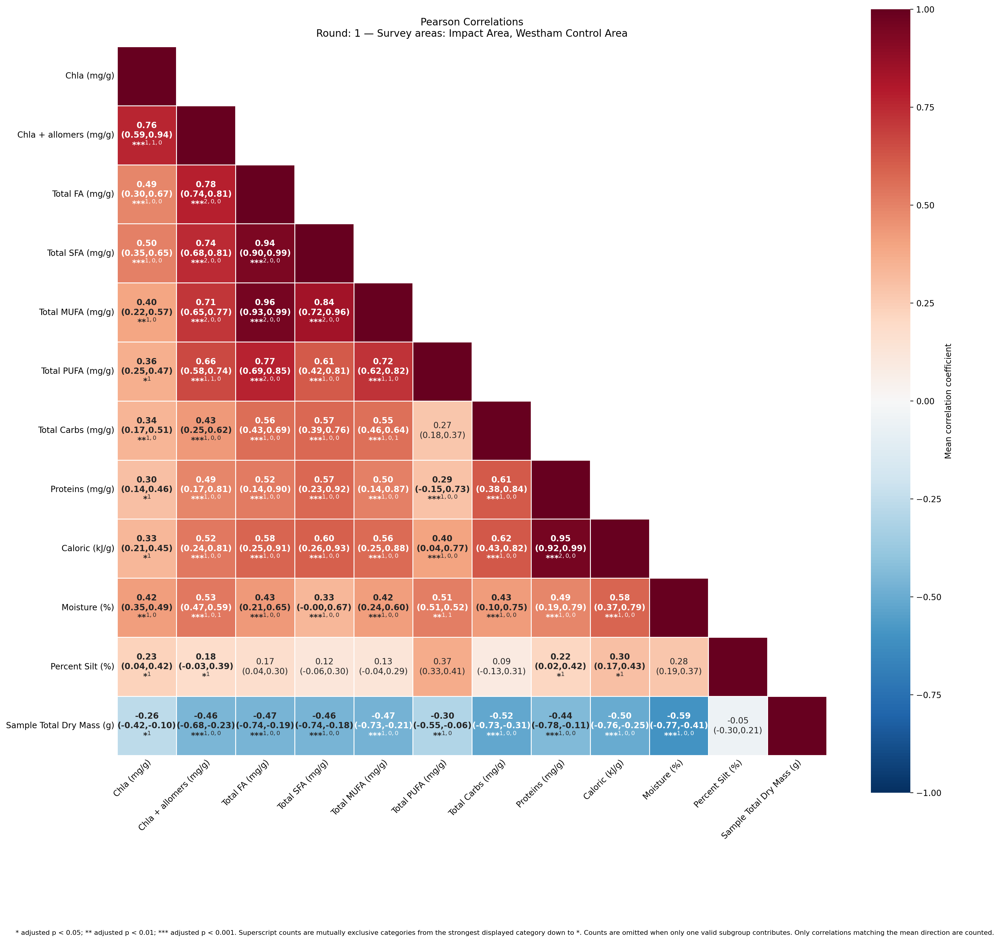

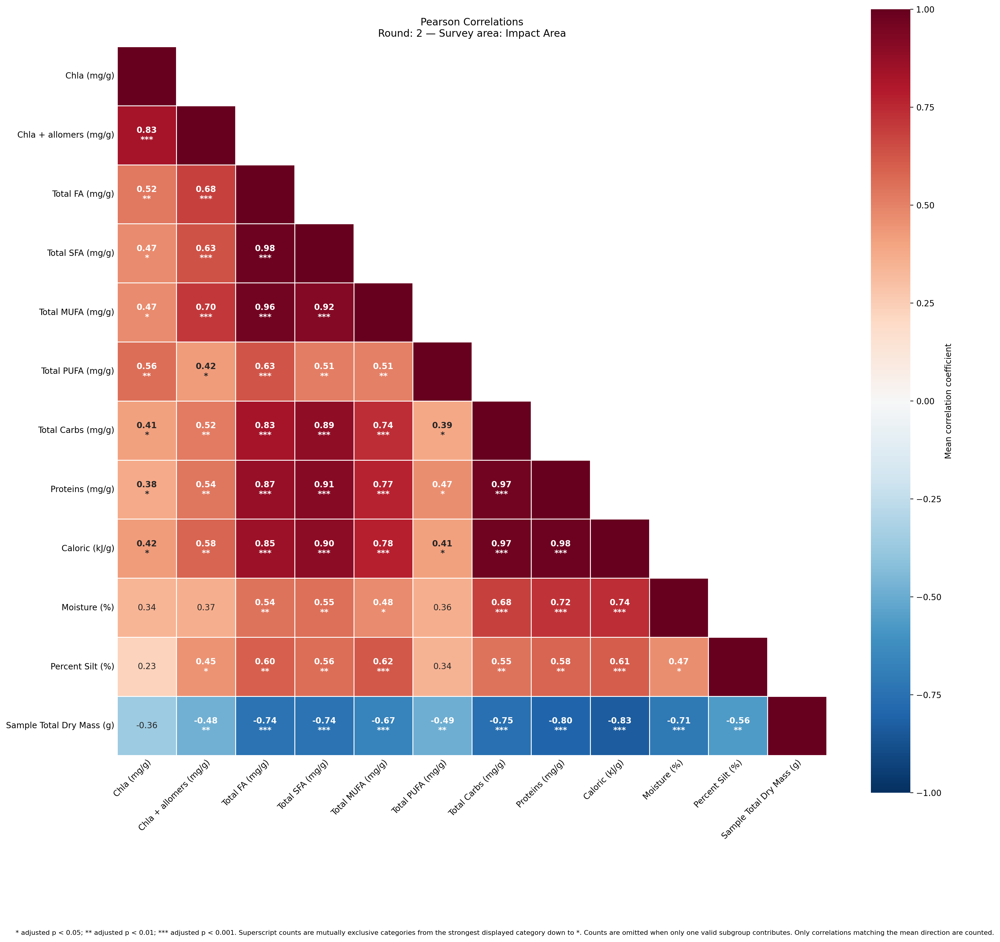

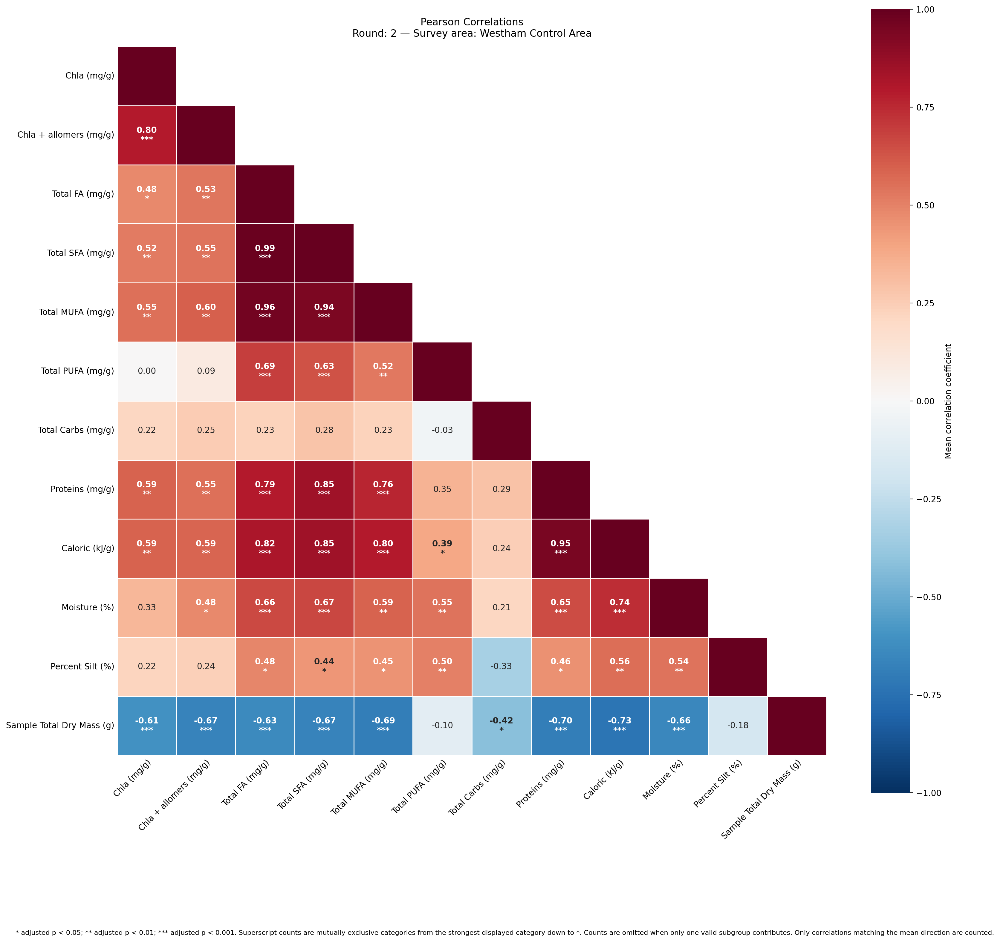

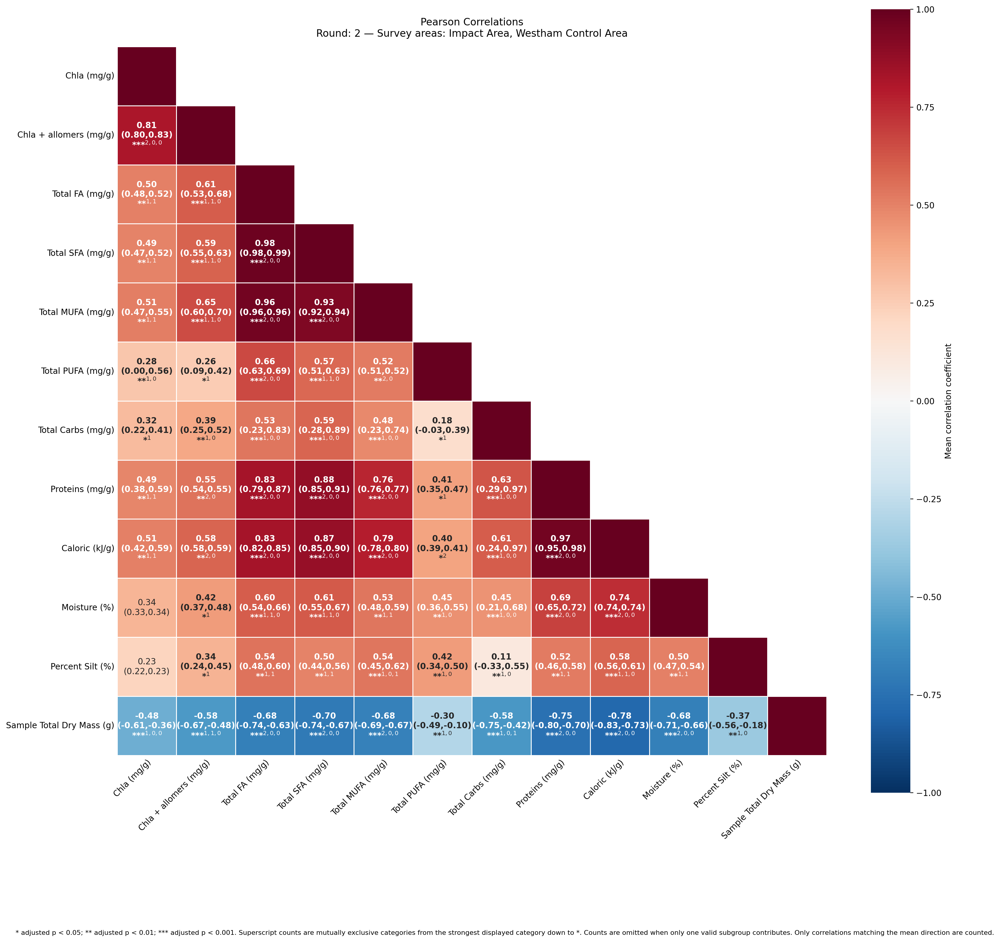

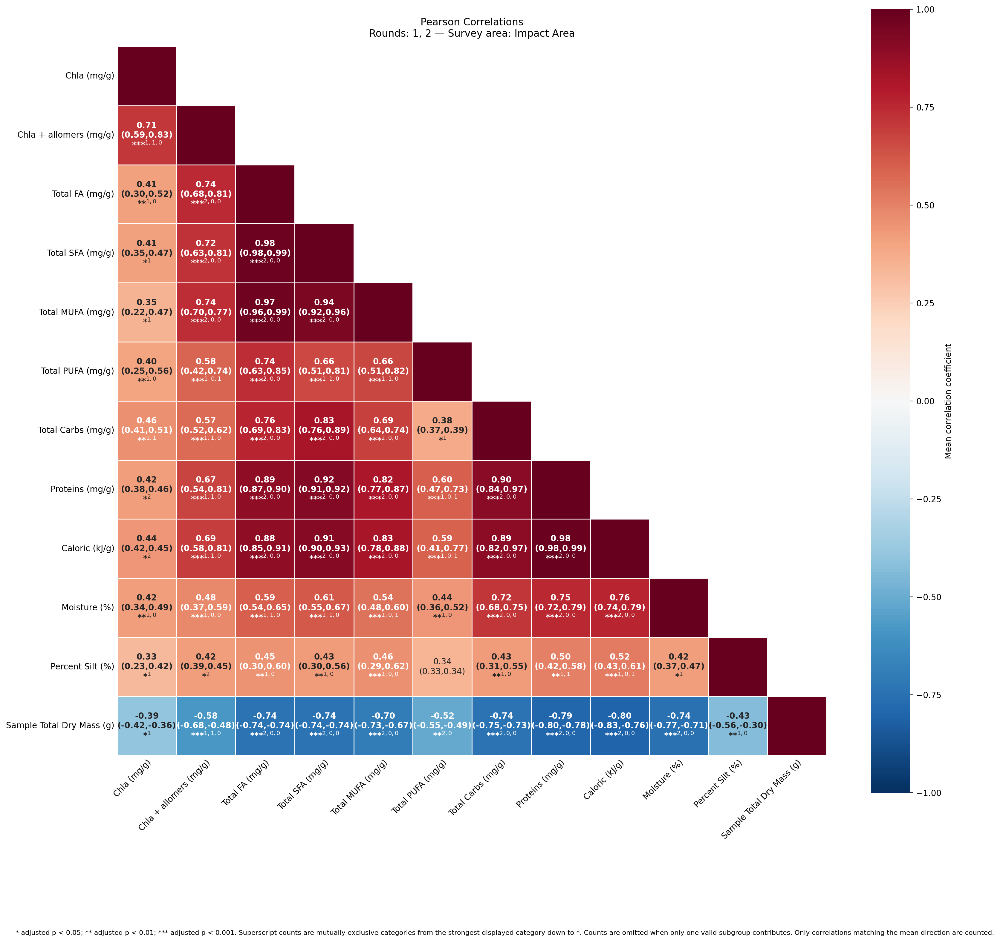

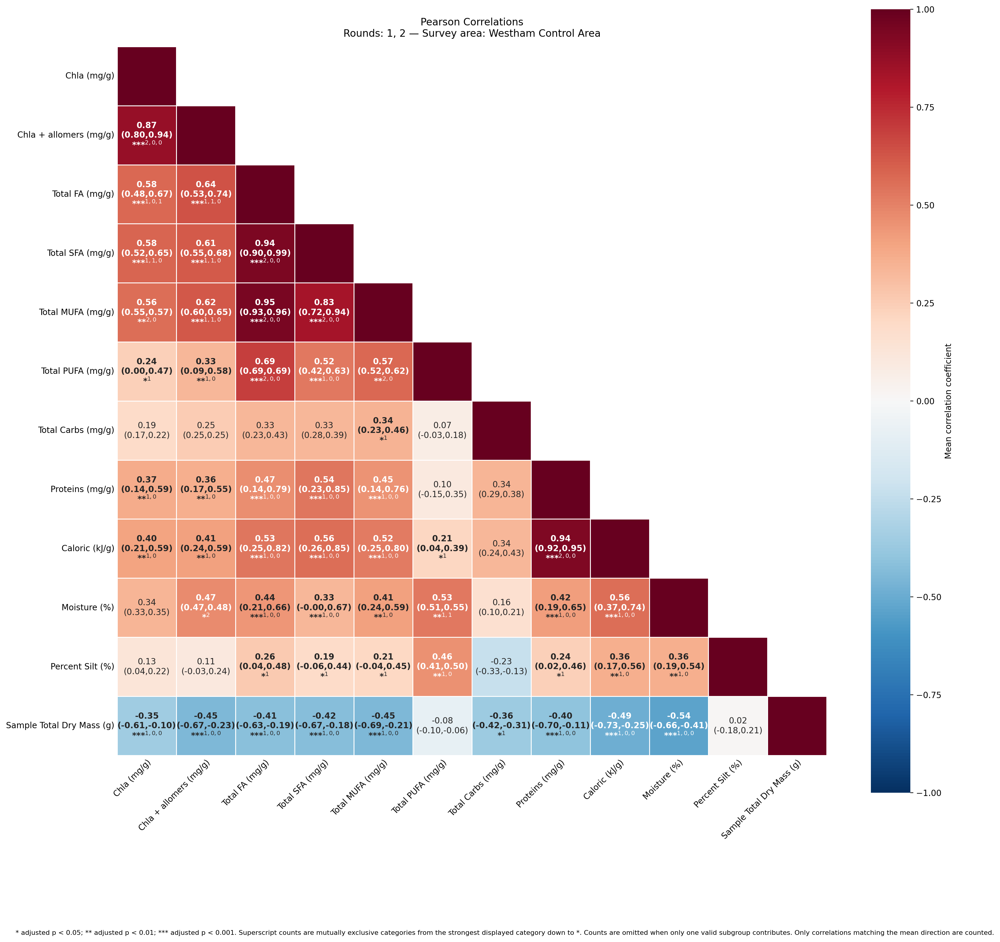

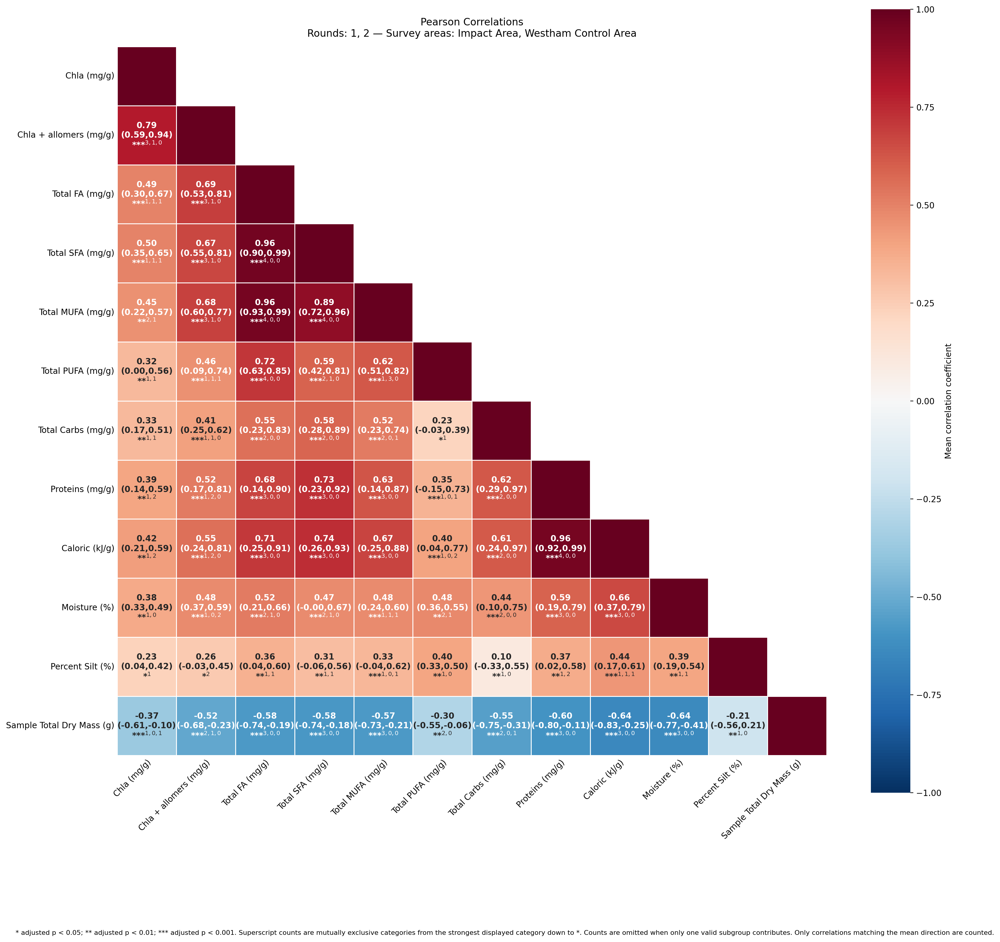

/tmp/ipykernel_31906/4158189719.py:56: UserWarning: Pooled analytic p-values treat rows as independent. Repeated stations across rounds can violate that assumption; interpret these stars cautiously.
  results, fig, ax = draw_correlation_heatmap(


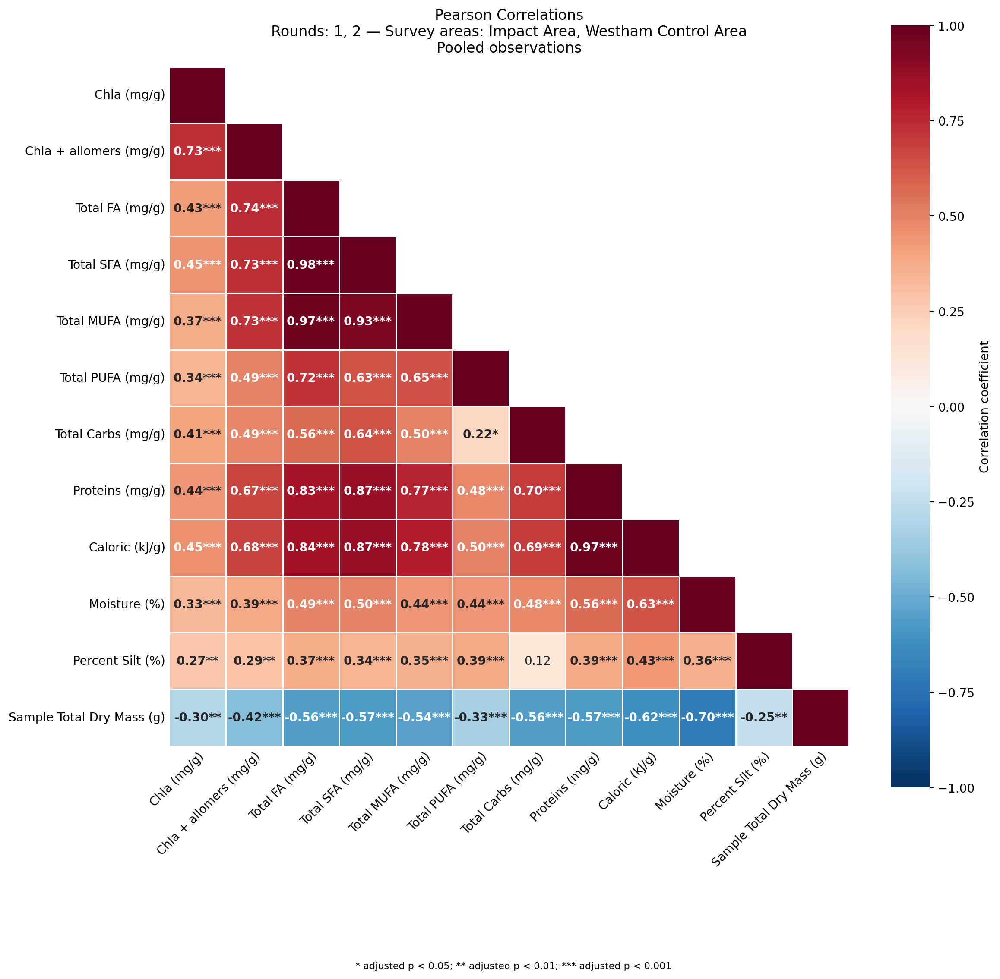

In [31]:
inter_corr_columns = [
    # Pigments
    f"Chla ({pigment_unit})",
    f"{NORMALIZING_CHLA_COLUMN} ({pigment_unit})",
    # FA
    f"Total FA ({fa_unit})",
    f"Total SFA ({fa_unit})",
    f"Total MUFA ({fa_unit})",
    f"Total PUFA ({fa_unit})",
    # Nutritional
    f"Total Carbs ({fa_unit})",
    f"Proteins ({fa_unit})",
    f"Caloric (kJ/g)",
    # Sediment composition
    "Moisture (%)",
    "Percent Silt (%)",
    # "Percent Sand (%)",
    # Contextual
    "Sample Total Dry Mass (g)",
]


for round_number in [1, 2, [1, 2]]:
    for site in ["brunswick", "westham", ["brunswick", "westham"]]:
        results, fig, ax = draw_correlation_heatmap(
            df=df_lab_r,
            variables=inter_corr_columns,
            round_number=round_number,
            survey_area=site,
            sites=SITES,
            site_labels=SITE_LABELS,
            # variable_labels=core_nutritional_labels,
            calculation="independent",
            independent_annotation="range"
            if isinstance(site, list) or isinstance(round_number, list)
            else "none",
            method="pearson",
            calculate_significance=True,
            p_adjust="fdr_bh",
            significance_levels=(0.05, 0.01, 0.001),
            require_same_direction=True,
            bold_significant=True,
            mask_upper=True,
            show_diagonal=True,
            show_diagonal_values=False,
            figsize=(17, 17),
        )
        path = (
            path_output_dir
            / f"correlation_heatmap_core_inter_categories_independent_round{_list_to_str(round_number)}_site{_list_to_str(site)}.png"
        )
        fig.savefig(path, dpi=300, bbox_inches="tight")

round_number = [1, 2]
site = ["brunswick", "westham"]
results, fig, ax = draw_correlation_heatmap(
    df=df_lab_r,
    variables=inter_corr_columns,
    round_number=round_number,
    survey_area=site,
    sites=SITES,
    site_labels=SITE_LABELS,
    # variable_labels=core_nutritional_labels,
    calculation="pooled",
    method="pearson",
    calculate_significance=True,
    p_adjust="fdr_bh",
    pooled_pvalue_method="analytic",
    significance_levels=(0.05, 0.01, 0.001),
    bold_significant=True,
    mask_upper=True,
    show_diagonal=True,
    show_diagonal_values=False,
    figsize=(12, 12),
)
path = (
    path_output_dir
    / f"correlation_heatmap_core_inter_categories_pooled_round{_list_to_str(round_number)}_site{_list_to_str(site)}.png"
)
fig.savefig(path, dpi=300, bbox_inches="tight")


In [32]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, spearmanr, kendalltau


def draw_grouped_correlation_heatmap(
    df,
    variable_groups,
    round_number=None,
    survey_area=None,
    sites=None,
    site_labels=None,
    comparison_scope="intergroup",
    calculation="independent",
    independent_annotation="range",
    variable_labels=None,
    method="pearson",
    min_periods=3,
    calculate_significance=True,
    p_adjust="fdr_bh",
    significance_levels=(0.05, 0.01, 0.001),
    require_same_direction=True,
    hide_counts_when_single_subgroup=True,
    pooled_pvalue_method="none",
    title=None,
    figsize=None,
    cmap="RdBu_r",
    annot=True,
    fmt=".2f",
    std_fmt=None,
    range_fmt=None,
    mask_upper=True,
    show_diagonal=True,
    show_diagonal_values=False,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_label=None,
    round_level="round",
    station_level="station_id",
    include_unknown=False,
    x_rotation=45,
    bold_significant=True,
    show_significance_legend=True,
    show_group_boundaries=True,
    show_group_labels=True,
    group_linecolor="black",
    group_linewidth=1.2,
    show=True,
):
    """
    Draw a correlation heatmap from a dictionary of variable groups.

    Parameters
    ----------
    variable_groups : dict
        Ordered mapping of group labels to variable lists, for example::

            {
                "Pigments": ["Chla", "Phaeo"],
                "Fatty Acids": ["Total FA", "Total PUFA"],
                "Contextual": ["Dry Mass"],
            }

        Dictionary insertion order controls variable and group order.
    comparison_scope : {"intergroup", "all"}, default "intergroup"
        ``"intergroup"`` masks correlations between variables in the same
        group and adjusts p-values only across between-group comparisons.
        ``"all"`` includes every variable pair.
    calculation : {"independent", "pooled"}
        ``"independent"`` calculates each round-survey-area matrix first,
        then displays the arithmetic mean with optional range or SD.
        ``"pooled"`` combines all selected rows into one matrix.
    independent_annotation : {"std", "range", "none"}
        Additional independent-mode annotation below the mean.
    pooled_pvalue_method : {"none", "analytic"}
        Enables conventional pooled p-values. Because stations repeat across
        rounds, ``"none"`` is the safer default.
    """

    # ------------------------------------------------------------------
    # Validate and flatten variable groups
    # ------------------------------------------------------------------
    if not isinstance(variable_groups, dict) or not variable_groups:
        raise TypeError(
            "variable_groups must be a non-empty dictionary mapping "
            "group labels to variable lists."
        )

    group_names = list(variable_groups)
    variables = []
    variable_to_group = {}
    group_positions = {}

    start_position = 0

    for group_name, group_variables in variable_groups.items():
        if not isinstance(group_variables, (list, tuple)) or not group_variables:
            raise ValueError(
                f"Group {group_name!r} must contain at least one variable."
            )

        group_variables = list(group_variables)
        end_position = start_position + len(group_variables)

        group_positions[group_name] = (
            start_position,
            end_position,
        )

        for variable in group_variables:
            if variable in variable_to_group:
                raise ValueError(
                    f"Variable {variable!r} appears in more than one group."
                )

            variables.append(variable)
            variable_to_group[variable] = group_name

        start_position = end_position

    if len(variables) < 2:
        raise ValueError(
            "At least two variables are required for a correlation matrix."
        )

    comparison_scope = comparison_scope.lower()

    if comparison_scope not in {"intergroup", "all"}:
        raise ValueError("comparison_scope must be 'intergroup' or 'all'.")

    if comparison_scope == "intergroup" and len(group_names) < 2:
        raise ValueError(
            "Intergroup correlations require at least two variable groups."
        )

    missing_variables = [
        variable for variable in variables if variable not in df.columns
    ]

    if missing_variables:
        raise KeyError(f"Variables not found in the DataFrame: {missing_variables}")

    # True means the pair belongs to the selected comparison family.
    eligible_array = np.zeros(
        (len(variables), len(variables)),
        dtype=bool,
    )

    for i, variable_x in enumerate(variables):
        for j, variable_y in enumerate(variables):
            if i == j:
                eligible_array[i, j] = comparison_scope == "all"
            elif comparison_scope == "all":
                eligible_array[i, j] = True
            else:
                eligible_array[i, j] = (
                    variable_to_group[variable_x] != variable_to_group[variable_y]
                )

    comparison_mask_original = pd.DataFrame(
        eligible_array,
        index=variables,
        columns=variables,
    )

    # ------------------------------------------------------------------
    # Helpers
    # ------------------------------------------------------------------
    def pairwise_statistics(data):
        """Return coefficient, raw-p, and paired-n matrices."""
        count = len(variables)
        coefficients = np.full((count, count), np.nan, dtype=float)
        pvalues = np.full((count, count), np.nan, dtype=float)
        sample_sizes = np.zeros((count, count), dtype=int)

        for i, variable_x in enumerate(variables):
            diagonal_n = int(data[variable_x].notna().sum())
            sample_sizes[i, i] = diagonal_n

            if diagonal_n >= min_periods:
                coefficients[i, i] = 1.0

            for j in range(i):
                variable_y = variables[j]
                pair = data[[variable_x, variable_y]].dropna()
                n = len(pair)

                sample_sizes[i, j] = n
                sample_sizes[j, i] = n

                if n < min_periods:
                    continue

                x = pair[variable_x].to_numpy(dtype=float)
                y = pair[variable_y].to_numpy(dtype=float)

                if np.all(x == x[0]) or np.all(y == y[0]):
                    continue

                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")

                    if method == "pearson":
                        result = pearsonr(x, y)
                    elif method == "spearman":
                        result = spearmanr(x, y)
                    else:
                        result = kendalltau(x, y)

                coefficient = float(result.statistic)
                pvalue = float(result.pvalue)

                coefficients[i, j] = coefficient
                coefficients[j, i] = coefficient
                pvalues[i, j] = pvalue
                pvalues[j, i] = pvalue

        return (
            pd.DataFrame(
                coefficients,
                index=variables,
                columns=variables,
            ),
            pd.DataFrame(
                pvalues,
                index=variables,
                columns=variables,
            ),
            pd.DataFrame(
                sample_sizes,
                index=variables,
                columns=variables,
            ),
        )

    def adjust_pvalue_matrix(raw_matrix):
        """
        Adjust p-values only across the selected comparison family.
        """
        adjusted = pd.DataFrame(
            np.nan,
            index=raw_matrix.index,
            columns=raw_matrix.columns,
            dtype=float,
        )

        locations = []
        raw_values = []

        for i in range(len(variables)):
            for j in range(i):
                if not eligible_array[i, j]:
                    continue

                value = raw_matrix.iat[i, j]

                if pd.notna(value):
                    locations.append((i, j))
                    raw_values.append(float(value))

        if not raw_values:
            return adjusted

        raw_values = np.asarray(raw_values, dtype=float)
        number_of_tests = len(raw_values)

        if p_adjust == "none":
            adjusted_values = raw_values.copy()

        elif p_adjust == "bonferroni":
            adjusted_values = np.minimum(
                raw_values * number_of_tests,
                1.0,
            )

        else:
            order = np.argsort(raw_values)
            ordered = raw_values[order]

            if p_adjust == "fdr_bh":
                ranks = np.arange(1, number_of_tests + 1)
                ordered_adjusted = ordered * number_of_tests / ranks
                ordered_adjusted = np.minimum.accumulate(ordered_adjusted[::-1])[::-1]

            else:  # Holm
                multipliers = number_of_tests - np.arange(number_of_tests)
                ordered_adjusted = ordered * multipliers
                ordered_adjusted = np.maximum.accumulate(ordered_adjusted)

            ordered_adjusted = np.minimum(
                ordered_adjusted,
                1.0,
            )

            adjusted_values = np.empty_like(ordered_adjusted)
            adjusted_values[order] = ordered_adjusted

        for (i, j), value in zip(
            locations,
            adjusted_values,
        ):
            adjusted.iat[i, j] = value
            adjusted.iat[j, i] = value

        return adjusted

    def apply_labels(matrix):
        if matrix is None:
            return None

        return matrix.rename(
            index=variable_label_map,
            columns=variable_label_map,
        )

    def strongest_star(adjusted_p):
        if pd.isna(adjusted_p):
            return ""

        for level_index in reversed(range(len(significance_levels))):
            if adjusted_p < significance_levels[level_index]:
                return "*" * (level_index + 1)

        return ""

    # ------------------------------------------------------------------
    # Validate general options
    # ------------------------------------------------------------------
    method = method.lower()

    if method not in {
        "pearson",
        "spearman",
        "kendall",
    }:
        raise ValueError("method must be 'pearson', 'spearman', or 'kendall'.")

    calculation = calculation.lower()

    if calculation not in {
        "independent",
        "pooled",
    }:
        raise ValueError("calculation must be 'independent' or 'pooled'.")

    independent_annotation = independent_annotation.lower()

    if independent_annotation not in {
        "std",
        "range",
        "none",
    }:
        raise ValueError("independent_annotation must be 'std', 'range', or 'none'.")

    p_adjust = p_adjust.lower()

    if p_adjust not in {
        "fdr_bh",
        "holm",
        "bonferroni",
        "none",
    }:
        raise ValueError("p_adjust must be 'fdr_bh', 'holm', 'bonferroni', or 'none'.")

    pooled_pvalue_method = pooled_pvalue_method.lower()

    if pooled_pvalue_method not in {
        "none",
        "analytic",
    }:
        raise ValueError("pooled_pvalue_method must be 'none' or 'analytic'.")

    significance_levels = tuple(float(level) for level in significance_levels)

    if (
        not significance_levels
        or any(level <= 0 or level >= 1 for level in significance_levels)
        or any(
            significance_levels[index] <= significance_levels[index + 1]
            for index in range(len(significance_levels) - 1)
        )
    ):
        raise ValueError(
            "significance_levels must be weak-to-strong, "
            "for example (0.05, 0.01, 0.001)."
        )

    if min_periods < 2:
        raise ValueError("min_periods must be at least 2.")

    required_levels = {
        round_level,
        station_level,
    }

    missing_levels = required_levels - set(df.index.names)

    if missing_levels:
        raise KeyError(
            "The DataFrame index is missing required level(s): "
            f"{sorted(missing_levels)}"
        )

    if sites is None:
        raise ValueError("'sites' must be provided.")

    sites = list(sites)

    # ------------------------------------------------------------------
    # Variable and survey-area labels
    # ------------------------------------------------------------------
    if variable_labels is None:
        variable_label_map = {variable: variable for variable in variables}

    elif isinstance(variable_labels, dict):
        variable_label_map = {
            variable: variable_labels.get(
                variable,
                variable,
            )
            for variable in variables
        }

    else:
        if len(variable_labels) != len(variables):
            raise ValueError(
                "variable_labels must have the same length "
                "as all variables in variable_groups."
            )

        variable_label_map = dict(zip(variables, variable_labels))

    if len(set(variable_label_map.values())) != len(variables):
        raise ValueError("Variable display labels must be unique.")

    if site_labels is None:
        survey_area_label_map = {area: str(area) for area in sites}

    elif isinstance(site_labels, dict):
        survey_area_label_map = {
            area: site_labels.get(
                area,
                str(area),
            )
            for area in sites
        }

    else:
        if len(site_labels) != len(sites):
            raise ValueError("site_labels must have the same length as sites.")

        survey_area_label_map = dict(zip(sites, site_labels))

    survey_area_label_map["Unknown"] = "Unknown"

    # ------------------------------------------------------------------
    # Select rounds
    # ------------------------------------------------------------------
    available_rounds = list(pd.unique(df.index.get_level_values(round_level)))

    if round_number is None:
        selected_rounds = available_rounds

    elif isinstance(
        round_number,
        (list, tuple, set),
    ):
        selected_rounds = list(round_number)

    else:
        selected_rounds = [round_number]

    missing_rounds = [
        value for value in selected_rounds if value not in set(available_rounds)
    ]

    if missing_rounds:
        raise KeyError(f"Round(s) not found in the DataFrame: {missing_rounds}")

    # ------------------------------------------------------------------
    # Select survey areas
    # ------------------------------------------------------------------
    label_to_area = {label: area for area, label in survey_area_label_map.items()}

    if survey_area is None:
        selected_area_ids = list(sites)

        if include_unknown:
            selected_area_ids.append("Unknown")

    else:
        requested_areas = (
            list(survey_area)
            if isinstance(
                survey_area,
                (list, tuple, set),
            )
            else [survey_area]
        )

        selected_area_ids = []

        for requested in requested_areas:
            if requested in sites or requested == "Unknown":
                selected_area_ids.append(requested)

            elif requested in label_to_area:
                selected_area_ids.append(label_to_area[requested])

            else:
                raise KeyError(f"Unknown survey area: {requested!r}")

    selected_area_ids = list(dict.fromkeys(selected_area_ids))

    if "Unknown" in selected_area_ids and not include_unknown:
        raise ValueError("Set include_unknown=True to include Unknown.")

    # ------------------------------------------------------------------
    # Filter data
    # ------------------------------------------------------------------
    round_mask = df.index.get_level_values(round_level).isin(selected_rounds)

    data = df.loc[round_mask, variables].copy().reset_index()

    if data.empty:
        raise ValueError("No rows remained after round filtering.")

    def infer_survey_area(station_id):
        station_id = str(station_id)

        return next(
            (area for area in sites if station_id.startswith(str(area)[0].upper())),
            "Unknown",
        )

    data["_survey_area_id"] = data[station_level].map(infer_survey_area)

    data = data.loc[data["_survey_area_id"].isin(selected_area_ids)].copy()

    if data.empty:
        raise ValueError("No rows remained after survey-area filtering.")

    nonnumeric = [
        variable
        for variable in variables
        if not pd.api.types.is_numeric_dtype(data[variable])
    ]

    if nonnumeric:
        raise TypeError(f"Correlation variables must be numeric: {nonnumeric}")

    # ------------------------------------------------------------------
    # Calculate matrices
    # ------------------------------------------------------------------
    group_correlations = {}
    group_p_values_raw = {}
    group_p_values_adjusted = {}
    group_sample_sizes = {}

    pooled_p_values_raw = None
    pooled_p_values_adjusted = None

    if calculation == "pooled":
        (
            mean_correlation,
            calculated_p_values,
            pooled_sample_sizes,
        ) = pairwise_statistics(data)

        std_correlation = None
        min_correlation = None
        max_correlation = None

        valid_group_counts = mean_correlation.notna().astype(int)

        group_correlations["pooled"] = mean_correlation.copy()
        group_sample_sizes["pooled"] = pooled_sample_sizes

        if calculate_significance and pooled_pvalue_method == "analytic":
            warnings.warn(
                "Pooled analytic p-values treat rows as "
                "independent. Repeated stations across rounds "
                "can violate that assumption; interpret these "
                "stars cautiously.",
                UserWarning,
                stacklevel=2,
            )

            pooled_p_values_raw = calculated_p_values
            pooled_p_values_adjusted = adjust_pvalue_matrix(pooled_p_values_raw)

            group_p_values_raw["pooled"] = pooled_p_values_raw.copy()
            group_p_values_adjusted["pooled"] = pooled_p_values_adjusted.copy()

    else:
        for (
            current_round,
            area_id,
        ), subgroup in data.groupby(
            [
                round_level,
                "_survey_area_id",
            ],
            observed=True,
            sort=False,
        ):
            (
                correlation_matrix,
                raw_p_matrix,
                sample_size_matrix,
            ) = pairwise_statistics(subgroup)

            group_key = (
                current_round,
                survey_area_label_map.get(
                    area_id,
                    str(area_id),
                ),
            )

            group_correlations[group_key] = correlation_matrix
            group_sample_sizes[group_key] = sample_size_matrix

            if calculate_significance:
                group_p_values_raw[group_key] = raw_p_matrix
                group_p_values_adjusted[group_key] = adjust_pvalue_matrix(raw_p_matrix)

        if not group_correlations:
            raise ValueError("No round-survey-area subgroups were available.")

        coefficient_stack = np.stack(
            [matrix.to_numpy(dtype=float) for matrix in group_correlations.values()],
            axis=0,
        )

        valid = np.isfinite(coefficient_stack)
        valid_counts_array = valid.sum(axis=0)

        coefficient_sum = np.where(
            valid,
            coefficient_stack,
            0.0,
        ).sum(axis=0)

        mean_array = np.divide(
            coefficient_sum,
            valid_counts_array,
            out=np.full_like(
                coefficient_sum,
                np.nan,
                dtype=float,
            ),
            where=valid_counts_array > 0,
        )

        squared_deviations = np.where(
            valid,
            (coefficient_stack - mean_array) ** 2,
            0.0,
        ).sum(axis=0)

        std_array = np.sqrt(
            np.divide(
                squared_deviations,
                valid_counts_array - 1,
                out=np.full_like(
                    squared_deviations,
                    np.nan,
                ),
                where=valid_counts_array > 1,
            )
        )

        min_array = np.where(
            valid,
            coefficient_stack,
            np.inf,
        ).min(axis=0)

        min_array = np.where(
            valid_counts_array > 0,
            min_array,
            np.nan,
        )

        max_array = np.where(
            valid,
            coefficient_stack,
            -np.inf,
        ).max(axis=0)

        max_array = np.where(
            valid_counts_array > 0,
            max_array,
            np.nan,
        )

        mean_correlation = pd.DataFrame(
            mean_array,
            index=variables,
            columns=variables,
        )
        std_correlation = pd.DataFrame(
            std_array,
            index=variables,
            columns=variables,
        )
        min_correlation = pd.DataFrame(
            min_array,
            index=variables,
            columns=variables,
        )
        max_correlation = pd.DataFrame(
            max_array,
            index=variables,
            columns=variables,
        )
        valid_group_counts = pd.DataFrame(
            valid_counts_array,
            index=variables,
            columns=variables,
        )

    # ------------------------------------------------------------------
    # Significance labels
    # ------------------------------------------------------------------
    significance_labels = pd.DataFrame(
        "",
        index=variables,
        columns=variables,
        dtype=object,
    )

    significance_symbols = pd.DataFrame(
        "",
        index=variables,
        columns=variables,
        dtype=object,
    )

    exclusive_category_count_matrices = {
        "*" * (index + 1): pd.DataFrame(
            0,
            index=variables,
            columns=variables,
            dtype=int,
        )
        for index in range(len(significance_levels))
    }

    nonsignificant_counts = pd.DataFrame(
        0,
        index=variables,
        columns=variables,
        dtype=int,
    )

    opposite_direction_significant_counts = pd.DataFrame(
        0,
        index=variables,
        columns=variables,
        dtype=int,
    )

    valid_subgroup_test_counts = pd.DataFrame(
        0,
        index=variables,
        columns=variables,
        dtype=int,
    )

    if calculate_significance:
        if calculation == "independent":
            group_keys = list(group_correlations)

            for i in range(len(variables)):
                for j in range(i):
                    if not eligible_array[i, j]:
                        continue

                    mean_value = mean_correlation.iat[i, j]

                    category_counts = [0 for _ in significance_levels]

                    nonsignificant_count = 0
                    opposite_count = 0
                    valid_subgroup_count = 0

                    for group_key in group_keys:
                        subgroup_r = group_correlations[group_key].iat[i, j]

                        adjusted_p = group_p_values_adjusted[group_key].iat[i, j]

                        if pd.isna(subgroup_r) or pd.isna(adjusted_p):
                            continue

                        valid_subgroup_count += 1

                        same_direction = not require_same_direction or (
                            pd.notna(mean_value)
                            and mean_value != 0
                            and np.sign(subgroup_r) == np.sign(mean_value)
                        )

                        category_index = None

                        for index in reversed(range(len(significance_levels))):
                            if adjusted_p < significance_levels[index]:
                                category_index = index
                                break

                        if not same_direction:
                            if category_index is not None:
                                opposite_count += 1
                            continue

                        if category_index is None:
                            nonsignificant_count += 1
                        else:
                            category_counts[category_index] += 1

                    valid_subgroup_test_counts.iat[i, j] = valid_subgroup_count
                    valid_subgroup_test_counts.iat[j, i] = valid_subgroup_count

                    for index, count in enumerate(category_counts):
                        symbol = "*" * (index + 1)

                        exclusive_category_count_matrices[symbol].iat[i, j] = count

                        exclusive_category_count_matrices[symbol].iat[j, i] = count

                    nonsignificant_counts.iat[i, j] = nonsignificant_count
                    nonsignificant_counts.iat[j, i] = nonsignificant_count

                    opposite_direction_significant_counts.iat[i, j] = opposite_count
                    opposite_direction_significant_counts.iat[j, i] = opposite_count

                    strongest_index = None

                    for index in reversed(range(len(significance_levels))):
                        if category_counts[index] > 0:
                            strongest_index = index
                            break

                    if strongest_index is not None:
                        symbol = "*" * (strongest_index + 1)

                        displayed_counts = [
                            category_counts[index]
                            for index in range(
                                strongest_index,
                                -1,
                                -1,
                            )
                        ]

                        if (
                            hide_counts_when_single_subgroup
                            and valid_subgroup_count == 1
                        ):
                            label = symbol
                        else:
                            counts_text = ",".join(
                                str(value) for value in displayed_counts
                            )

                            # MathText superscripts the complete
                            # sequence, including commas.
                            label = (
                                rf"{symbol}"
                                rf"$^{{{counts_text}}}$"
                            )

                        significance_symbols.iat[i, j] = symbol
                        significance_symbols.iat[j, i] = symbol

                        significance_labels.iat[i, j] = label
                        significance_labels.iat[j, i] = label

        elif pooled_p_values_adjusted is not None:
            for i in range(len(variables)):
                for j in range(i):
                    if not eligible_array[i, j]:
                        continue

                    symbol = strongest_star(pooled_p_values_adjusted.iat[i, j])

                    significance_symbols.iat[i, j] = symbol
                    significance_symbols.iat[j, i] = symbol

                    significance_labels.iat[i, j] = symbol
                    significance_labels.iat[j, i] = symbol

    # ------------------------------------------------------------------
    # Apply display labels
    # ------------------------------------------------------------------
    mean_correlation = apply_labels(mean_correlation)
    std_correlation = apply_labels(std_correlation)
    min_correlation = apply_labels(min_correlation)
    max_correlation = apply_labels(max_correlation)
    valid_group_counts = apply_labels(valid_group_counts)
    significance_labels = apply_labels(significance_labels)
    significance_symbols = apply_labels(significance_symbols)
    nonsignificant_counts = apply_labels(nonsignificant_counts)
    opposite_direction_significant_counts = apply_labels(
        opposite_direction_significant_counts
    )
    valid_subgroup_test_counts = apply_labels(valid_subgroup_test_counts)

    comparison_mask = comparison_mask_original.rename(
        index=variable_label_map,
        columns=variable_label_map,
    )

    exclusive_category_count_matrices = {
        symbol: apply_labels(matrix)
        for symbol, matrix in exclusive_category_count_matrices.items()
    }

    labelled_group_correlations = {
        key: apply_labels(matrix) for key, matrix in group_correlations.items()
    }

    labelled_group_p_values_raw = {
        key: apply_labels(matrix) for key, matrix in group_p_values_raw.items()
    }

    labelled_group_p_values_adjusted = {
        key: apply_labels(matrix) for key, matrix in group_p_values_adjusted.items()
    }

    labelled_group_sample_sizes = {
        key: apply_labels(matrix) for key, matrix in group_sample_sizes.items()
    }

    pooled_p_values_raw = apply_labels(pooled_p_values_raw)
    pooled_p_values_adjusted = apply_labels(pooled_p_values_adjusted)

    # ------------------------------------------------------------------
    # Plot matrix and mask
    # ------------------------------------------------------------------
    plot_mean = mean_correlation.copy()
    plot_std = None if std_correlation is None else std_correlation.copy()
    plot_min = None if min_correlation is None else min_correlation.copy()
    plot_max = None if max_correlation is None else max_correlation.copy()
    plot_significance_labels = significance_labels.copy()
    plot_significance_symbols = significance_symbols.copy()

    heatmap_mask = ~comparison_mask.to_numpy(dtype=bool)

    if mask_upper:
        heatmap_mask |= np.triu(
            np.ones_like(
                heatmap_mask,
                dtype=bool,
            ),
            k=1,
        )

    if not show_diagonal:
        np.fill_diagonal(
            heatmap_mask,
            True,
        )

    if comparison_scope == "intergroup":
        np.fill_diagonal(
            heatmap_mask,
            True,
        )

    # ------------------------------------------------------------------
    # Build annotations
    # ------------------------------------------------------------------
    if std_fmt is None:
        std_fmt = fmt

    if range_fmt is None:
        range_fmt = fmt

    heatmap_annotations = False

    if annot:
        heatmap_annotations = np.empty(
            plot_mean.shape,
            dtype=object,
        )

        for i in range(plot_mean.shape[0]):
            for j in range(plot_mean.shape[1]):
                if heatmap_mask[i, j]:
                    heatmap_annotations[i, j] = ""
                    continue

                mean_value = plot_mean.iat[i, j]

                if pd.isna(mean_value):
                    label = ""

                else:
                    lines = [format(mean_value, fmt)]

                    if calculation == "independent":
                        if independent_annotation == "std":
                            spread = plot_std.iat[i, j]

                            if pd.notna(spread):
                                lines.append(f"({format(spread, std_fmt)})")

                        elif independent_annotation == "range":
                            minimum = plot_min.iat[i, j]
                            maximum = plot_max.iat[i, j]

                            if pd.notna(minimum) and pd.notna(maximum):
                                lines.append(
                                    f"("
                                    f"{format(minimum, range_fmt)}"
                                    f"–"
                                    f"{format(maximum, range_fmt)}"
                                    f")"
                                )

                        significance_label = plot_significance_labels.iat[i, j]

                        if significance_label:
                            lines.append(significance_label)

                    else:
                        symbol = plot_significance_symbols.iat[i, j]

                        if symbol:
                            lines[0] = lines[0] + symbol

                    label = "\n".join(lines)

                heatmap_annotations[i, j] = label

        if show_diagonal and not show_diagonal_values:
            np.fill_diagonal(
                heatmap_annotations,
                "",
            )

    # ------------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------------
    if figsize is None:
        extra_height = (
            0.2 if (calculation == "independent" and calculate_significance) else 0
        )

        figsize = (
            max(
                7,
                len(variables) * 0.9,
            ),
            max(
                6,
                len(variables) * (0.75 + extra_height),
            ),
        )

    fig, ax = plt.subplots(figsize=figsize)

    if cbar_label is None:
        cbar_label = (
            "Mean correlation coefficient"
            if calculation == "independent"
            else "Correlation coefficient"
        )

    sns.heatmap(
        plot_mean,
        mask=heatmap_mask,
        annot=heatmap_annotations,
        fmt="",
        cmap=cmap,
        vmin=-1,
        vmax=1,
        center=0,
        square=square,
        linewidths=linewidths,
        linecolor=linecolor,
        cbar_kws={
            "label": cbar_label,
            "shrink": 0.85,
        },
        ax=ax,
    )

    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(
        axis="both",
        length=0,
    )

    plt.setp(
        ax.get_xticklabels(),
        rotation=x_rotation,
        ha=("right" if x_rotation else "center"),
        rotation_mode="anchor",
    )

    plt.setp(
        ax.get_yticklabels(),
        rotation=0,
    )

    # Group separators.
    if show_group_boundaries:
        boundaries = [
            end_position for _, end_position in list(group_positions.values())[:-1]
        ]

        for boundary in boundaries:
            ax.axhline(
                boundary,
                color=group_linecolor,
                linewidth=group_linewidth,
            )
            ax.axvline(
                boundary,
                color=group_linecolor,
                linewidth=group_linewidth,
            )

    # Group labels above the x axis.
    if show_group_labels:
        for group_name, (
            start_position,
            end_position,
        ) in group_positions.items():
            group_center = (start_position + end_position) / 2

            ax.text(
                group_center,
                -0.55,
                str(group_name),
                ha="center",
                va="bottom",
                fontweight="bold",
                fontsize=9,
                clip_on=False,
            )

    if bold_significant and annot:
        for text in ax.texts:
            x_position, y_position = text.get_position()

            j = int(round(x_position - 0.5))
            i = int(round(y_position - 0.5))

            if (
                0 <= i < plot_significance_symbols.shape[0]
                and 0 <= j < plot_significance_symbols.shape[1]
                and plot_significance_symbols.iat[i, j]
            ):
                text.set_fontweight("bold")

    # ------------------------------------------------------------------
    # Title
    # ------------------------------------------------------------------
    selected_area_labels = [
        survey_area_label_map.get(
            area,
            str(area),
        )
        for area in selected_area_ids
    ]

    selected_area_labels = list(dict.fromkeys(selected_area_labels))

    if title is None:
        method_label = method.capitalize()

        round_heading = "Round" if len(selected_rounds) == 1 else "Rounds"

        area_heading = (
            "Survey area" if len(selected_area_labels) == 1 else "Survey areas"
        )

        selection_text = (
            f"{round_heading}: "
            + ", ".join(str(value) for value in selected_rounds)
            + " — "
            + f"{area_heading}: "
            + ", ".join(selected_area_labels)
        )

        scope_text = (
            "Inter-group correlations"
            if comparison_scope == "intergroup"
            else "All correlations"
        )

        if calculation == "pooled":
            title = (
                f"{method_label} {scope_text}\n{selection_text}\nPooled observations"
            )
        else:
            title = f"{method_label} {scope_text}\n{selection_text}"

    ax.set_title(
        title,
        pad=(30 if show_group_labels else 12),
    )

    # ------------------------------------------------------------------
    # Significance legend
    # ------------------------------------------------------------------
    significance_note = None

    if calculate_significance and show_significance_legend:
        threshold_text = "; ".join(
            f"{'*' * (index + 1)} adjusted p < {level:g}"
            for index, level in enumerate(significance_levels)
        )

        if calculation == "independent":
            significance_note = (
                threshold_text + ". Superscripts are mutually exclusive "
                "category counts from the strongest displayed "
                "category down to *. Counts are omitted when "
                "only one valid subgroup contributes. Only "
                "correlations matching the mean direction "
                "are counted."
            )

        elif pooled_p_values_adjusted is not None:
            significance_note = threshold_text

    if significance_note:
        fig.text(
            0.5,
            0.01,
            significance_note,
            ha="center",
            va="bottom",
            fontsize=8,
            wrap=True,
        )

        fig.tight_layout(rect=(0, 0.07, 1, 1))

    else:
        fig.tight_layout()

    if show:
        plt.show()

    # ------------------------------------------------------------------
    # Return
    # ------------------------------------------------------------------
    results = {
        "calculation": calculation,
        "comparison_scope": comparison_scope,
        "variable_groups": variable_groups,
        "variable_to_group": variable_to_group,
        "comparison_mask": comparison_mask,
        "correlation": mean_correlation,
        "std_correlation": std_correlation,
        "min_correlation": min_correlation,
        "max_correlation": max_correlation,
        "group_correlations": (labelled_group_correlations),
        "group_p_values_raw": (labelled_group_p_values_raw),
        "group_p_values_adjusted": (labelled_group_p_values_adjusted),
        "group_sample_sizes": (labelled_group_sample_sizes),
        "pooled_p_values_raw": (pooled_p_values_raw),
        "pooled_p_values_adjusted": (pooled_p_values_adjusted),
        "valid_group_counts": (valid_group_counts),
        "significance_labels": (significance_labels),
        "significance_symbols": (significance_symbols),
        "exclusive_category_count_matrices": (exclusive_category_count_matrices),
        "nonsignificant_counts": (nonsignificant_counts),
        "opposite_direction_significant_counts": (
            opposite_direction_significant_counts
        ),
        "valid_subgroup_test_counts": (valid_subgroup_test_counts),
        "p_adjust": p_adjust,
        "significance_levels": (significance_levels),
        "selected_rounds": (selected_rounds),
        "selected_survey_areas": (selected_area_labels),
        "number_of_groups": (
            len(group_correlations) if calculation == "independent" else 1
        ),
    }

    return results, fig, ax


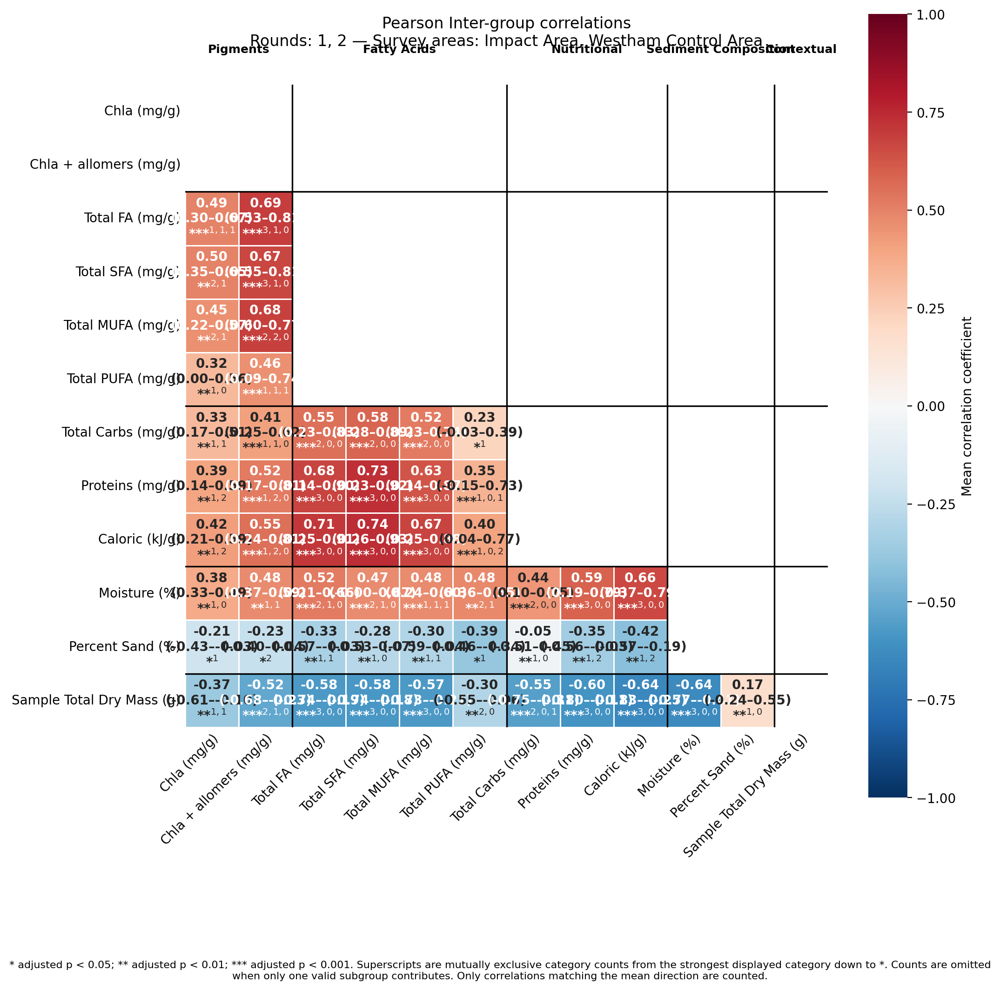

/tmp/ipykernel_31906/2131580677.py:51: UserWarning: Pooled analytic p-values treat rows as independent. Repeated stations across rounds can violate that assumption; interpret these stars cautiously.
  results, fig, ax = draw_grouped_correlation_heatmap(


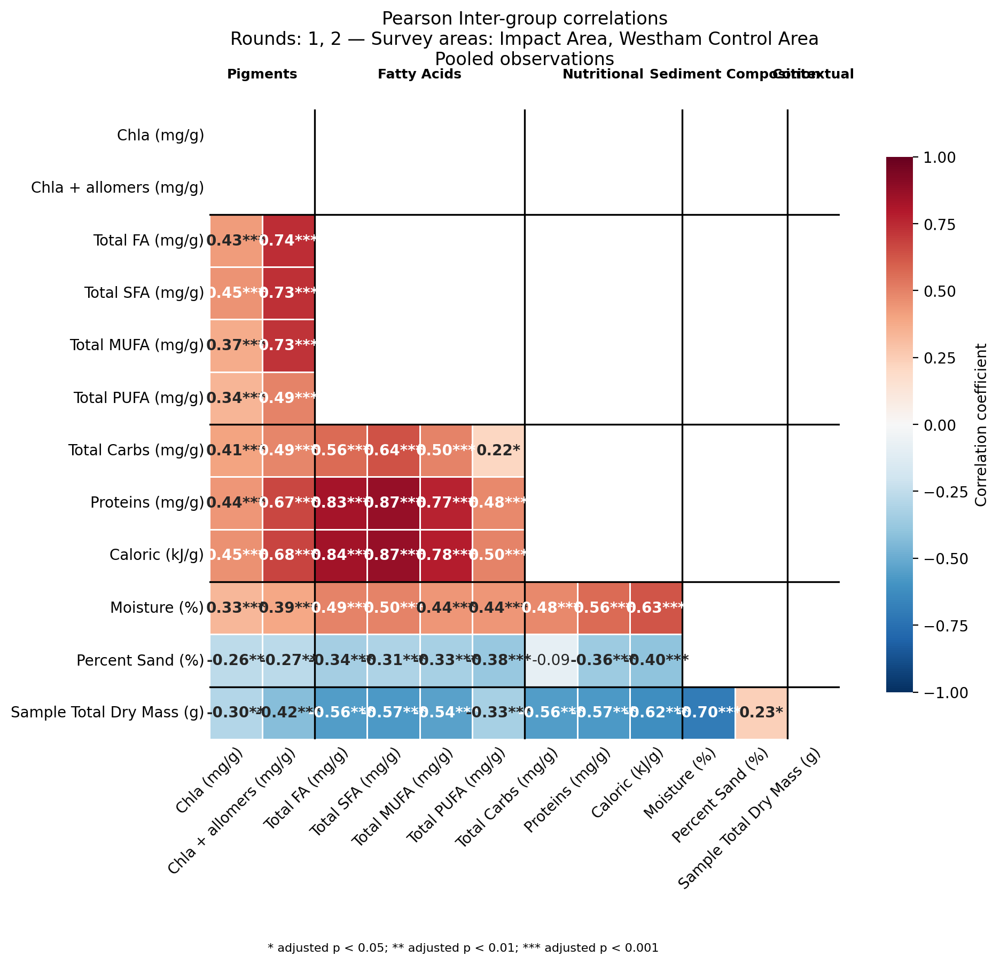

In [33]:
inter_corr_groups_columns = {
    "Pigments": [
        f"Chla ({pigment_unit})",
        f"{NORMALIZING_CHLA_COLUMN} ({pigment_unit})",
    ],
    "Fatty Acids": [
        f"Total FA ({fa_unit})",
        f"Total SFA ({fa_unit})",
        f"Total MUFA ({fa_unit})",
        f"Total PUFA ({fa_unit})",
    ],
    "Nutritional": [
        f"Total Carbs ({fa_unit})",
        f"Proteins ({fa_unit})",
        f"Caloric (kJ/g)",
    ],
    "Sediment Composition": [
        "Moisture (%)",
        "Percent Sand (%)",
    ],
    "Contextual": [
        "Sample Total Dry Mass (g)",
    ],
}

round_number = [1, 2]
site = ["brunswick", "westham"]

results, fig, ax = draw_grouped_correlation_heatmap(
    df=df_lab_r,
    variable_groups=inter_corr_groups_columns,
    round_number=round_number,
    survey_area=None,
    sites=SITES,
    site_labels=SITE_LABELS,
    calculation="independent",
    comparison_scope="intergroup",
    independent_annotation="range",
    method="pearson",
    calculate_significance=True,
    p_adjust="fdr_bh",
    mask_upper=True,
    show_diagonal=False,
)
path = (
    path_output_dir
    / f"correlation_heatmap_core_inter_categories_independent_round{_list_to_str(round_number)}_site{_list_to_str(site)}.png"
)
fig.savefig(path, dpi=300, bbox_inches="tight")

results, fig, ax = draw_grouped_correlation_heatmap(
    df=df_lab_r,
    variable_groups=inter_corr_groups_columns,
    round_number=round_number,
    survey_area=None,
    sites=SITES,
    site_labels=SITE_LABELS,
    calculation="pooled",
    comparison_scope="intergroup",
    method="pearson",
    calculate_significance=True,
    pooled_pvalue_method="analytic",
    p_adjust="fdr_bh",
    mask_upper=True,
    show_diagonal=False,
)
path = (
    path_output_dir
    / f"correlation_heatmap_core_inter_categories_pooled_round{_list_to_str(round_number)}_site{_list_to_str(site)}.png"
)
fig.savefig(path, dpi=300, bbox_inches="tight")


# END